# SOC-Agent v3 — local workstation edition (review experiments)

**Pipeline:** clean → split → train-only feature pipeline → XGBoost / RF / DNN → SHAP → generalisation tests → ATT&CK RAG → mixed alert cohort → multi-agent runs (repeated + ablations) → evaluation → model comparison on the same alerts → blinded expert sheets → cross-dataset test

Same experiments as the Colab and Kaggle v2 notebooks. Differences: everything lives on the local SSD under `~/SOC_Agent` (change with the `SOC_AGENT_HOME` environment variable), every step is cached and every agent run resumes, the LLM is sized to your GPU, and each model's runs are kept in their own folder so several models can be compared on the **same 318 alerts**.

### What v3 adds (requested by the review)
| Review point | What the notebook now does | Cell |
|---|---|---|
| SHAP effect not isolated | Every condition shows the **same raw measurements**; conditions add only: nothing (`raw`), the detector output (`pred`), genuine SHAP (`pred_shap`), shuffled SHAP from another alert (`pred_shuffled`), SHAP with explicit wording (`pred_shap_explicit`), or an inverted detector output (`flipped`). Two prompt phrasings (P1, P2). 3 seeds, majority vote. | 13, 14, 15, 16c |
| Tuned detector threshold | Thresholds on P(attack) selected on the **dev pool** (test rows not in the cohort): matched recall, matched workload, per-class thresholds; paired tests vs. the agent | 16d |
| Small cohort / statistics | Cohort extended to 200 detector FPs, 100 hard benign and **all** misses; design-weighted population estimates; stratified and episode (cluster) bootstrap CIs for ΔF1/Δrecall/ΔFPR; Holm correction | 13, 16c |
| Agents under distribution shift | The frozen conditions run on a cohort of the 2017 detector's errors on **CSE-CIC-IDS2018** | 18b |
| Routing of missed attacks | Explicit queues (flagged only / flagged + grey zone P(attack) ≥ 0.05) evaluated on the whole test set: workload, GPU hours, end-to-end recall | 16e |
| Capacity claim | `run_all_models.sh` runs every model on the **same** alerts and conditions (Qwen2.5 3B/7B/14B/32B, Phi-4-mini, Phi-4, Llama-3.1-8B) | 16f |
| Possible label leakage | No alert ID, stratum or label is in any prompt; exact serialized prompts and an automatic leakage check are written to `results/logs/serialized_prompts_v3.md` | 14 |

### Run all models (recommended for the paper)
```bash
cd ~/soc_agent_v3 && tmux new -s soc
bash run_all_models.sh        # primary model first (v2 + v3), then the others (v3 only)
```
Approximate time on the RTX 5000 Ada: Qwen2.5-14B ~8–9 h (first run, includes the v2 extension and full-pipeline runs), 7B ~2 h, 3B / Phi-4-mini ~1 h each, Phi-4 ~4 h, Llama-3.1-8B ~2 h, Qwen2.5-32B ~12 h (optional). Every run resumes after an interruption.

### One-time setup
```bash
cd ~/soc_agent_v3                    # the folder with this notebook and the scripts
bash setup_env.sh                    # checks the NVIDIA driver, creates ~/soc-agent-env, installs CUDA torch + packages
```

### Optional: reuse the Kaggle run
Copy the Kaggle results zip to `~/SOC_Agent/input/SOC_Agent_results_v2.zip` **before the first run**. Cell 1 imports its cohort and alert packets (so the new model is tested on exactly the same alerts) and files its Qwen2.5-7B runs under `results/agent_runs/Qwen2.5-7B-Instruct/`. Cell 13 checks that the cohort matches this machine's test split before reusing it.

### Run
- **Unattended (recommended for the full run):**
  ```bash
  tmux new -s soc                    # survives SSH disconnects; detach with Ctrl-b then d
  bash run_notebook.sh               # executes all cells, writes a log and an executed copy
  ```
  Re-attach with `tmux attach -t soc`. If it stops for any reason, run `bash run_notebook.sh` again: finished steps are loaded from cache and finished alerts are skipped.
- **Interactive:** `source ~/soc-agent-env/bin/activate && jupyter lab`, open this notebook, choose the kernel **SOC-Agent (local)**, run all.
- **Dry run first (optional, ~1 h):** in Cell 2 set `CFG['agents']['backend'] = 'mock'`. Mock outputs are not results; delete `~/SOC_Agent/results/agent_runs/mock/` afterwards.

### Approximate time on an RTX 5000 Ada (32 GB), 24-core CPU
| Part | Time |
|---|---|
| Cleaning, features, XGBoost (GPU), Random Forest (24 cores), DNN, SHAP | 30–60 min |
| Temporal split + leave-one-day-out | 20–40 min |
| Agent runs, Qwen2.5-14B 4-bit, batch 16: ~318 alerts × (3 seeds + 3 ablations) | roughly 2–4 h |
| Cross-dataset (CIC-IDS2018, ~7 GB download the first time) | 10–20 min + download |

### Running a second model on the same alerts
Change `LLM_MODEL` in Cell 2 (e.g. `'Qwen/Qwen2.5-7B-Instruct'`, `'Qwen/Qwen2.5-32B-Instruct'` with `LLM_BATCH = 4`) and run again. Only the agent runs are new; Cell 16b prints all models side by side.

### Still needs people
Two security analysts to review `gold_techniques_template.csv` and `severity_rubric_template.csv` and to rate `expert_rating_sheet.csv` (instructions in `INSTRUCTIONS_for_raters.md`, all in `~/SOC_Agent/results/expert_eval/`). Put their files (`gold_techniques_expert.csv`, `severity_rubric_expert.csv`, `expert_ratings_<name>.csv`) anywhere under `~/SOC_Agent/input/` and run again.


In [1]:
# ============================================================
# CELL 0 — Environment check (run setup_env.sh once before opening this notebook)
# ============================================================
# Installs anything still missing into THIS Python environment. torch is never
# installed here (it must come from setup_env.sh with the right CUDA build).
import subprocess, sys, importlib

need = {  # import name -> pip spec
    'pandas': 'pandas>=2.0', 'numpy': 'numpy>=1.24', 'scipy': 'scipy>=1.11',
    'sklearn': 'scikit-learn>=1.4', 'xgboost': 'xgboost>=2.0', 'imblearn': 'imbalanced-learn>=0.12',
    'pyarrow': 'pyarrow>=14.0', 'joblib': 'joblib>=1.3', 'tqdm': 'tqdm>=4.66', 'requests': 'requests>=2.31',
    'psutil': 'psutil', 'packaging': 'packaging',
    'transformers': 'transformers>=4.43', 'accelerate': 'accelerate>=0.33', 'bitsandbytes': 'bitsandbytes>=0.43',
    'huggingface_hub': 'huggingface_hub>=0.23', 'sentence_transformers': 'sentence-transformers>=2.7',
    'faiss': 'faiss-cpu>=1.7', 'shap': 'shap>=0.44', 'matplotlib': 'matplotlib>=3.8', 'seaborn': 'seaborn>=0.13',
    'kagglehub': 'kagglehub',
}
missing = []
for mod, spec in need.items():
    try:
        importlib.import_module(mod)
    except Exception:
        missing.append(spec)
if missing:
    print('Installing missing packages:', missing)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + missing, check=True)

import torch
print(f'Python {sys.version.split()[0]} | torch {torch.__version__} | CUDA build {torch.version.cuda}')
if not torch.cuda.is_available():
    print('⚠️  torch cannot see the GPU. Check `nvidia-smi`, then re-run setup_env.sh '
          '(it installs the CUDA build of torch). CPU-only is far too slow for the LLM runs.')
else:
    for i in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(i)
        print(f'GPU {i}: {p.name}  {p.total_memory / 1024**3:.1f} GB  '
              f'(compute capability {p.major}.{p.minor}, bf16: {torch.cuda.is_bf16_supported()})')
print('✅ Environment ready')


/home/jiit_255030001/soc-agent-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.11.15 | torch 2.5.1+cu121 | CUDA build 12.1
GPU 0: NVIDIA A100-SXM4-80GB  79.2 GB  (compute capability 8.0, bf16: True)
✅ Environment ready


In [2]:
# ============================================================
# CELL 1 — Local paths (+ optional import of earlier Kaggle results)
# ============================================================
# Everything lives under SOC_AGENT_HOME (default ~/SOC_Agent) on the local SSD:
#   input/     datasets (downloaded automatically, or put your own CSVs here)
#   cache/     cleaned data, splits, models, LLM weights (re-creatable)
#   results/   tables, figures, logs, agent runs, expert sheets (keep these)
# Because the disk is persistent, every expensive step is cached and every
# agent run resumes where it stopped (after a crash, reboot or Ctrl-C).
import os, shutil, json, zipfile
from pathlib import Path

IN_COLAB, IN_KAGGLE = False, False
HOME  = Path(os.environ.get('SOC_AGENT_HOME', Path.home() / 'SOC_Agent')).expanduser()
BASE  = HOME
CACHE = HOME / 'cache'
INPUT = HOME / 'input'

PATHS = {
    'data_cleaned':    CACHE / 'data/cleaned',
    'data_processed':  CACHE / 'data/processed',
    'data_splits':     CACHE / 'data/splits',
    'models':          CACHE / 'models',
    'hf_cache':        CACHE / 'hf_cache',
    'knowledge_base':  BASE / 'knowledge_base',
    'results_figures': BASE / 'results/figures',
    'results_tables':  BASE / 'results/tables',
    'results_logs':    BASE / 'results/logs',
    'results_runs':    BASE / 'results/agent_runs',     # one sub-folder per LLM
    'results_expert':  BASE / 'results/expert_eval',
    'workers':         BASE / 'workers',
}
for p in list(PATHS.values()) + [INPUT]:
    p.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('HF_HOME', str(PATHS['hf_cache']))   # model downloads go to the local cache

# ---- Optional: reuse the Kaggle run (same 318 alerts -> paired model comparison)
# Put the Kaggle results zip at input/SOC_Agent_results_v2.zip. Its cohort and
# alert packets are reused, and its agent runs are filed under the model that
# produced them, next to the runs this machine will add.
KAGGLE_ZIP = INPUT / 'SOC_Agent_results_v2.zip'
if KAGGLE_ZIP.exists() and not (PATHS['results_logs'] / '.kaggle_imported').exists():
    with zipfile.ZipFile(KAGGLE_ZIP) as z:
        names = z.namelist()
        man = json.loads(z.read('logs/run_manifest.json')) if 'logs/run_manifest.json' in names else {}
        k_model = (man.get('llm', {}) or {}).get('model_id') or man.get('config', {}).get('agents', {}).get('hf_model', 'unknown_model')
        slug = k_model.split('/')[-1]
        n = 0
        for nm in names:
            if nm in ('logs/cohort.csv', 'logs/alerts.json'):
                (PATHS['results_logs'] / Path(nm).name).write_bytes(z.read(nm)); n += 1
            elif nm.startswith('agent_runs/') and nm.endswith('.json'):
                d = PATHS['results_runs'] / slug; d.mkdir(parents=True, exist_ok=True)
                (d / Path(nm).name).write_bytes(z.read(nm)); n += 1
            elif nm.startswith('expert_eval/') and not nm.endswith('/'):
                (PATHS['results_expert'] / Path(nm).name).write_bytes(z.read(nm)); n += 1
    (PATHS['results_logs'] / '.kaggle_imported').write_text(k_model)
    print(f'↻ Imported {n} files from the Kaggle run (agent runs filed under {slug}/)')

# ---- Expert files placed anywhere under input/ are copied into results/expert_eval/
for pat in ['gold_techniques_expert.csv', 'severity_rubric_expert.csv', 'expert_ratings_*.csv']:
    for f in INPUT.rglob(pat):
        shutil.copy2(f, PATHS['results_expert'] / f.name); print(f'✅ expert file: {f.name}')

if os.environ.get('HF_TOKEN'):
    print('✅ HF_TOKEN found in the environment')
print(f'📁 Project folder: {HOME}')


✅ HF_TOKEN found in the environment
📁 Project folder: /home/jiit_255030001/SOC_Agent


In [3]:
# ============================================================
# CELL 2 — GPU detection + master configuration (local workstation)
# ============================================================
# Every setting that changes a reported number lives in CFG, and CFG is
# written to results/logs/run_manifest.json so the paper can cite it.
import torch

GPU_AVAILABLE = torch.cuda.is_available()
N_GPUS = torch.cuda.device_count() if GPU_AVAILABLE else 0
GPU_NAME = torch.cuda.get_device_name(0) if GPU_AVAILABLE else ''
GPU_VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1024**3 if GPU_AVAILABLE else 0.0
GPU_TIER = 'local'
print(f'GPUs: {N_GPUS} x {GPU_NAME or "none"} ({GPU_VRAM_GB:.1f} GB each)')

# ── LLM for the agents. 'auto' picks by GPU memory (4-bit NF4 weights):
#    >= 30 GB (e.g. RTX 5000 Ada 32 GB): Qwen2.5-14B-Instruct, batch 16  (~10 GB weights)
#    >= 20 GB                          : Qwen2.5-14B-Instruct, batch 8
#    >= 14 GB                          : Qwen2.5-7B-Instruct,  batch 8
# Set LLM_MODEL explicitly to run another model on the SAME alerts, e.g.
#   'Qwen/Qwen2.5-7B-Instruct'   (to match the Kaggle run)
#   'Qwen/Qwen2.5-32B-Instruct'  (~19 GB in 4-bit; fits 32 GB with LLM_BATCH = 4)
#   'meta-llama/Llama-3.1-8B-Instruct' (gated: needs HF_TOKEN and accepting the licence)
# Each model's runs are stored in results/agent_runs/<model>/ and evaluated separately.
import os
LLM_MODEL = os.environ.get('SOC_LLM_MODEL', 'auto')   # run_all_models.sh sets SOC_LLM_MODEL
LLM_BATCH = int(os.environ['SOC_LLM_BATCH']) if os.environ.get('SOC_LLM_BATCH') else None   # None = automatic
if LLM_MODEL == 'auto':
    LLM_MODEL = 'Qwen/Qwen2.5-14B-Instruct' if GPU_VRAM_GB >= 20 else 'Qwen/Qwen2.5-7B-Instruct'
if LLM_BATCH is None:
    LLM_BATCH = (4 if '32B' in LLM_MODEL else 16 if GPU_VRAM_GB >= 30 else 8)
MODEL_SLUG = LLM_MODEL.split('/')[-1]

# benign_cap = BENIGN rows kept before SMOTE; SMOTE raises every class to this
# count, so the resampled training set has 15 x benign_cap rows (paper: 500,000).
P = dict(xgb_trees=500, dnn_epochs=50, batch=8192, benign_cap=500_000, shap_n=5000, n_workers=0)
if not GPU_AVAILABLE:
    P = dict(xgb_trees=200, dnn_epochs=10, batch=512, benign_cap=100_000, shap_n=1000, n_workers=0)

CFG = {
    'random_seed': 42,

    # ── Data accounting / cleaning ───────────────────────────────────────────
    'data': {
        'dedup': True,          # drop exact duplicate flows (same features + label)
    },
    'preprocessing': {
        'drop_always_null': [
            'Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk',
            'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate',
            'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate',
        ],
        'drop_leaky': ['Flow ID', 'Source IP', 'Src IP', 'Destination IP',
                       'Dst IP', 'Timestamp', 'Source Port', 'Src Port'],
        'correlation_threshold': 0.95,
        'corr_sample': 500_000,   # rows of the TRAINING set used for the correlation matrix
    },

    # ── Split ────────────────────────────────────────────────────────────────
    # 'random'   : stratified random 80/20 split (the paper's main setting)
    # 'temporal' : within every (day-file, class) group, the earliest 80% of
    #              flows train and the latest 20% test, with a purge gap
    'split': {'mode': 'random', 'test_size': 0.2, 'stratify': True,
              'temporal_purge_frac': 0.02},

    # ── Features ─────────────────────────────────────────────────────────────
    # 'paper' : duration bucket + port category + service one-hots (the 33-feature
    #           configuration evaluated in the paper)
    # 'full'  : additionally protocol one-hots, payload category, fwd/bwd ratio,
    #           TCP-flag indicators and byte-rate z-score
    'features': {
        'profile':   'paper',
        'mi_top_k':  30,
        'xgb_top_k': 25,
        'mi_sample': 200_000,
        'port_service_map': {
            21: 'FTP', 22: 'SSH', 23: 'Telnet', 25: 'SMTP', 53: 'DNS',
            80: 'HTTP', 110: 'POP3', 143: 'IMAP', 443: 'HTTPS', 993: 'IMAPS',
            3306: 'MySQL', 3389: 'RDP', 5432: 'PostgreSQL', 8080: 'HTTP-Alt',
        },
    },

    'resampling': {'benign_cap': P['benign_cap'], 'smote_k_neighbors': 5},

    'models': {
        'xgboost': {'n_estimators': P['xgb_trees'], 'max_depth': 8, 'learning_rate': 0.05,
                    'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 5,
                    'use_gpu': GPU_AVAILABLE},
        'random_forest': {'n_estimators': 200, 'max_depth': 20,
                          'class_weight': 'balanced', 'n_jobs': -1},
        'dnn': {'hidden_layers': [256, 128, 64], 'dropout': [0.3, 0.2, 0.0],
                'learning_rate': 1e-3, 'weight_decay': 1e-5,
                'batch_size': P['batch'], 'epochs': P['dnn_epochs'],
                'use_gpu': GPU_AVAILABLE, 'num_workers': P['n_workers'],
                'pin_memory': GPU_AVAILABLE},
    },

    'shap': {'sample_size': P['shap_n']},

    # ── LLM agents ───────────────────────────────────────────────────────────
    'agents': {
        # 'huggingface' (local GPU) | 'groq' | 'anthropic' | 'mock' (dry run, no LLM)
        'backend':      'huggingface',
        'hf_model':     LLM_MODEL,
        'hf_revision':  None,     # set a commit hash to pin the exact weights
        'hf_use_4bit':  True,
        'temperature':  0.01,     # <= 0 means greedy decoding
        'top_p':        0.95,
        'max_new_tokens': {'triage': 256, 'investigation': 640,
                           'response': 512, 'coordinator': 640},
        'batch_size':   LLM_BATCH,        # alerts generated together per stage, per GPU
        'n_gpu_workers': max(1, N_GPUS),  # one model copy + worker process per GPU
        'compute_dtype': 'auto',          # bfloat16 where supported (Ada), else float16
        'max_retries':  1,                # re-asks after malformed / schema-invalid JSON
        'groq_model':   'llama-3.1-8b-instant',
        'anthropic_model': 'claude-haiku-4-5-20251001',
    },

    # ── Agent evaluation cohort (drawn from the classifier TEST set) ─────────
    # S1 attack flows the detector flags (true positives), stratified per class
    # S2 benign flows the detector flags (real ML false positives)
    # S3 'hard benign': benign flows NOT flagged, but with P(attack) >= threshold
    # S4 attack flows the detector misses (false negatives)
    'cohort': {
        'attack_per_class':    15,
        'ml_false_positives':  80,
        'hard_benign':         40,
        'ml_misses':           20,
        'hard_benign_min_attack_prob': 0.05,
    },

    # ── Experiments ──────────────────────────────────────────────────────────
    'experiments': {
        'run_seeds': [42, 43, 44],          # repeated runs of the full system
        # LLM ablations (each is one extra run with seed 42). 'triage_only' and
        # 'no_coordinator' are scored from the full-system outputs, no extra calls.
        'llm_ablations': ['no_rag', 'no_shap', 'no_investigation'],
        'latency_probe_n': 20,              # alerts timed one-at-a-time (batch = 1)
        'threshold_ids_conf': 0.5,
    },

    # ── MITRE ATT&CK knowledge base (version pinned for reproducibility) ─────
    'rag': {
        'attck_version':   '17.1',
        'attck_url':       'https://raw.githubusercontent.com/mitre-attack/attack-stix-data/'
                           'master/enterprise-attack/enterprise-attack-{ver}.json',
        'embedding_model': 'sentence-transformers/all-MiniLM-L6-v2',
        'top_k_retrieval': 5,
    },

    # ── v3: experiments requested by the review ─────────────────────────────
    #   * cohort extension: more detector false positives / hard benign / ALL misses
    #   * controlled explanation conditions with the SAME raw measurements:
    #       raw (measurements only) | pred (+ detector output) | pred_shap (+ genuine SHAP)
    #       pred_shuffled (+ SHAP from another alert on random features)
    #       pred_shap_explicit (genuine SHAP, wording that says what SHAP means)
    #       flipped (+ detector output with the decision inverted)
    #   * two prompt phrasings (P1, P2) for robustness
    #   * validation-selected detector thresholds, routing policy, shifted-detector cohort
    'v3': {
        'enabled': True,
        'cohort_extension': {'S2_ml_false_positive': 200, 'S3_hard_benign': 100, 'S4_ml_miss': 'all'},
        'conditions': ['raw', 'pred', 'pred_shap', 'pred_shuffled', 'pred_shap_explicit', 'flipped'],
        'control_seeds': [42, 43, 44],
        'p2_conditions': ['raw', 'pred', 'pred_shap'],
        'full_pipeline_conditions': ['pred', 'pred_shap'] if os.environ.get('SOC_V3_ONLY', '0') != '1' else [],
        # Original v2 runs (full x3 seeds + ablations) are extended to the new alerts.
        # SOC_V3_ONLY=1 (set by run_all_models.sh for extra models) skips them.
        'run_v2_runs': os.environ.get('SOC_V3_ONLY', '0') != '1',
        'routing_grey_zone': 0.05,          # P(attack) lower bound of the extended review queue
        'episode_block': 500,               # flows per capture-order block (cluster bootstrap)
        'dev_fraction_note': 'thresholds are selected on test rows NOT in the cohort',
        'shift': {'enabled': True, 'attack_per_class': 10, 'S2_ml_false_positive': 100,
                  'S3_hard_benign': 50, 'S4_ml_miss': 100,
                  'conditions': ['raw', 'pred', 'pred_shap', 'pred_shap_explicit'], 'seeds': [42]},
    },

    'evaluation': {'dpi': 300, 'font_size': 12, 'bootstrap': 1000,
                   'expert_sheet_attacks': 40, 'expert_sheet_benign': 20},
}

print(f'\n✅ Configuration ready  (agent runs -> results/agent_runs/{MODEL_SLUG}/)')
print(f'   LLM        : {CFG["agents"]["backend"]} / {CFG["agents"]["hf_model"]}  '
      f'(x{CFG["agents"]["n_gpu_workers"]} GPU workers, batch {LLM_BATCH})')
print(f'   Split      : {CFG["split"]["mode"]}  |  features: {CFG["features"]["profile"]}'
      f'  |  dedup: {CFG["data"]["dedup"]}')
print(f'   Benign cap : {P["benign_cap"]:,}')
print(f'   Runs       : seeds {CFG["experiments"]["run_seeds"]}  |  ablations '
      f'{CFG["experiments"]["llm_ablations"]}')


GPUs: 1 x NVIDIA A100-SXM4-80GB (79.2 GB each)

✅ Configuration ready  (agent runs -> results/agent_runs/phi-4/)
   LLM        : huggingface / microsoft/phi-4  (x1 GPU workers, batch 16)
   Split      : random  |  features: paper  |  dedup: True
   Benign cap : 500,000
   Runs       : seeds [42, 43, 44]  |  ablations ['no_rag', 'no_shap', 'no_investigation']


In [4]:
# ============================================================
# CELL 3 — Datasets: use local CSVs if present, otherwise download from Kaggle
# ============================================================
#   CIC-IDS2017     : chethuhn/network-intrusion-dataset   (~0.9 GB of CSVs)
#   CSE-CIC-IDS2018 : solarmainframe/ids-intrusion-csv      (~7 GB; only for Cell 18)
# Downloads go to input/kagglehub/. If kagglehub asks for credentials, create a
# Kaggle API token (kaggle.com -> Settings -> API -> Create New Token) and save
# it as ~/.kaggle/kaggle.json (chmod 600). Or download the datasets yourself and
# unzip them anywhere under input/ — they are found automatically.
# Only ONE folder of CSVs per dataset is used (no double loading).
import re
from collections import defaultdict

DOWNLOAD_2018 = True        # False = skip the cross-dataset test (saves ~7 GB)
os.environ.setdefault('KAGGLEHUB_CACHE', str(INPUT / 'kagglehub'))

def _is_2017(f):
    return bool(re.search(r'(WorkingHours|pcap_ISCX)', f.name, re.I))

def _is_2018(f):
    return (not _is_2017(f)) and bool(re.search(r'(TrafficForML|2018)', str(f), re.I))

def find_csv_dir(root, pred, prefer=None):
    """Folder holding the most CSVs that match `pred` (prefer paths containing `prefer`)."""
    groups = defaultdict(list)
    results_dir = str(BASE / 'results')
    for f in Path(root).rglob('*.csv'):
        if not str(f).startswith(results_dir) and pred(f):      # never pick up our own result tables
            groups[f.parent].append(f)
    if not groups:
        return None
    return sorted(groups, key=lambda d: (prefer is not None and prefer.lower() in str(d).lower(),
                                         len(groups[d]), -len(str(d))), reverse=True)[0]

def _kaggle_download(slugs, pred, prefer=None):
    import kagglehub
    for slug in slugs:
        try:
            print(f'  downloading {slug} ...')
            d = find_csv_dir(Path(kagglehub.dataset_download(slug)), pred, prefer)
            if d:
                return d
        except Exception as e:
            print(f'  {slug}: {e}')
    return None

RAW_DIRS = {'cic-ids-2017': find_csv_dir(INPUT, _is_2017, prefer='MachineLearning'),
            'cic-ids-2018': find_csv_dir(INPUT, _is_2018)}
if RAW_DIRS['cic-ids-2017'] is None:
    RAW_DIRS['cic-ids-2017'] = _kaggle_download(['chethuhn/network-intrusion-dataset', 'cicdataset/cicids2017'],
                                                _is_2017, prefer='MachineLearning')
if RAW_DIRS['cic-ids-2018'] is None and DOWNLOAD_2018:
    RAW_DIRS['cic-ids-2018'] = _kaggle_download(['solarmainframe/ids-intrusion-csv'], _is_2018)
if RAW_DIRS['cic-ids-2017'] is None:
    raise FileNotFoundError('CIC-IDS2017 not found. Set up ~/.kaggle/kaggle.json, or download '
                            '"network-intrusion-dataset" (chethuhn) from Kaggle and unzip it under '
                            f'{INPUT}')

print('=' * 70)
for k, d in RAW_DIRS.items():
    if d is None:
        print(f'  {k:<13} not available' + ('  (cross-dataset Cell 18 will be skipped)' if k.endswith('2018') else ''))
    else:
        fs = sorted(Path(d).glob('*.csv'))
        print(f'  {k:<13} {len(fs)} CSVs, {sum(f.stat().st_size for f in fs) / 1e9:.2f} GB  <- {d}')
print('=' * 70)


  cic-ids-2017  8 CSVs, 0.88 GB  <- /home/jiit_255030001/SOC_Agent/input/kagglehub/datasets/chethuhn/network-intrusion-dataset/versions/1
  cic-ids-2018  10 CSVs, 6.89 GB  <- /home/jiit_255030001/SOC_Agent/input/kagglehub/datasets/solarmainframe/ids-intrusion-csv/versions/1


In [5]:
# ============================================================
# CELL 4 — Agent library + per-GPU worker script
# ============================================================
# The agent code (JSON parsing + schema validation, LLM engines, prompts, the
# batched runner, ATT&CK retrieval) is written to ~/SOC_Agent/workers/ as a small
# Python module. Cell 15 starts one worker process per GPU (one on this
# workstation), which loads the LLM, so the notebook kernel stays light.
LIB_SRC = r'''"""SOC-Agent agent library (written by the notebook; used by the notebook and by
the per-GPU worker processes). JSON parsing + schema validation, LLM engines,
prompts, the batched multi-agent runner, and ATT&CK retrieval."""
import os, re, json, time, copy, random, hashlib
import numpy as np


def set_global_seed(seed):
    import torch
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    try:
        from transformers import set_seed as _s
        _s(seed)
    except Exception:
        pass


# ── Robust JSON extraction ─────────────────────────────────────────────────
def _try_parse(s):
    try:
        return json.loads(s)
    except Exception:
        return None

def _find_matching_brace(text, start):
    depth, in_str, esc = 0, False, False
    for i in range(start, len(text)):
        c = text[i]
        if esc:
            esc = False; continue
        if c == '\\' and in_str:
            esc = True; continue
        if c == '"':
            in_str = not in_str; continue
        if in_str:
            continue
        if c == '{':
            depth += 1
        elif c == '}':
            depth -= 1
            if depth == 0:
                return i
    return -1

def extract_json(text):
    """Return the first JSON object found in `text`, or None."""
    text = re.sub(r'```(?:json)?\s*', '', str(text)).strip()
    p = _try_parse(text)
    if isinstance(p, dict):
        return p
    s = text.find('{')
    e = _find_matching_brace(text, s) if s >= 0 else -1
    if s >= 0 and e > s:
        p = _try_parse(text[s:e + 1])
        if isinstance(p, dict):
            return p
    return None


# ── Output schemas ─────────────────────────────────────────────────────────
SEV_LEVELS = ['Informational', 'Low', 'Medium', 'High', 'Critical']
_SEV_ALIASES = {s.lower(): s for s in SEV_LEVELS}
_SEV_ALIASES.update({'info': 'Informational', 'none': 'Informational', 'crit': 'Critical'})

def _as_bool(v):
    if isinstance(v, bool):
        return v
    if isinstance(v, str) and v.strip().lower() in ('true', 'yes', '1'):
        return True
    if isinstance(v, str) and v.strip().lower() in ('false', 'no', '0'):
        return False
    return None

def _as_sev(v):
    return _SEV_ALIASES.get(str(v).strip().lower()) if v is not None else None

def _as_str_list(v):
    if v is None:
        return None
    if isinstance(v, str):
        return [v]
    if isinstance(v, list):
        return [x if isinstance(x, str) else json.dumps(x) for x in v]
    return None

def _as_tech_ids(v):
    if v is None:
        return None
    out = []
    for x in (v if isinstance(v, list) else [v]):
        tid = x.get('id', '') if isinstance(x, dict) else str(x)
        m = re.search(r'T\d{4}(?:\.\d{3})?', str(tid).upper())
        if m:
            out.append(m.group(0))
    return out

def validate_output(stage, obj):
    """Return (normalised_obj, list_of_errors). Empty error list = valid."""
    if not isinstance(obj, dict):
        return None, ['not a JSON object']
    o, err = dict(obj), []
    def need(key, conv, label):
        val = conv(o.get(key))
        if val is None:
            err.append(f'{key}: {label}')
        else:
            o[key] = val
    if stage == 'triage':
        need('severity', _as_sev, 'one of ' + '|'.join(SEV_LEVELS))
        need('escalate', _as_bool, 'boolean')
        o['reasoning'] = str(o.get('reasoning', ''))
    elif stage == 'investigation':
        techs = o.get('techniques')
        ids = _as_tech_ids(techs)
        if ids is None:
            err.append('techniques: list')
        else:
            names = {}
            if isinstance(techs, list):
                for t in techs:
                    if isinstance(t, dict) and t.get('id'):
                        names[str(t['id']).upper()] = {'name': t.get('name', ''), 'tactic': t.get('tactic', '')}
            o['techniques'] = [{'id': i, **names.get(i, {'name': '', 'tactic': ''})} for i in ids]
        need('evidence', _as_str_list, 'list of strings')
        o['gaps'] = _as_str_list(o.get('gaps')) or []
        conf = str(o.get('confidence', '')).lower()
        o['confidence'] = conf if conf in ('high', 'medium', 'low') else 'unknown'
        need('likely_false_positive', _as_bool, 'boolean')
    elif stage == 'response':
        need('immediate_actions', _as_str_list, 'list of strings')
        need('block_source', _as_bool, 'boolean')
        need('escalate', _as_bool, 'boolean')
        o['mitigation_steps'] = _as_str_list(o.get('mitigation_steps')) or []
        o['block_justification'] = str(o.get('block_justification', ''))
        o['reasoning'] = str(o.get('reasoning', ''))
    elif stage == 'coordinator':
        need('final_severity', _as_sev, 'one of ' + '|'.join(SEV_LEVELS))
        need('escalate', _as_bool, 'boolean')
        disp = str(o.get('disposition', '')).lower().replace(' ', '_')
        if disp not in ('true_positive', 'false_positive', 'uncertain'):
            err.append('disposition: true_positive|false_positive|uncertain')
        o['disposition'] = disp
        need('attck_techniques', _as_tech_ids, 'list of technique IDs')
        need('recommended_actions', _as_str_list, 'list of strings')
        o['executive_summary'] = str(o.get('executive_summary', ''))
    return o, err

# Fallbacks are used only when an output is still invalid after the retries;
# they are counted and reported (output-validity table), never hidden.
FALLBACKS = {
    'triage':        {'severity': 'Medium', 'escalate': True, 'reasoning': ''},
    'investigation': {'techniques': [], 'evidence': [], 'gaps': [], 'confidence': 'unknown',
                      'likely_false_positive': False},
    'response':      {'immediate_actions': [], 'block_source': False, 'block_justification': '',
                      'mitigation_steps': [], 'escalate': True, 'reasoning': ''},
    'coordinator':   {'executive_summary': '', 'final_severity': 'Medium', 'escalate': True,
                      'disposition': 'uncertain', 'attck_techniques': [], 'recommended_actions': []},
}


# ── LLM engines: generate(list_of_message_lists, max_new_tokens) -> [(text, n_tokens)]
class HFEngine:
    """Local HuggingFace model, 4-bit NF4, batched generation with left padding.
    Weights are cached on LOCAL disk; a corrupted cache is deleted and re-downloaded once."""
    def __init__(self, cfg, cache_dir):
        import torch
        from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
        a = cfg['agents']
        self.torch = torch
        self.model_id = a['hf_model']
        self.cache_dir = str(cache_dir); os.makedirs(self.cache_dir, exist_ok=True)
        token = os.environ.get('HF_TOKEN') or None
        gpu = torch.cuda.is_available()
        # bfloat16 on GPUs that support it (Ampere / Ada / Hopper), else float16 (T4)
        cdt = torch.bfloat16 if (gpu and a.get('compute_dtype', 'auto') in ('auto', 'bfloat16')
                                 and torch.cuda.is_bf16_supported()) else torch.float16
        bnb = None
        if a.get('hf_use_4bit', True) and gpu:
            bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                                     bnb_4bit_compute_dtype=cdt,
                                     bnb_4bit_use_double_quant=True)
        print(f'Loading {self.model_id} (4-bit={bnb is not None}) ...', flush=True)
        self.tok = AutoTokenizer.from_pretrained(self.model_id, revision=a.get('hf_revision'),
                                                 token=token, cache_dir=self.cache_dir)
        self.tok.padding_side = 'left'
        if self.tok.pad_token is None:
            self.tok.pad_token = self.tok.eos_token
        import transformers
        from packaging.version import Version
        dkey = 'dtype' if Version(transformers.__version__) >= Version('4.56') else 'torch_dtype'
        kw = dict(revision=a.get('hf_revision'), quantization_config=bnb,
                  device_map={'': 0} if gpu else None, token=token, cache_dir=self.cache_dir,
                  **{dkey: cdt if gpu else torch.float32})
        try:
            self.model = AutoModelForCausalLM.from_pretrained(self.model_id, **kw)
        except Exception as e:
            msg = f'{type(e).__name__}: {e}'
            if not any(k in msg for k in ('Safetensor', 'header', 'metadata', 'EOF', 'corrupt',
                                          'Unable to load weights', 'invalid load key')):
                raise
            print(f'Cached weights look corrupted ({msg[:120]}); re-downloading ...', flush=True)
            import shutil
            shutil.rmtree(os.path.join(self.cache_dir, 'models--' + self.model_id.replace('/', '--')),
                          ignore_errors=True)
            self.model = AutoModelForCausalLM.from_pretrained(self.model_id, force_download=True, **kw)
        self.model.eval()
        self.revision = getattr(self.model.config, '_commit_hash', None) or a.get('hf_revision')
        self.temperature, self.top_p = a['temperature'], a['top_p']
        self.compute_dtype = str(cdt).replace('torch.', '') if gpu else 'float32'
        self.quantization = '4-bit NF4' if bnb is not None else 'none'

    def generate(self, msgs_list, max_new_tokens):
        torch = self.torch
        texts = [self.tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True)
                 for m in msgs_list]
        enc = self.tok(texts, return_tensors='pt', padding=True).to(self.model.device)
        kw = dict(max_new_tokens=max_new_tokens, pad_token_id=self.tok.pad_token_id)
        if self.temperature and self.temperature > 0:
            kw.update(do_sample=True, temperature=self.temperature, top_p=self.top_p)
        else:
            kw.update(do_sample=False)
        with torch.no_grad():
            out = self.model.generate(**enc, **kw)
        gen = out[:, enc['input_ids'].shape[1]:]
        n_tok = (gen != self.tok.pad_token_id).sum(dim=1).tolist()
        return list(zip(self.tok.batch_decode(gen, skip_special_tokens=True), n_tok))


class APIEngine:
    """Groq / Anthropic through LangChain chat models (sequential calls)."""
    def __init__(self, cfg):
        from langchain_core.messages import SystemMessage, HumanMessage
        self._S, self._H = SystemMessage, HumanMessage
        a = cfg['agents']; self.backend = a['backend']
        if a['backend'] == 'groq':
            from langchain_groq import ChatGroq
            self.model_id = a['groq_model']
            self.llm = ChatGroq(model=self.model_id, temperature=max(a['temperature'], 0),
                                api_key=os.environ.get('GROQ_API_KEY', ''))
        else:
            from langchain_anthropic import ChatAnthropic
            self.model_id = a['anthropic_model']
            self.llm = ChatAnthropic(model=self.model_id, temperature=max(a['temperature'], 0))
        self.revision = self.model_id

    def generate(self, msgs_list, max_new_tokens):
        outs = []
        for m in msgs_list:
            lc = [self._S(content=x['content']) if x['role'] == 'system' else self._H(content=x['content'])
                  for x in m]
            r = self.llm.bind(max_tokens=max_new_tokens).invoke(lc)
            txt = r.content if hasattr(r, 'content') else str(r)
            outs.append((txt, len(txt.split())))
            if self.backend == 'groq':
                time.sleep(0.5)
        return outs


class MockEngine:
    """Deterministic rule-based stand-in for a DRY RUN without an LLM.
    Its outputs are NOT results and must never be reported."""
    model_id, revision = 'mock', 'mock'
    _SEV = {'DDoS': 'Critical', 'Infiltration': 'Critical', 'Heartbleed': 'Critical',
            'PortScan': 'Low', 'BENIGN': 'Informational'}
    def generate(self, msgs_list, max_new_tokens):
        outs = []
        for m in msgs_list:
            sysm, user = m[0]['content'], m[-1]['content']
            if '"status"' in user:
                outs.append(('{"status": "ok"}', 5)); continue
            h = int(hashlib.md5(user.encode()).hexdigest(), 16)
            lab = re.search(r'"predicted_label":\s*"([^"]+)"', user)
            lab = lab.group(1) if lab else 'BENIGN'
            conf = re.search(r'"confidence":\s*([0-9.]+)', user)
            conf = float(conf.group(1)) if conf else 0.5
            esc = lab.upper() != 'BENIGN' and (conf > 0.7 or h % 3 == 0)
            sev = self._SEV.get(lab, 'High' if h % 2 else 'Medium') if esc else 'Low'
            ids = re.findall(r'T\d{4}(?:\.\d{3})?', user) or ['T1046']
            if h % 37 == 0 and 'previous reply' not in user:
                outs.append(('Sorry, here is my analysis without JSON.', 9)); continue
            if 'Triage' in sysm[:60]:
                o = {'severity': sev, 'escalate': esc, 'reasoning': 'mock'}
            elif 'Investigation' in sysm[:60]:
                o = {'techniques': [{'id': ids[h % len(ids)], 'name': '', 'tactic': ''}],
                     'evidence': ['confidence field'], 'gaps': [], 'confidence': 'medium',
                     'likely_false_positive': not esc}
            elif 'Response' in sysm[:60]:
                o = {'immediate_actions': ['Review flow'], 'block_source': esc,
                     'block_justification': '', 'mitigation_steps': ['Patch'],
                     'escalate': esc, 'reasoning': 'mock'}
            else:
                o = {'executive_summary': 'mock', 'final_severity': sev, 'escalate': esc,
                     'disposition': 'true_positive' if esc else 'false_positive',
                     'attck_techniques': ids[:1], 'recommended_actions': ['Review']}
            outs.append((json.dumps(o), 40))
        return outs


def make_engine(cfg, cache_dir):
    b = cfg['agents']['backend']
    if b == 'huggingface':
        return HFEngine(cfg, cache_dir)
    if b == 'mock':
        return MockEngine()
    return APIEngine(cfg)


# ── ATT&CK retrieval (FAISS cosine over MiniLM embeddings) ───────────────────
class RAG:
    def __init__(self, kb_dir, embedding_model, top_k):
        import faiss
        from sentence_transformers import SentenceTransformer
        self.faiss = faiss
        self.index = faiss.read_index(os.path.join(kb_dir, 'faiss_index.bin'))
        self.techniques = json.load(open(os.path.join(kb_dir, 'techniques.json')))
        self.embedder = SentenceTransformer(embedding_model)
        self.top_k = top_k

    def query(self, text, top_k=None):
        q = self.embedder.encode([text], convert_to_numpy=True).astype('float32')
        self.faiss.normalize_L2(q)
        sims, idxs = self.index.search(q, top_k or self.top_k)
        T = self.techniques
        return [{'id': T[i]['id'], 'name': T[i]['name'], 'tactics': ', '.join(T[i]['tactics']),
                 'description_snippet': T[i]['description'][:400], 'score': round(float(s), 4)}
                for s, i in zip(sims[0], idxs[0]) if 0 <= i < len(T)]

def build_rag_query(alert):
    """Retrieval query = predicted class + service + flag text (documented in the paper)."""
    q = f"{alert.get('predicted_label', '')} attack on {alert.get('service', alert.get('context', {}).get('service', ''))} service"
    if alert.get('flag_anomaly') not in (None, '', 'None'):
        q += f", TCP flags: {alert['flag_anomaly']}"
    return q


# ── Prompts (exported verbatim for the paper appendix) ──────────────────────
ESCALATE_DEF = ('"escalate": true means forward the alert to a human analyst as a likely real attack; '
                'false means it is most likely a false positive or benign activity and can be closed. '
                'The ML detector can be wrong: judge whether the evidence is consistent with its label.')

PROMPTS = {
'triage': f"""You are a Tier-1 SOC Triage Analyst. Given a structured alert packet produced by a
machine-learning network intrusion detector, assign a severity tier and decide escalation.

Consider: the detector's confidence and attack probability; whether the evidence features
(with their SHAP attributions) are consistent with the predicted attack; the targeted service;
and the TCP flag pattern.
Severity tiers: Critical | High | Medium | Low | Informational.
{ESCALATE_DEF}

Output ONLY valid JSON, no text outside it:
{{"severity": "Critical|High|Medium|Low|Informational", "escalate": true|false,
  "reasoning": "2-3 sentences"}}""",

'investigation': f"""You are a SOC Investigation Analyst. Given an alert, the triage result and MITRE ATT&CK
context, identify the ATT&CK techniques the activity corresponds to.

Rules: list at most 3 techniques, most relevant first; prefer techniques that appear in the
provided ATT&CK context; use exact ATT&CK IDs (e.g. T1499 or T1499.002). Each evidence item must
cite a specific field of the alert packet. If the evidence does not support an attack, set
"likely_false_positive" to true and return an empty technique list.

Output ONLY valid JSON:
{{"techniques": [{{"id": "T1498", "name": "...", "tactic": "..."}}],
  "evidence": ["field: observation"], "gaps": ["missing information"],
  "confidence": "high|medium|low", "likely_false_positive": true|false}}""",

'response': f"""You are a SOC Response Analyst. Based on the alert, triage and investigation, recommend
containment and mitigation. All actions are ADVISORY: a human analyst must approve them.
Recommend blocking the source only when the evidence supports a real attack.
{ESCALATE_DEF}

Output ONLY valid JSON:
{{"immediate_actions": ["action"], "block_source": true|false, "block_justification": "reason",
  "mitigation_steps": ["step"], "escalate": true|false, "reasoning": "2-3 sentences"}}""",

'coordinator': f"""You are the SOC Coordinator. Combine the triage, investigation and response outputs into
the final report for a human analyst. Resolve disagreements between agents explicitly.
{ESCALATE_DEF}
"disposition": "true_positive" (real attack), "false_positive" (benign traffic mislabelled by the
detector) or "uncertain".

Output ONLY valid JSON:
{{"executive_summary": "2-3 sentences", "final_severity": "Critical|High|Medium|Low|Informational",
  "disposition": "true_positive|false_positive|uncertain", "escalate": true|false,
  "attck_techniques": ["T1498"], "recommended_actions": ["action"]}}""",
}
REPAIR = ('Your previous reply was not valid for the required format ({errors}). '
          'Reply again with ONLY a JSON object that follows the schema in the instructions.')

VARIANTS = {
    'full':             dict(rag=True,  shap=True,  investigation=True),
    'no_rag':           dict(rag=False, shap=True,  investigation=True),
    'no_shap':          dict(rag=True,  shap=False, investigation=True),
    'no_investigation': dict(rag=True,  shap=True,  investigation=False),
}
STAGES = ['triage', 'investigation', 'response', 'coordinator']


def _alert_view(alert, v):
    a = copy.deepcopy(alert)
    if not v['shap']:
        a.pop('evidence', None); a.pop('evidence_source', None)
    return a

def _user_msg(stage, st, v):
    A = json.dumps(st['alert'], indent=1)
    T = json.dumps(st.get('triage'), indent=1)
    I = (json.dumps(st['investigation'], indent=1) if st.get('investigation') is not None
         else '(investigation stage disabled)')
    if stage == 'triage':
        return f'Alert packet:\n{A}'
    if stage == 'investigation':
        ctx = (json.dumps(st['rag_hits'], indent=1) if v['rag'] else
               '(no ATT&CK context provided; use your own knowledge of ATT&CK)')
        return f'Alert:\n{A}\n\nMITRE ATT&CK context:\n{ctx}\n\nTriage:\n{T}'
    if stage == 'response':
        return f'Alert:\n{A}\n\nTriage:\n{T}\n\nInvestigation:\n{I}'
    R = json.dumps(st.get('response'), indent=1)
    return f'Alert:\n{A}\n\nTriage:\n{T}\n\nInvestigation:\n{I}\n\nResponse:\n{R}'

def run_stage(stage, states, v, eng, cfg):
    max_new = cfg['agents']['max_new_tokens'][stage]
    msgs = [[{'role': 'system', 'content': PROMPTS[stage]},
             {'role': 'user', 'content': _user_msg(stage, st, v)}] for st in states]
    t0 = time.time(); outs = eng.generate(msgs, max_new); dt = time.time() - t0
    meta = [{'retries': 0, 'out_tokens': n, 'raw': txt[:4000]} for txt, n in outs]
    parsed = [validate_output(stage, extract_json(txt)) for txt, _ in outs]
    for _ in range(cfg['agents']['max_retries']):
        bad = [k for k, (o, e) in enumerate(parsed) if o is None or e]
        if not bad:
            break
        rmsgs = [msgs[k] + [{'role': 'assistant', 'content': outs[k][0]},
                            {'role': 'user', 'content': REPAIR.format(errors='; '.join(parsed[k][1]))}]
                 for k in bad]
        t1 = time.time(); routs = eng.generate(rmsgs, max_new); dt += time.time() - t1
        for k, (txt, n) in zip(bad, routs):
            outs[k] = (txt, n); parsed[k] = validate_output(stage, extract_json(txt))
            meta[k]['retries'] += 1; meta[k]['out_tokens'] += n; meta[k]['raw'] = txt[:4000]
    for st, (o, e), m in zip(states, parsed, meta):
        ok = o is not None and not e
        m.update(valid_first_try=(m['retries'] == 0 and ok), valid=ok, fallback=not ok,
                 errors=e if o is not None else ['no JSON object'])
        st[stage] = o if ok else copy.deepcopy(FALLBACKS[stage])
        st[f'{stage}_meta'] = m
        st[f'{stage}_time'] = dt / len(states)

def run_variant(variant, seed, alert_ids, out_path, alerts, gt, eng, cfg, rag,
                batch_size=None, log=print):
    """Run one system variant over `alert_ids`; resumable (one JSON file per run)."""
    v = VARIANTS[variant]
    bs = batch_size or cfg['agents']['batch_size']
    out_path = str(out_path)
    done = {r['alert_id']: r for r in json.load(open(out_path))} if os.path.exists(out_path) else {}
    todo = [a for a in alert_ids if a not in done]
    batches = [todo[i:i + bs] for i in range(0, len(todo), bs)]
    t_start = time.time()
    for b_i, ids in enumerate(batches):
        set_global_seed(seed * 100_003 + alert_ids.index(ids[0]))   # independent of resume point
        states = [{'alert_id': a, 'variant': variant, 'seed': seed, 'ground_truth': gt[a],
                   'alert': _alert_view(alerts[a], v)} for a in ids]
        try:
            run_stage('triage', states, v, eng, cfg)
            if v['investigation']:
                for st in states:
                    st['rag_hits'] = rag.query(build_rag_query(st['alert'])) if v['rag'] else []
                run_stage('investigation', states, v, eng, cfg)
            else:
                for st in states:
                    st['investigation'] = None; st['investigation_time'] = 0.0
            run_stage('response', states, v, eng, cfg)
            run_stage('coordinator', states, v, eng, cfg)
        except Exception as ex:
            log(f'batch {b_i} failed: {ex}')
            for st in states:
                st['error'] = str(ex)
        for st in states:
            st['total_time'] = sum(st.get(f'{s}_time', 0.0) for s in STAGES)
            done[st['alert_id']] = st
        tmp = out_path + '.tmp'
        with open(tmp, 'w') as f:
            json.dump(list(done.values()), f, default=str)
        os.replace(tmp, out_path)                       # atomic: never a half-written file
        el = time.time() - t_start; n_done = sum(len(b) for b in batches[:b_i + 1])
        eta = el / max(n_done, 1) * (len(todo) - n_done)
        log(f'{variant} seed={seed}: {len(done)}/{len(alert_ids)} alerts '
            f'({el / 60:.1f} min, ETA {eta / 60:.1f} min)')
    return [done[a] for a in alert_ids if a in done]


# =============================================================================
# v3 — CONTROLLED EXPLANATION EXPERIMENTS
# =============================================================================
# A v3 alert packet has separate blocks so that every condition shows the SAME
# raw measurements and only adds / removes detector information:
#   measurements : fixed list of raw flow features (identical in all conditions)
#   context      : service, port category, duration bucket, ports, packet counts
#   detector     : predicted_label, confidence, p_attack
#   flipped      : the detector output with the attack/benign decision inverted
#   shap         : top-5 SHAP attributions for the predicted class (genuine)
#   shap_shuffled: 5 random features with attribution values taken from another
#                  alert (realistic magnitudes, no information about this flow)
# No alert identifier, stratum, or label is ever shown to the model.
CONDITIONS = {
    'raw':           dict(detector=None,      shap=None,       wording=None),
    'pred':          dict(detector='genuine', shap=None,       wording=None),
    'pred_shap':     dict(detector='genuine', shap='genuine',  wording='standard'),
    'pred_shuffled': dict(detector='genuine', shap='shuffled', wording='standard'),
    'pred_shap_explicit': dict(detector='genuine', shap='genuine', wording='explicit'),
    'flipped':       dict(detector='flipped', shap=None,       wording=None),
}

SHAP_NOTE = {
    'standard': 'SHAP (XGBoost, predicted class)',
    'explicit': ("SHAP attributions for the detector's predicted class '{label}'. A positive value "
                 "means the feature pushed the detector TOWARD '{label}', a negative value pushed it "
                 "away. They describe how the detector reached its label; they are not independent "
                 "evidence that the flow is malicious."),
}

def v3_view(packet, condition):
    """Build exactly what the model sees for one condition."""
    c = CONDITIONS[condition]
    view = {'flow_measurements': packet['measurements'], 'flow_context': packet['context']}
    if c['detector'] == 'genuine':
        view['detector_output'] = packet['detector']
    elif c['detector'] == 'flipped':
        view['detector_output'] = packet['flipped']
    if c['shap']:
        attr = packet['shap'] if c['shap'] == 'genuine' else packet['shap_shuffled']
        lab = packet['detector']['predicted_label']
        view['detector_explanation'] = {'method': SHAP_NOTE[c['wording']].format(label=lab),
                                        'attributions': attr}
    return view

_ESC_V3 = ('"escalate": true means forward the flow to a human analyst as a likely real attack; '
           'false means it is most likely benign and can be closed.')
_OUT_V3 = ('Output ONLY valid JSON, no text outside it:\n'
           '{"severity": "Critical|High|Medium|Low|Informational", "escalate": true|false,\n'
           '  "reasoning": "2-3 sentences"}')

def triage_prompt_v3(condition, prompt_set='P1'):
    """Triage system prompt for a condition. P1 and P2 are two independent phrasings
    (prompt-robustness check); both describe only the blocks that are present."""
    c = CONDITIONS[condition]
    has_det, has_shap = c['detector'] is not None, c['shap'] is not None
    if prompt_set == 'P1':
        parts = ['You are a Tier-1 SOC Triage Analyst. You receive the measurements of one network flow']
        if has_det:
            parts[0] += ', the output of a machine-learning intrusion detector'
        if has_shap:
            parts[0] += " and the detector's feature attributions"
        parts[0] += '.'
        parts.append('Decide whether the flow is a likely real attack that must be forwarded to a human '
                     'analyst, and assign a severity tier. Base your judgement on what the measurements show.')
        if has_det:
            parts.append('The detector can be wrong: check whether the measurements are consistent with its output.')
        parts.append('Severity tiers: Critical | High | Medium | Low | Informational.')
        parts.append(_ESC_V3)
        parts.append(_OUT_V3)
        return '\n'.join(parts)
    # P2: different wording and order
    src = ['flow measurements']
    if has_det: src.append('an ML detector verdict')
    if has_shap: src.append('attribution scores for that verdict')
    lines = ['Role: first-line security analyst (SOC Triage, Tier 1).',
             'Input: ' + ', '.join(src) + ' for a single network connection.',
             'Task 1: decide "escalate" (true = send to a human analyst, it is probably an attack; '
             'false = close it, it is probably normal traffic).',
             'Task 2: choose a severity: Critical, High, Medium, Low or Informational.']
    if has_det:
        lines.append('Treat the detector verdict as a hint that may be mistaken, not as a fact.')
    lines.append('Answer with a single JSON object and nothing else, using exactly these keys:')
    lines.append('{"severity": "...", "escalate": true or false, "reasoning": "2-3 sentences"}')
    return '\n'.join(lines)

def build_rag_query_v3(view):
    lab = (view.get('detector_output') or {}).get('predicted_label', 'suspicious network')
    svc = view.get('flow_context', {}).get('service', '')
    return f'{lab} attack on {svc} service'

def run_condition(condition, prompt_set, seed, alert_ids, out_path, packets, gt, eng, cfg, rag,
                  stages='triage', batch_size=None, log=print):
    """Run one controlled condition (v3 packets). stages='triage' runs only the
    Triage agent (the escalation decision is fixed there, see the v2 results);
    stages='full' runs all four agents. Resumable, one JSON file per run."""
    bs = batch_size or cfg['agents']['batch_size']
    out_path = str(out_path)
    done = {r['alert_id']: r for r in json.load(open(out_path))} if os.path.exists(out_path) else {}
    todo = [a for a in alert_ids if a not in done]
    batches = [todo[i:i + bs] for i in range(0, len(todo), bs)]
    sys_prompt = triage_prompt_v3(condition, prompt_set)
    v_full = dict(rag=True, shap=CONDITIONS[condition]['shap'] is not None, investigation=True)
    t_start = time.time()
    for b_i, ids in enumerate(batches):
        set_global_seed(seed * 100_003 + alert_ids.index(ids[0]))
        states = [{'alert_id': a, 'condition': condition, 'prompt_set': prompt_set, 'seed': seed,
                   'ground_truth': gt[a], 'alert': v3_view(packets[a], condition)} for a in ids]
        try:
            # Triage with the condition-specific prompt
            msgs = [[{'role': 'system', 'content': sys_prompt},
                     {'role': 'user', 'content': 'Flow record:\n' + json.dumps(st['alert'], indent=1)}]
                    for st in states]
            max_new = cfg['agents']['max_new_tokens']['triage']
            t0 = time.time(); outs = eng.generate(msgs, max_new); dt = time.time() - t0
            parsed = [validate_output('triage', extract_json(t)) for t, _ in outs]
            meta = [{'retries': 0, 'out_tokens': n, 'raw': t[:4000]} for t, n in outs]
            for _ in range(cfg['agents']['max_retries']):
                bad = [k for k, (o, e) in enumerate(parsed) if o is None or e]
                if not bad:
                    break
                rmsgs = [msgs[k] + [{'role': 'assistant', 'content': outs[k][0]},
                                    {'role': 'user', 'content': REPAIR.format(errors='; '.join(parsed[k][1]))}]
                         for k in bad]
                t1 = time.time(); routs = eng.generate(rmsgs, max_new); dt += time.time() - t1
                for k, (t, n) in zip(bad, routs):
                    outs[k] = (t, n); parsed[k] = validate_output('triage', extract_json(t))
                    meta[k]['retries'] += 1; meta[k]['out_tokens'] += n; meta[k]['raw'] = t[:4000]
            for st, (o, e), m in zip(states, parsed, meta):
                ok = o is not None and not e
                m.update(valid_first_try=(m['retries'] == 0 and ok), valid=ok, fallback=not ok,
                         errors=e if o is not None else ['no JSON object'])
                st['triage'] = o if ok else copy.deepcopy(FALLBACKS['triage'])
                st['triage_meta'] = m; st['triage_time'] = dt / len(states)
            if stages == 'full':
                for st in states:
                    st['rag_hits'] = rag.query(build_rag_query_v3(st['alert']))
                run_stage('investigation', states, v_full, eng, cfg)
                run_stage('response', states, v_full, eng, cfg)
                run_stage('coordinator', states, v_full, eng, cfg)
        except Exception as ex:
            log(f'batch {b_i} failed: {ex}')
            for st in states:
                st['error'] = str(ex)
        for st in states:
            st['total_time'] = sum(st.get(f'{s}_time', 0.0) for s in STAGES)
            done[st['alert_id']] = st
        tmp = out_path + '.tmp'
        with open(tmp, 'w') as f:
            json.dump(list(done.values()), f, default=str)
        os.replace(tmp, out_path)
        el = time.time() - t_start; n_done = sum(len(b) for b in batches[:b_i + 1])
        eta = el / max(n_done, 1) * (len(todo) - n_done)
        log(f'{condition}/{prompt_set}/{stages} seed={seed}: {len(done)}/{len(alert_ids)} alerts '
            f'({el / 60:.1f} min, ETA {eta / 60:.1f} min)')
    return [done[a] for a in alert_ids if a in done]

def serialize_messages(condition, prompt_set, packet):
    """Exact chat messages sent to the Triage agent (for the paper appendix)."""
    return [{'role': 'system', 'content': triage_prompt_v3(condition, prompt_set)},
            {'role': 'user', 'content': 'Flow record:\n' + json.dumps(v3_view(packet, condition), indent=1)}]
'''

WORKER_SRC = r'''"""SOC-Agent LLM worker: one process per GPU. Usage:
    CUDA_VISIBLE_DEVICES=<gpu> python agent_worker.py <job_file.json>
The job file lists the runs this worker owns; each run is resumable."""
import os, sys, json, time, traceback

job = json.load(open(sys.argv[1]))
sys.path.insert(0, job['lib_dir'])
import soc_agent_lib as sal

LOG = open(job['log'], 'a', buffering=1)
def log(msg):
    LOG.write(f'{time.strftime("%H:%M:%S")} {msg}\n')

try:
    cfg = json.load(open(job['cfg']))
    data = json.load(open(job['alerts']))
    alerts, gt, ids = data['alerts'], data['gt'], data['ids']
    log(f'worker {job["worker"]} start; CUDA_VISIBLE_DEVICES={os.environ.get("CUDA_VISIBLE_DEVICES")}')
    eng = sal.make_engine(cfg, job['hf_cache'])
    txt, _ = eng.generate([[{'role': 'system', 'content': 'Reply with JSON only.'},
                            {'role': 'user', 'content': 'Reply with only: {"status": "ok"}'}]], 32)[0]
    ok = (sal.extract_json(txt) or {}).get('status') == 'ok'
    json.dump({'model_id': eng.model_id, 'revision': eng.revision, 'connectivity_ok': ok,
               'compute_dtype': getattr(eng, 'compute_dtype', None),
               'quantization': getattr(eng, 'quantization', None)}, open(job['info'], 'w'))
    log(f'model ready: {eng.model_id} rev={eng.revision} connectivity_ok={ok}')
    rag = sal.RAG(job['kb_dir'], cfg['rag']['embedding_model'], cfg['rag']['top_k_retrieval'])
    _cache = {job['alerts']: (alerts, gt, ids)}
    for r in job['runs']:
        src = r.get('alerts', job['alerts'])          # v3 runs use their own packet file
        if src not in _cache:
            d = json.load(open(src)); _cache[src] = (d['alerts'], d['gt'], d['ids'])
        r_alerts, r_gt, r_ids = _cache[src]
        sub = r_ids if r['n'] is None else r_ids[:r['n']]
        if r.get('kind', 'variant') == 'condition':
            log(f'--- run {r["name"]}: condition={r["condition"]} prompt={r["prompt_set"]} '
                f'stages={r["stages"]} seed={r["seed"]} alerts={len(sub)}')
            sal.run_condition(r['condition'], r['prompt_set'], r['seed'], sub, r['out'], r_alerts, r_gt,
                              eng, cfg, rag, stages=r['stages'], batch_size=r.get('batch_size'), log=log)
        else:
            log(f'--- run {r["name"]}: variant={r["variant"]} seed={r["seed"]} alerts={len(sub)}')
            sal.run_variant(r['variant'], r['seed'], sub, r['out'], r_alerts, r_gt, eng, cfg, rag,
                            batch_size=r.get('batch_size'), log=log)
        log(f'--- run {r["name"]} finished')
    log('ALL RUNS DONE')
    open(job['done'], 'w').write('ok')
except Exception:
    log('WORKER FAILED:\n' + traceback.format_exc())
    open(job['done'], 'w').write('failed')
    sys.exit(1)
'''

LIB_DIR = PATHS['workers']
(LIB_DIR / 'soc_agent_lib.py').write_text(LIB_SRC)
(LIB_DIR / 'agent_worker.py').write_text(WORKER_SRC)
import sys, importlib
if str(LIB_DIR) not in sys.path:
    sys.path.insert(0, str(LIB_DIR))
import soc_agent_lib as sal
importlib.reload(sal)

import os, re, json, time, random, logging, platform
import numpy as np
logging.basicConfig(level=logging.INFO, format='%(asctime)s %(levelname)s %(message)s', datefmt='%H:%M:%S')
log = logging.getLogger('soc_agent')

set_global_seed = sal.set_global_seed
extract_json, validate_output, SEV_LEVELS = sal.extract_json, sal.validate_output, sal.SEV_LEVELS
set_global_seed(CFG['random_seed'])

def package_versions():
    vers = {'python': platform.python_version()}
    for m in ['numpy', 'pandas', 'sklearn', 'xgboost', 'imblearn', 'torch', 'transformers',
              'bitsandbytes', 'shap', 'faiss', 'sentence_transformers']:
        try:
            vers[m] = importlib.import_module(m).__version__
        except Exception:
            vers[m] = None
    return vers

def update_manifest(**kw):
    path = PATHS['results_logs'] / 'run_manifest.json'
    man = json.loads(path.read_text()) if path.exists() else {}
    man.update(kw)
    path.write_text(json.dumps(man, indent=2, default=str))
    return man

update_manifest(config=CFG, platform='local workstation',
                gpu={'name': GPU_NAME, 'count': N_GPUS, 'vram_gb_each': round(GPU_VRAM_GB, 1)},
                packages=package_versions())
print(f'✅ Agent library + worker written to {LIB_DIR}')
print('   (the LLM is loaded later, inside one worker process per GPU — Cell 15)')


✅ Agent library + worker written to /home/jiit_255030001/SOC_Agent/workers
   (the LLM is loaded later, inside one worker process per GPU — Cell 15)


In [6]:
# ============================================================
# CELL 5 — Phase 1: Row-level cleaning + dataset accounting
# ============================================================
# Only ROW-LEVEL operations happen here (no statistic is computed from the
# data), so nothing can leak from the future test set. Correlation pruning,
# feature selection, scaling and resampling are all fitted on the TRAINING
# split in Cell 6.
#
# Every step's row count (overall and per class) is written to
# results/tables/dataset_accounting.csv for the paper's dataset section.
import gc
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

PRIMARY_DATASET = 'cic-ids-2017'
SAMPLE_FRACTION = 1.0          # keep 1.0 for paper results
FORCE_REPROCESS = False        # True = rebuild cleaned data, splits and models

DATASET_TAG = PRIMARY_DATASET
cleaned_out = PATHS['data_cleaned'] / f'{DATASET_TAG}_cleaned.parquet'
acct_path   = PATHS['results_tables'] / 'dataset_accounting.csv'
META_COLS   = ['__file__', '__day__', '__order__']   # provenance, never used as features

# CSE-CIC-IDS2018 column names -> CIC-IDS2017 names
COLUMN_RENAME_2018 = {
    'Dst Port': 'Destination Port', 'Tot Fwd Pkts': 'Total Fwd Packets',
    'Tot Bwd Pkts': 'Total Backward Packets', 'TotLen Fwd Pkts': 'Total Length of Fwd Packets',
    'TotLen Bwd Pkts': 'Total Length of Bwd Packets',
    'Fwd Pkt Len Max': 'Fwd Packet Length Max', 'Fwd Pkt Len Min': 'Fwd Packet Length Min',
    'Fwd Pkt Len Mean': 'Fwd Packet Length Mean', 'Fwd Pkt Len Std': 'Fwd Packet Length Std',
    'Bwd Pkt Len Max': 'Bwd Packet Length Max', 'Bwd Pkt Len Min': 'Bwd Packet Length Min',
    'Bwd Pkt Len Mean': 'Bwd Packet Length Mean', 'Bwd Pkt Len Std': 'Bwd Packet Length Std',
    'Flow Byts/s': 'Flow Bytes/s', 'Flow Pkts/s': 'Flow Packets/s',
    'Fwd Header Len': 'Fwd Header Length', 'Bwd Header Len': 'Bwd Header Length',
    'Fwd Pkts/s': 'Fwd Packets/s', 'Bwd Pkts/s': 'Bwd Packets/s',
    'Pkt Len Min': 'Min Packet Length', 'Pkt Len Max': 'Max Packet Length',
    'Pkt Len Mean': 'Packet Length Mean', 'Pkt Len Std': 'Packet Length Std',
    'Pkt Len Var': 'Packet Length Variance', 'Pkt Size Avg': 'Average Packet Size',
    'FIN Flag Cnt': 'FIN Flag Count', 'SYN Flag Cnt': 'SYN Flag Count',
    'RST Flag Cnt': 'RST Flag Count', 'PSH Flag Cnt': 'PSH Flag Count',
    'ACK Flag Cnt': 'ACK Flag Count', 'URG Flag Cnt': 'URG Flag Count',
    'ECE Flag Cnt': 'ECE Flag Count', 'CWE Flag Count': 'CWE Flag Count',
    'Fwd Seg Size Avg': 'Avg Fwd Segment Size', 'Bwd Seg Size Avg': 'Avg Bwd Segment Size',
    'Fwd Seg Size Min': 'min_seg_size_forward', 'Fwd Act Data Pkts': 'act_data_pkt_fwd',
    'Init Fwd Win Byts': 'Init_Win_bytes_forward', 'Init Bwd Win Byts': 'Init_Win_bytes_backward',
    'Subflow Fwd Pkts': 'Subflow Fwd Packets', 'Subflow Fwd Byts': 'Subflow Fwd Bytes',
    'Subflow Bwd Pkts': 'Subflow Bwd Packets', 'Subflow Bwd Byts': 'Subflow Bwd Bytes',
    'Flow IAT Mean': 'Flow IAT Mean',
}

LABEL_MAP_2018 = {
    'Benign': 'BENIGN', 'Bot': 'Bot',
    'DDoS attacks-LOIC-HTTP': 'DDoS', 'DDOS attack-HOIC': 'DDoS',
    'DDOS attack-LOIC-UDP': 'DDoS', 'DDoS attack-LOIC-UDP': 'DDoS',
    'DoS attacks-Hulk': 'DoS Hulk', 'DoS attacks-GoldenEye': 'DoS GoldenEye',
    'DoS attacks-Slowloris': 'DoS slowloris', 'DoS attacks-SlowHTTPTest': 'DoS Slowhttptest',
    'FTP-BruteForce': 'FTP-Patator', 'SSH-Bruteforce': 'SSH-Patator',
    'Infilteration': 'Infiltration', 'Brute Force -Web': 'Web Attack - Brute Force',
    'Brute Force -XSS': 'Web Attack - XSS', 'SQL Injection': 'Web Attack - Sql Injection',
}

def normalize_label(raw, source='cic-ids-2017'):
    """Canonical class names. Fixes the broken en-dash in CIC-IDS2017 web-attack
    labels ('Web Attack \x96 XSS' / 'Web Attack � XSS' -> 'Web Attack - XSS')."""
    s = str(raw).strip()
    if source == 'cic-ids-2018':
        s = LABEL_MAP_2018.get(s, s)
    m = re.match(r'^Web Attack\W*(.+)$', s)
    if m:
        s = 'Web Attack - ' + m.group(1).strip()
    return s

def _drop_cols(cfg):
    return set(['Fwd Header Length.1'] + cfg['preprocessing']['drop_always_null'] + cfg['preprocessing']['drop_leaky'])

def _slim_frame(df, cfg, source):
    """Per-file, column-by-column cleaning that keeps RAM low: normalise labels,
    drop unused columns, convert every feature to float32, turn +-Inf into NaN."""
    df.columns = df.columns.str.strip()
    df = df.rename(columns={k: v for k, v in COLUMN_RENAME_2018.items() if k in df.columns})
    for c in ['label', 'LABEL']:
        if c in df.columns:
            df = df.rename(columns={c: 'Label'})
    df = df.drop(columns=[c for c in df.columns if c in _drop_cols(cfg)])
    df['Label'] = df['Label'].map(lambda x: normalize_label(x, source))
    for c in df.columns:
        if c in META_COLS or c == 'Label':
            continue
        col = df[c] if df[c].dtype == np.float32 else pd.to_numeric(df[c], errors='coerce').astype(np.float32)
        df[c] = col.replace([np.inf, -np.inf], np.nan)
    return df

def load_raw_dataset(raw_dir, source, sample_fraction=1.0):
    csv_files = sorted(Path(raw_dir).glob('*.csv'))
    if not csv_files:
        raise FileNotFoundError(f'No CSVs in {raw_dir}. Check the dataset input (Cell 3).')
    dfs = []
    for f in tqdm(csv_files, desc='Loading CSVs'):
        try:
            df = pd.read_csv(f, encoding='utf-8', low_memory=False, on_bad_lines='skip')
        except UnicodeDecodeError:
            df = pd.read_csv(f, encoding='latin-1', low_memory=False, on_bad_lines='skip')
        df = _slim_frame(df, CFG, source)
        df['__file__']  = f.name
        df['__day__']   = f.name.split('-')[0].split('_')[0]
        df['__order__'] = np.arange(len(df), dtype=np.int32)   # row order inside the day file
        if sample_fraction < 1.0:
            df = df.sample(frac=sample_fraction, random_state=CFG['random_seed'])
        dfs.append(df)
    out = pd.concat(dfs, ignore_index=True)
    del dfs; gc.collect()
    return out

def clean_rows(df, cfg, source, acct=None):
    """Row-level cleaning only. Appends a row count per step to `acct`."""
    def note(step):
        if acct is not None:
            vc = df['Label'].value_counts()
            acct.append({'step': step, 'rows': len(df), **vc.to_dict()})
    df = _slim_frame(df, cfg, source)                  # no-op for frames from load_raw_dataset
    hdr = df['Label'] == 'Label'                       # repeated header rows (2018 files)
    if hdr.any():
        df = df.loc[~hdr].reset_index(drop=True)
    note('raw')
    feat_cols = [c for c in df.columns if c not in META_COLS + ['Label']]
    bad = np.zeros(len(df), dtype=bool)
    for c in feat_cols:                                # column by column: no full-size copy
        bad |= df[c].isna().to_numpy()
    if bad.any():
        df = df.loc[~bad].reset_index(drop=True)
    note('after removing NaN/Inf rows')
    if cfg['data']['dedup']:
        # 64-bit row hash instead of drop_duplicates(): same result, a fraction of the RAM
        h = np.zeros(len(df), dtype=np.uint64)
        with np.errstate(over='ignore'):
            for c in feat_cols + ['Label']:
                h = h * np.uint64(1000003) ^ pd.util.hash_pandas_object(df[c], index=False).to_numpy()
        dup = pd.Series(h).duplicated(keep='first').to_numpy()
        del h
        if dup.any():
            df = df.loc[~dup].reset_index(drop=True)
        note('after removing exact duplicates')
    gc.collect()
    return df.reset_index(drop=True)

if FORCE_REPROCESS:
    import shutil
    for d in ['data_cleaned', 'data_splits', 'data_processed', 'models']:
        shutil.rmtree(PATHS[d], ignore_errors=True); PATHS[d].mkdir(parents=True, exist_ok=True)
    print('FORCE_REPROCESS: cleared cached data, splits and models')

if cleaned_out.exists():
    print(f'✅ Cleaned data cached at {cleaned_out.name} — loading.')
else:
    raw_dir = RAW_DIRS[PRIMARY_DATASET]
    df = load_raw_dataset(raw_dir, PRIMARY_DATASET, SAMPLE_FRACTION)
    acct = []
    df = clean_rows(df, CFG, PRIMARY_DATASET, acct)
    pd.DataFrame(acct).fillna(0).set_index('step').T.to_csv(acct_path)
    df.to_parquet(cleaned_out, index=False)
    log.info(f'Saved cleaned data {df.shape} -> {cleaned_out}')
    del df; gc.collect()                           # keep only one copy in RAM

df_cleaned = pd.read_parquet(cleaned_out)
print(f'Cleaned {PRIMARY_DATASET}: {len(df_cleaned):,} rows x '
      f'{df_cleaned.shape[1] - len(META_COLS) - 1} feature columns')
if acct_path.exists():
    print('\nRow accounting (rows per step; per-class columns in the CSV):')
    print(pd.read_csv(acct_path, index_col=0).loc[['rows']].to_string())


✅ Cleaned data cached at cic-ids-2017_cleaned.parquet — loading.


Cleaned cic-ids-2017: 2,497,980 rows x 69 feature columns

Row accounting (rows per step; per-class columns in the CSV):
          raw  after removing NaN/Inf rows  after removing exact duplicates
rows  2830743                      2827876                          2497980


In [7]:
# ============================================================
# CELL 6 — Phase 2: Split FIRST, then fit every data-dependent step on
#          the training split only (no test-set leakage)
# ============================================================
# Order:  split -> feature engineering (train-fitted statistics)
#         -> correlation pruning (train) -> MI + XGBoost consensus (train)
#         -> StandardScaler (train) -> benign under-sampling + SMOTE (train)
import time, joblib, gc, shutil
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
import xgboost as xgb

def _elapsed(t0): return f'{time.time() - t0:.1f}s'

# ── Split helpers ───────────────────────────────────────────────────────────
def make_split(df, mode, test_size, seed, purge_frac=0.0, stratify=True):
    """Return (train_idx, test_idx) as numpy arrays of df row positions."""
    idx = np.arange(len(df))
    if mode == 'random':
        tr, te = train_test_split(idx, test_size=test_size, random_state=seed,
                                  stratify=df['Label'].values if stratify else None)
        return np.sort(tr), np.sort(te)
    if mode == 'temporal':
        # Within each (day-file, class) group, flows are ordered by their row
        # position in the CICFlowMeter export (a proxy for time). The latest
        # `test_size` share is the test set; a purge gap of `purge_frac` before
        # it is dropped so near-adjacent flows do not straddle the split.
        tr, te = [], []
        for _, g in df.groupby(['__file__', 'Label'], sort=False):
            pos = g.sort_values('__order__').index.to_numpy()
            n = len(pos)
            if n < 2:
                tr.extend(pos); continue
            n_te  = max(1, int(round(n * test_size)))
            n_gap = int(n * purge_frac) if n >= 50 else 0
            te.extend(pos[n - n_te:])
            tr.extend(pos[:max(1, n - n_te - n_gap)])
        return np.sort(np.array(tr)), np.sort(np.array(te))
    raise ValueError(mode)

# ── Engineered feature definitions (also exported as a table for the paper) ─
def _duration_bucket(us):   # Flow Duration is in microseconds
    return np.select([us < 1e6, us < 1e7, us < 6e7], ['micro', 'short', 'medium'], 'long')

def _port_bin(p):
    return np.select([p <= 1023, p <= 49151], ['well_known', 'registered'], 'ephemeral')

def _payload_cat(v):
    return np.select([v == 0, v < 100, v < 500, v < 1500], ['empty', 'tiny', 'small', 'medium'], 'large')

ENGINEERED_DEFS = {
    'duration_bucket_<b>':  ('Flow Duration', 'one-hot of Flow Duration: micro <1 s, short 1-10 s, '
                                              'medium 10-60 s, long >=60 s'),
    'port_category_<c>':    ('Destination Port', 'one-hot: well_known <=1023, registered 1024-49151, '
                                                 'ephemeral >49151'),
    'service_<s>':          ('Destination Port', 'one-hot of the service for 14 well-known ports '
                                                 '(FTP 21, SSH 22, ... HTTP-Alt 8080), else Other'),
    'payload_category_<c>': ('Average Packet Size', 'one-hot: empty 0, tiny <100, small <500, '
                                                    'medium <1500, large >=1500 bytes'),
    'protocol_<p>':         ('Protocol', 'one-hot of IP protocol number: TCP 6, UDP 17, ICMP 1'),
    'fwd_bwd_ratio':        ('Total Fwd Packets, Total Backward Packets', 'fwd / (bwd + 1)'),
    'syn_no_ack':           ('SYN Flag Count, ACK Flag Count', '1 if SYN >= 1 and ACK = 0'),
    'rst_heavy':            ('RST Flag Count', '1 if RST >= 1'),
    'psh_flood':            ('PSH Flag Count', '1 if PSH >= 3'),
    'flag_anomaly_score':   ('syn_no_ack, rst_heavy, psh_flood', 'sum of the three indicators (0-3)'),
    'byte_rate_zscore':     ('Flow Bytes/s, port_category', 'z-score of Flow Bytes/s within port '
                                                            'category, mean/std from TRAINING data, clipped to +-10'),
}

class FeaturePipeline:
    """All data-dependent transformations, fitted on training rows only.
    transform() is reused unchanged for the test set, the temporal / leave-one-
    day-out studies and the CIC-IDS2018 cross-dataset test."""
    CATS = {
        'duration_bucket':  ['micro', 'short', 'medium', 'long'],
        'port_category':    ['well_known', 'registered', 'ephemeral'],
        'payload_category': ['empty', 'tiny', 'small', 'medium', 'large'],
    }

    def __init__(self, cfg):
        self.cfg = cfg
        self.profile = cfg['features']['profile']
        svc = list(dict.fromkeys(cfg['features']['port_service_map'].values()))
        self.CATS = dict(self.CATS, service=svc + ['Other'])

    # Row-wise engineering. Only byte_rate_zscore uses statistics (self.zstats).
    def engineer(self, X):
        X = X.copy()
        new = {}
        if 'Flow Duration' in X:
            new['duration_bucket'] = _duration_bucket(X['Flow Duration'].to_numpy())
        if 'Destination Port' in X:
            port = X['Destination Port'].to_numpy()
            new['port_category'] = _port_bin(port)
            new['service'] = (pd.Series(port).map(self.cfg['features']['port_service_map'])
                              .fillna('Other').to_numpy())
        cat_names = ['duration_bucket', 'port_category', 'service']
        if self.profile == 'full':
            if 'Average Packet Size' in X:
                new['payload_category'] = _payload_cat(X['Average Packet Size'].to_numpy())
                cat_names.append('payload_category')
            if 'Protocol' in X:
                for nm, num in [('TCP', 6), ('UDP', 17), ('ICMP', 1)]:
                    X[f'protocol_{nm}'] = (X['Protocol'] == num).astype(np.uint8)
            if {'Total Fwd Packets', 'Total Backward Packets'} <= set(X.columns):
                X['fwd_bwd_ratio'] = X['Total Fwd Packets'] / (X['Total Backward Packets'] + 1)
            if {'SYN Flag Count', 'ACK Flag Count'} <= set(X.columns):
                X['syn_no_ack'] = ((X['SYN Flag Count'] >= 1) & (X['ACK Flag Count'] == 0)).astype(int)
            if 'RST Flag Count' in X:
                X['rst_heavy'] = (X['RST Flag Count'] >= 1).astype(int)
            if 'PSH Flag Count' in X:
                X['psh_flood'] = (X['PSH Flag Count'] >= 3).astype(int)
            parts = [c for c in ['syn_no_ack', 'rst_heavy', 'psh_flood'] if c in X]
            if parts:
                X['flag_anomaly_score'] = X[parts].sum(axis=1)
            if 'Flow Bytes/s' in X and 'port_category' in new:
                brs = X['Flow Bytes/s'].astype(float)
                grp = pd.Series(new['port_category'], index=X.index)
                if not hasattr(self, 'zstats'):            # fit (training call only)
                    self.zstats = brs.groupby(grp).agg(['mean', 'std']).to_dict('index')
                mu = grp.map({k: v['mean'] for k, v in self.zstats.items()}).fillna(brs.mean())
                sd = grp.map({k: (v['std'] or 1.0) for k, v in self.zstats.items()}).fillna(1.0)
                X['byte_rate_zscore'] = ((brs - mu) / sd.replace(0, 1.0)).clip(-10, 10)
        for nm in cat_names:
            if nm in new:
                cat = pd.Categorical(new[nm], categories=self.CATS[nm])
                X = pd.concat([X, pd.get_dummies(cat, prefix=nm, dtype=np.uint8).set_index(X.index)], axis=1)
        return X

    def _engineered_cols(self, cols):
        pref = ('duration_bucket_', 'port_category_', 'service_', 'payload_category_', 'protocol_')
        fixed = ['fwd_bwd_ratio', 'syn_no_ack', 'rst_heavy', 'psh_flood',
                 'flag_anomaly_score', 'byte_rate_zscore']
        return [c for c in cols if c.startswith(pref) or c in fixed]

    def fit(self, X_raw, y, verbose=True):
        cfg = self.cfg
        X = self.engineer(X_raw)
        eng = self._engineered_cols(X.columns)
        raw = [c for c in X_raw.columns if c in X.columns and c not in eng]
        # 1) correlation pruning among raw columns, on (a sample of) TRAINING rows
        n_c = min(len(X), cfg['preprocessing']['corr_sample'])
        samp = X[raw].sample(n=n_c, random_state=cfg['random_seed']) if n_c < len(X) else X[raw]
        corr = samp.corr().abs()
        upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        self.corr_dropped = [c for c in upper.columns if (upper[c] > cfg['preprocessing']['correlation_threshold']).any()]
        self.constant_dropped = [c for c in raw if samp[c].nunique() <= 1]
        raw = [c for c in raw if c not in self.corr_dropped + self.constant_dropped]
        cand = raw + eng
        self.n_candidates = len(cand)
        # 2) mutual information on a TRAINING subsample
        rng = np.random.default_rng(cfg['random_seed'])
        n_mi = min(len(X), cfg['features']['mi_sample'])
        mi_idx = rng.choice(len(X), n_mi, replace=False)
        t0 = time.time()
        try:
            mi = mutual_info_classif(X[cand].iloc[mi_idx], y[mi_idx], n_neighbors=3,
                                     random_state=cfg['random_seed'], n_jobs=-1)
        except TypeError:   # scikit-learn < 1.5 has no n_jobs here
            mi = mutual_info_classif(X[cand].iloc[mi_idx], y[mi_idx], n_neighbors=3,
                                     random_state=cfg['random_seed'])
        self.mi_rank = pd.Series(mi, index=cand).sort_values(ascending=False)
        if verbose: print(f'  [MI] {len(cand)} candidates scored ({_elapsed(t0)})')
        # 3) XGBoost gain importance on TRAINING rows
        t0 = time.time()
        kw = dict(n_estimators=100, max_depth=6, learning_rate=0.1, eval_metric='mlogloss',
                  random_state=cfg['random_seed'], n_jobs=-1, tree_method='hist',
                  importance_type='gain')
        if GPU_AVAILABLE: kw['device'] = 'cuda'
        m = xgb.XGBClassifier(**kw).fit(X[cand], y, verbose=False)
        self.xgb_rank = pd.Series(m.feature_importances_, index=cand).sort_values(ascending=False)
        if verbose: print(f'  [XGB] importance computed ({_elapsed(t0)})')
        mi_top  = set(self.mi_rank.head(cfg['features']['mi_top_k']).index)
        xgb_top = set(self.xgb_rank.head(cfg['features']['xgb_top_k']).index)
        self.consensus = sorted((mi_top & xgb_top) - set(eng))
        self.engineered = sorted(eng)
        self.features = sorted(set(self.consensus) | set(self.engineered))
        # 4) scaler on TRAINING rows
        self.scaler = StandardScaler().fit(X[self.features])
        return self

    def transform(self, X_raw, scaled=True, report_missing=False):
        X = self.engineer(X_raw)
        missing = [c for c in self.features if c not in X.columns]
        for c in missing:
            X[c] = 0.0
        if report_missing:
            self.last_missing = missing
        X = X[self.features].astype(np.float32)
        if not scaled:
            return X
        return pd.DataFrame(self.scaler.transform(X).astype(np.float32), columns=self.features,
                            index=X_raw.index)

    def feature_table(self):
        rows = []
        for f in self.features:
            if f in self.engineered:
                key = next((k for k in ENGINEERED_DEFS if f.startswith(k.split('<')[0]) or f == k), f)
                src, d = ENGINEERED_DEFS.get(key, ('', ''))
                rows.append({'feature': f, 'type': 'engineered', 'source_columns': src, 'definition': d})
            else:
                rows.append({'feature': f, 'type': 'raw (consensus)', 'source_columns': f,
                             'definition': f'MI rank {list(self.mi_rank.index).index(f) + 1}, '
                                           f'XGBoost rank {list(self.xgb_rank.index).index(f) + 1}'})
        return pd.DataFrame(rows)


def resample_train(X_tr_s, y_tr, le, cfg):
    from imblearn.over_sampling import SMOTE
    from imblearn.under_sampling import RandomUnderSampler
    from imblearn.pipeline import Pipeline as ImbPipeline
    b = next((i for i, n in enumerate(le.classes_) if n.upper() in ('BENIGN', 'NORMAL')), 0)
    cap = min(cfg['resampling']['benign_cap'], int((y_tr == b).sum()))
    k = min(cfg['resampling']['smote_k_neighbors'], max(1, pd.Series(y_tr).value_counts().min() - 1))
    pipe = ImbPipeline([('under', RandomUnderSampler(sampling_strategy={b: cap}, random_state=cfg['random_seed'])),
                        ('smote', SMOTE(random_state=cfg['random_seed'], k_neighbors=k))])
    return pipe.fit_resample(X_tr_s, y_tr)


def build_dataset(df, cfg, split_mode, tag, verbose=True):
    """Split + fit pipeline + transform + resample. Returns a dict of artifacts."""
    t_all = time.time()
    le = LabelEncoder().fit(df['Label'])
    tr_idx, te_idx = make_split(df, split_mode, cfg['split']['test_size'], cfg['random_seed'],
                                cfg['split']['temporal_purge_frac'], cfg['split']['stratify'])
    feat_cols = [c for c in df.columns if c not in META_COLS + ['Label']]
    X_tr_raw, X_te_raw = df.iloc[tr_idx][feat_cols], df.iloc[te_idx][feat_cols]
    y_tr = le.transform(df['Label'].iloc[tr_idx]); y_te = le.transform(df['Label'].iloc[te_idx])
    if verbose: print(f'  [{tag}] split ({split_mode}): train {len(tr_idx):,} | test {len(te_idx):,}')
    fp = FeaturePipeline(cfg).fit(X_tr_raw, y_tr, verbose=verbose)
    X_tr_s = fp.transform(X_tr_raw).reset_index(drop=True)
    X_te_s = fp.transform(X_te_raw).reset_index(drop=True)
    X_te_unscaled = fp.transform(X_te_raw, scaled=False).reset_index(drop=True)
    X_te_raw = X_te_raw.reset_index(drop=True)
    del X_tr_raw; gc.collect()                    # free RAM before SMOTE
    t0 = time.time()
    X_train, y_train = resample_train(X_tr_s, y_tr, le, cfg)
    X_train = X_train.astype(np.float32)          # halves memory; no effect on trees
    if verbose:
        print(f'  [{tag}] {len(fp.features)} features ({len(fp.consensus)} consensus raw + '
              f'{len(fp.engineered)} engineered) from {fp.n_candidates} candidates')
        print(f'  [{tag}] resampled train: {len(X_train):,} rows ({_elapsed(t0)}); total {_elapsed(t_all)}')
    return dict(le=le, fp=fp, X_train=X_train, y_train=np.asarray(y_train), X_test=X_te_s,
                y_test=y_te, X_test_unscaled=X_te_unscaled, X_test_rawcols=X_te_raw,
                y_train_orig=y_tr, train_idx=tr_idx, test_idx=te_idx)


# ── Memory: float32 features halve RAM (no effect on the tree models).
def _to_float32(df):
    fc = [c for c in df.columns if c not in META_COLS + ['Label'] and df[c].dtype == np.float64]
    for c in fc:                                   # column by column: no full-size copy
        df[c] = df[c].astype(np.float32)
    return df

# Low-RAM runtimes (e.g. Colab standard, ~12.7 GB) crash while building the
# 7.5M-row SMOTE training set. Below 16 GB the benign cap is lowered to 250,000
# (3.75M training rows). This is printed and saved in run_manifest.json: the
# paper must report the value actually used. Set KEEP_BENIGN_CAP = True to override.
KEEP_BENIGN_CAP = False
try:
    import psutil; RAM_GB = psutil.virtual_memory().total / 1e9
except Exception:
    RAM_GB = os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 1e9
print(f'RAM: {RAM_GB:.1f} GB')
if RAM_GB < 16 and not KEEP_BENIGN_CAP and CFG['resampling']['benign_cap'] > 250_000:
    print(f'⚠️  Low-RAM runtime: benign_cap {CFG["resampling"]["benign_cap"]:,} -> 250,000 '
          f'(use a machine with more RAM to keep {CFG["resampling"]["benign_cap"]:,})')
    CFG['resampling']['benign_cap'] = 250_000
update_manifest(ram_gb=round(RAM_GB, 1), benign_cap_used=CFG['resampling']['benign_cap'])

# ── Guard 1: cleaned data cached by the OLD notebook (same file name on Drive).
#    It has no provenance columns, no de-duplication, the old web-attack labels,
#    and correlation pruning done on the FULL dataset (leakage) -> rebuild it.
if [c for c in META_COLS if c not in df_cleaned.columns]:
    print('⚠️  Cached cleaned data comes from the old notebook — rebuilding it with the v2 cleaning ...')
    del df_cleaned; gc.collect()
    _raw_dir = RAW_DIRS[PRIMARY_DATASET] if 'RAW_DIRS' in globals() else PATHS['data_raw'] / PRIMARY_DATASET
    _acct = []
    df_cleaned = clean_rows(load_raw_dataset(_raw_dir, PRIMARY_DATASET, SAMPLE_FRACTION), CFG, PRIMARY_DATASET, _acct)
    gc.collect()
    df_cleaned = _to_float32(df_cleaned)
    pd.DataFrame(_acct).fillna(0).set_index('step').T.to_csv(acct_path)
    df_cleaned.to_parquet(cleaned_out, index=False)
    print(f'   rebuilt: {len(df_cleaned):,} rows')
    print(pd.read_csv(acct_path, index_col=0).loc[['rows']].to_string())
df_cleaned = _to_float32(df_cleaned); gc.collect()

# ── Guard 2: split artifacts must come from THIS cleaned data and settings;
#    otherwise they (and the models trained on them) are rebuilt.
DATA_FINGERPRINT = (f'{len(df_cleaned)}|{"|".join(df_cleaned.columns)}|{CFG["split"]["mode"]}|'
                    f'{CFG["features"]["profile"]}|{CFG["data"]["dedup"]}|{CFG["resampling"]["benign_cap"]}|'
                    f'{CFG["random_seed"]}')
SPLIT_DIR = PATHS['data_splits'] / CFG['split']['mode']
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
_art = SPLIT_DIR / 'artifacts.joblib'

D = joblib.load(_art) if _art.exists() else None
if D is not None and D.get('fingerprint') != DATA_FINGERPRINT:
    print('⚠️  Cached split artifacts were built from different data/settings — rebuilding them, '
          'and deleting models trained on them.')
    D = None
    shutil.rmtree(PATHS['models'] / CFG['split']['mode'], ignore_errors=True)
    for _f in [PATHS['results_logs'] / 'cohort.csv', PATHS['results_logs'] / 'alerts.json',
               PATHS['results_logs'] / 'alerts_v3.json']:
        if _f.exists():
            _f.unlink(); print(f'   removed stale {_f.name}')
if D is not None:
    print(f'✅ Split artifacts cached ({CFG["split"]["mode"]}) — loading.')
else:
    print('─' * 60); print(f'Building {CFG["split"]["mode"]} split (pipeline fitted on train only)'); print('─' * 60)
    D = build_dataset(df_cleaned, CFG, CFG['split']['mode'], 'main')
    D['fingerprint'] = DATA_FINGERPRINT
    joblib.dump(D, _art)

le, fpipe = D['le'], D['fp']
X_train, y_train, X_test, y_test = D['X_train'], D['y_train'], D['X_test'], D['y_test']
X_test_unscaled, X_test_rawcols = D['X_test_unscaled'], D['X_test_rawcols']
test_meta = df_cleaned.iloc[D['test_idx']][META_COLS].reset_index(drop=True)

# ── Tables for the paper: split accounting + exact feature list ─────────────
names = le.classes_
split_acct = pd.DataFrame({
    'train (before resampling)': pd.Series(D['y_train_orig']).value_counts().reindex(range(len(names)), fill_value=0).values,
    'test': pd.Series(y_test).value_counts().reindex(range(len(names)), fill_value=0).values,
    'train (after resampling)': pd.Series(y_train).value_counts().reindex(range(len(names)), fill_value=0).values,
}, index=names)
split_acct.loc['TOTAL'] = split_acct.sum()
split_acct['test share of cleaned rows (%)'] = (100 * split_acct['test'] /
    (split_acct['train (before resampling)'] + split_acct['test'])).round(2)
split_acct.to_csv(PATHS['results_tables'] / f'split_accounting_{CFG["split"]["mode"]}.csv')
fpipe.feature_table().to_csv(PATHS['results_tables'] / 'final_features.csv', index=False)
fpipe.mi_rank.to_csv(PATHS['results_tables'] / 'mi_ranking_train.csv', header=['mutual_info'])
fpipe.xgb_rank.to_csv(PATHS['results_tables'] / 'xgb_gain_ranking_train.csv', header=['gain'])
update_manifest(features={'n_final': len(fpipe.features), 'consensus_raw': fpipe.consensus,
                          'engineered': fpipe.engineered, 'n_candidates': fpipe.n_candidates,
                          'corr_dropped': fpipe.corr_dropped, 'constant_dropped': fpipe.constant_dropped})

print(split_acct.to_string())
print(f'\nFinal features ({len(fpipe.features)}): {fpipe.features}')


RAM: 2163.5 GB


✅ Split artifacts cached (random) — loading.


                            train (before resampling)    test  train (after resampling)  test share of cleaned rows (%)
BENIGN                                        1657803  414451                    500000                           20.00
Bot                                              1558     390                    500000                           20.02
DDoS                                           102411   25603                    500000                           20.00
DoS GoldenEye                                    8226    2056                    500000                           20.00
DoS Hulk                                       138277   34569                    500000                           20.00
DoS Slowhttptest                                 4182    1046                    500000                           20.01
DoS slowloris                                    4299    1075                    500000                           20.00
FTP-Patator                             

✅ XGBoost cached — loading.


/home/jiit_255030001/soc-agent-env/lib/python3.11/site-packages/xgboost/core.py:751: UserWarning: [02:02:13] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


                            precision    recall  f1-score   support

                    BENIGN     0.9999    0.9791    0.9894    414451
                       Bot     0.1001    0.9821    0.1816       390
                      DDoS     0.9982    0.9996    0.9989     25603
             DoS GoldenEye     0.9056    0.9888    0.9454      2056
                  DoS Hulk     0.9963    0.9925    0.9944     34569
          DoS Slowhttptest     0.9764    0.9895    0.9829      1046
             DoS slowloris     0.9654    0.9851    0.9751      1075
               FTP-Patator     0.9900    1.0000    0.9950      1186
                Heartbleed     1.0000    0.5000    0.6667         2
              Infiltration     0.5000    0.8571    0.6316         7
                  PortScan     0.9866    0.9994    0.9930     18139
               SSH-Patator     0.9954    1.0000    0.9977       644
  Web Attack - Brute Force     0.1474    0.4728    0.2247       294
Web Attack - Sql Injection     0.0263    0.7500

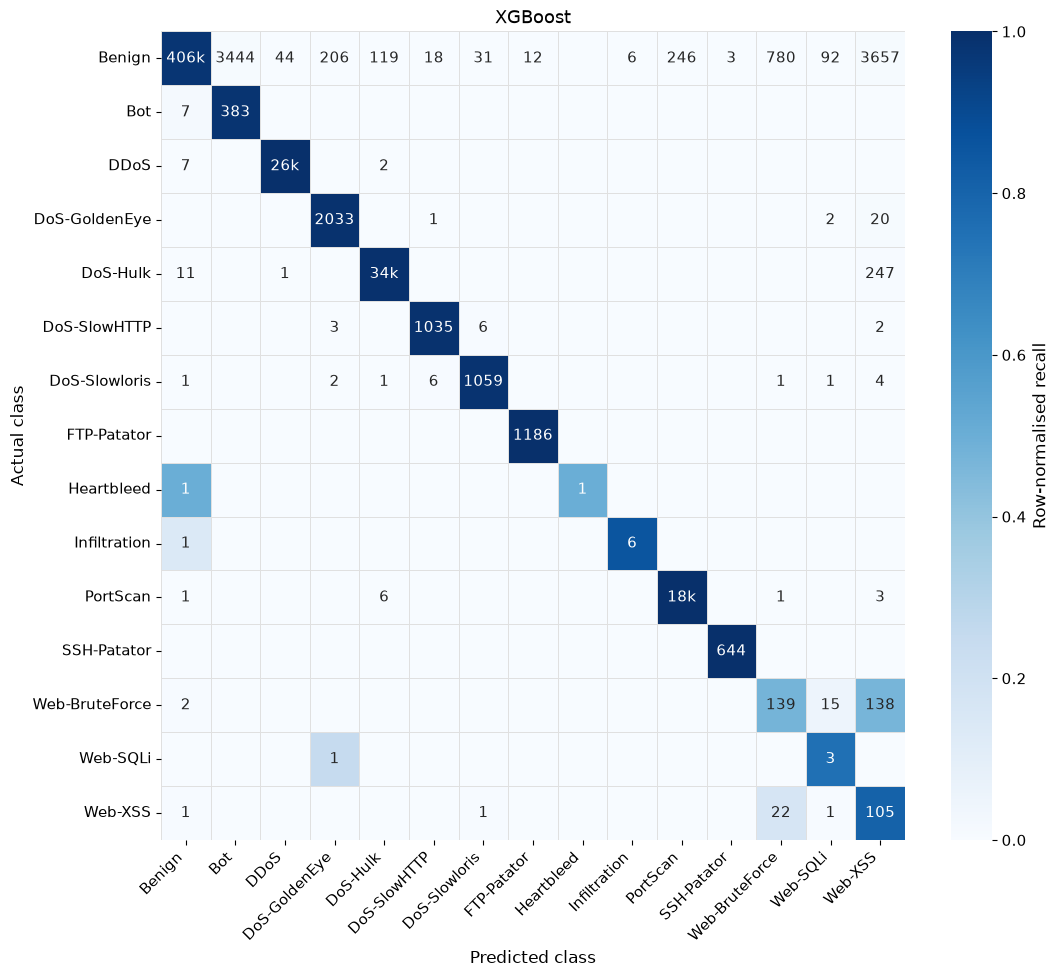

In [8]:
# ============================================================
# CELL 7 — Phase 3: Train XGBoost (+ paper-size plotting helpers)
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Paper-size figures: large fonts, high dpi
FS = CFG['evaluation']['font_size']
plt.rcParams.update({'font.size': FS, 'axes.titlesize': FS + 1, 'axes.labelsize': FS,
                     'xtick.labelsize': FS - 1, 'ytick.labelsize': FS - 1,
                     'legend.fontsize': FS - 1, 'figure.dpi': 100,
                     'savefig.dpi': CFG['evaluation']['dpi'], 'savefig.bbox': 'tight'})

SHORT = {'BENIGN': 'Benign', 'DoS Slowhttptest': 'DoS-SlowHTTP', 'DoS slowloris': 'DoS-Slowloris',
         'DoS GoldenEye': 'DoS-GoldenEye', 'DoS Hulk': 'DoS-Hulk', 'Web Attack - Brute Force': 'Web-BruteForce',
         'Web Attack - XSS': 'Web-XSS', 'Web Attack - Sql Injection': 'Web-SQLi'}
short = lambda n: SHORT.get(n, n)

def savefig(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(PATHS['results_figures'] / f'{name}.{ext}')
    plt.show(); plt.close(fig)

def plot_confusion(y_true, y_pred, class_names, title, name):
    """Counts in cells, colour = row-normalised recall, so rare classes stay visible."""
    labels = list(range(len(class_names)))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    rown = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    annot = np.vectorize(lambda v: '' if v == 0 else (f'{v/1000:.0f}k' if v >= 10000 else str(v)))(cm)
    fig, ax = plt.subplots(figsize=(12, 10.5))
    sns.heatmap(rown, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=1, ax=ax,
                xticklabels=[short(c) for c in class_names], yticklabels=[short(c) for c in class_names],
                cbar_kws={'label': 'Row-normalised recall'}, annot_kws={'fontsize': FS - 1},
                linewidths=0.4, linecolor='#e0e0e0')
    ax.set_xlabel('Predicted class'); ax.set_ylabel('Actual class'); ax.set_title(title)
    plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
    savefig(fig, name)
    return cm

def _build_xgb(cfg):
    x = cfg['models']['xgboost']
    base = dict(n_estimators=x['n_estimators'], max_depth=x['max_depth'], learning_rate=x['learning_rate'],
                subsample=x['subsample'], colsample_bytree=x['colsample_bytree'],
                min_child_weight=x['min_child_weight'], eval_metric='mlogloss',
                random_state=cfg['random_seed'], n_jobs=-1, tree_method='hist')
    if x['use_gpu']:
        base['device'] = 'cuda'
    return xgb.XGBClassifier(**base)

xgb_path = PATHS['models'] / CFG['split']['mode'] / 'xgboost.pkl'
xgb_path.parent.mkdir(parents=True, exist_ok=True)
if xgb_path.exists():
    print('✅ XGBoost cached — loading.'); xgb_model = joblib.load(xgb_path)
else:
    set_global_seed(CFG['random_seed'])
    t0 = time.time()
    xgb_model = _build_xgb(CFG).fit(X_train, y_train, verbose=False)
    joblib.dump(xgb_model, xgb_path); print(f'XGBoost trained in {_elapsed(t0)}')

proba_xgb  = xgb_model.predict_proba(X_test)
y_pred_xgb = proba_xgb.argmax(1)
print(classification_report(y_test, y_pred_xgb, target_names=le.classes_, digits=4, zero_division=0))
cm_xgb = plot_confusion(y_test, y_pred_xgb, le.classes_, 'XGBoost', 'confusion_xgboost')


✅ Random Forest cached — loading.


                            precision    recall  f1-score   support

                    BENIGN     0.9999    0.9804    0.9901    414451
                       Bot     0.0858    0.9897    0.1579       390
                      DDoS     0.9994    0.9996    0.9995     25603
             DoS GoldenEye     0.9060    0.9893    0.9458      2056
                  DoS Hulk     0.9962    0.9925    0.9944     34569
          DoS Slowhttptest     0.9913    0.9857    0.9885      1046
             DoS slowloris     0.9788    0.9888    0.9838      1075
               FTP-Patator     0.9875    1.0000    0.9937      1186
                Heartbleed     1.0000    0.5000    0.6667         2
              Infiltration     0.6667    0.8571    0.7500         7
                  PortScan     0.9865    0.9994    0.9929     18139
               SSH-Patator     0.9969    0.9984    0.9977       644
  Web Attack - Brute Force     0.2771    0.4694    0.3485       294
Web Attack - Sql Injection     0.0177    0.5000

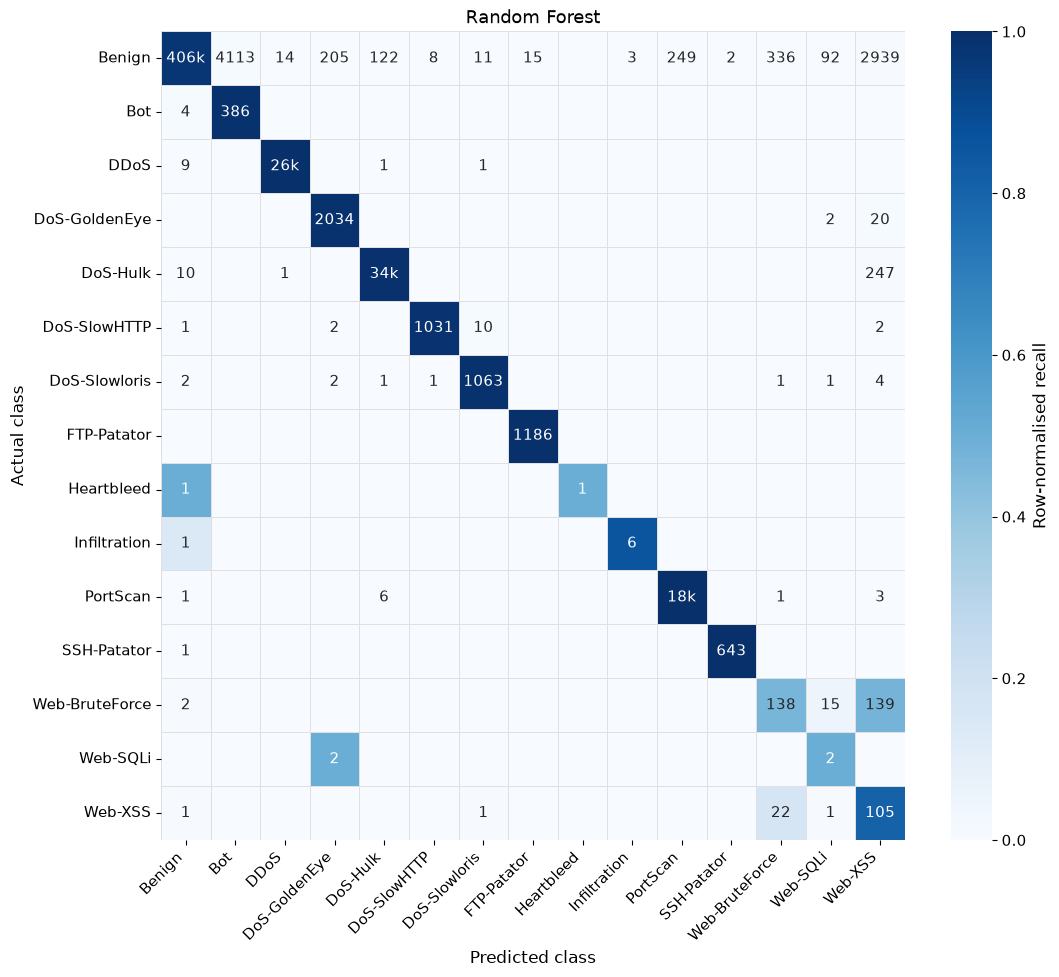

✅ DNN cached — loading.


/var/tmp/pbs.12881.jiit-master/ipykernel_1210235/181630175.py:76: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at ../torch/csrc/utils/tensor_numpy.cpp:206.)
  y_pred_dnn = np.concatenate([dnn_model(torch.from_numpy(Xt[i:i + 65536]).to(device)).argmax(1).cpu().numpy()


                            precision    recall  f1-score   support

                    BENIGN     0.9999    0.8983    0.9464    414451
                       Bot     0.0348    1.0000    0.0672       390
                      DDoS     0.8615    0.9989    0.9251     25603
             DoS GoldenEye     0.8291    0.9888    0.9020      2056
                  DoS Hulk     0.8903    0.9958    0.9401     34569
          DoS Slowhttptest     0.8037    0.9866    0.8858      1046
             DoS slowloris     0.8299    0.9619    0.8910      1075
               FTP-Patator     0.6975    0.9992    0.8215      1186
                Heartbleed     0.5000    0.5000    0.5000         2
              Infiltration     0.0136    0.8571    0.0268         7
                  PortScan     0.5103    0.9949    0.6746     18139
               SSH-Patator     0.6715    1.0000    0.8035       644
  Web Attack - Brute Force     0.0860    0.4830    0.1460       294
Web Attack - Sql Injection     0.0028    0.7500

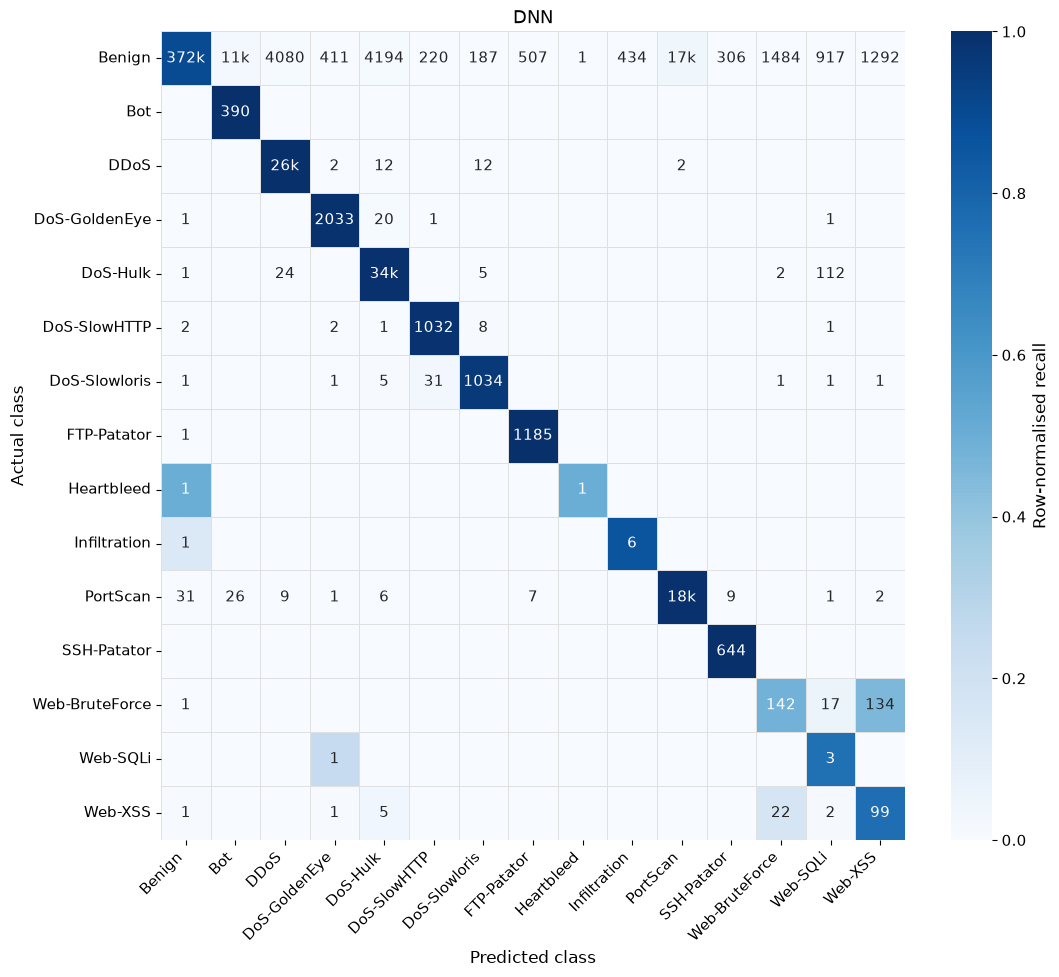

In [9]:
# ============================================================
# CELL 8 — Train Random Forest + DNN (DNN now seeded)
# ============================================================
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# ---- Random Forest ----
rf_path = PATHS['models'] / CFG['split']['mode'] / 'random_forest.pkl'
if rf_path.exists():
    print('✅ Random Forest cached — loading.'); rf_model = joblib.load(rf_path)
else:
    r = CFG['models']['random_forest']
    t0 = time.time()
    rf_model = RandomForestClassifier(n_estimators=r['n_estimators'], max_depth=r['max_depth'],
                                      class_weight=r['class_weight'], n_jobs=r['n_jobs'],
                                      random_state=CFG['random_seed']).fit(X_train, y_train)
    joblib.dump(rf_model, rf_path); print(f'RF trained in {_elapsed(t0)}')
y_pred_rf = rf_model.predict(X_test)
print(classification_report(y_test, y_pred_rf, target_names=le.classes_, digits=4, zero_division=0))
cm_rf = plot_confusion(y_test, y_pred_rf, le.classes_, 'Random Forest', 'confusion_random_forest')

# ---- DNN ----
class IDSNet(nn.Module):
    def __init__(self, in_dim, hidden, dropouts, n_classes):
        super().__init__()
        layers, prev = [], in_dim
        for h, d in zip(hidden, dropouts):
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU()]
            if d > 0: layers.append(nn.Dropout(d))
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

dnn_cfg = CFG['models']['dnn']
device  = torch.device('cuda' if GPU_AVAILABLE and dnn_cfg['use_gpu'] else 'cpu')
n_classes, n_features = len(le.classes_), X_train.shape[1]
dnn_path = PATHS['models'] / CFG['split']['mode'] / 'dnn.pt'

if dnn_path.exists():
    print('✅ DNN cached — loading.')
    ck = torch.load(dnn_path, map_location=device, weights_only=True)
    dnn_model = IDSNet(ck['in_dim'], ck['hidden'], ck['dropouts'], ck['n_classes']).to(device)
    dnn_model.load_state_dict(ck['state_dict'])
else:
    set_global_seed(CFG['random_seed'])                  # seeds weight init + dropout
    torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
    dnn_model = IDSNet(n_features, dnn_cfg['hidden_layers'], dnn_cfg['dropout'], n_classes).to(device)
    counts  = np.bincount(y_train, minlength=n_classes)
    w = 1.0 / np.maximum(counts, 1); w = w / w.sum() * n_classes
    crit = nn.CrossEntropyLoss(weight=torch.FloatTensor(w).to(device))
    opt  = torch.optim.Adam(dnn_model.parameters(), lr=dnn_cfg['learning_rate'],
                            weight_decay=dnn_cfg['weight_decay'])
    gen  = torch.Generator().manual_seed(CFG['random_seed'])   # seeds the shuffling order
    ds   = TensorDataset(torch.from_numpy(np.asarray(X_train, dtype=np.float32)),
                         torch.from_numpy(np.asarray(y_train, dtype=np.int64)))
    loader = DataLoader(ds, batch_size=dnn_cfg['batch_size'], shuffle=True, generator=gen,
                        num_workers=0, pin_memory=dnn_cfg['pin_memory'])
    t0 = time.time()
    for ep in range(dnn_cfg['epochs']):
        dnn_model.train(); tot = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            opt.zero_grad(); loss = crit(dnn_model(xb), yb); loss.backward(); opt.step()
            tot += loss.item()
        if (ep + 1) % max(1, dnn_cfg['epochs'] // 10) == 0:
            log.info(f'DNN epoch {ep + 1}/{dnn_cfg["epochs"]} loss={tot / len(loader):.4f}')
    torch.save({'state_dict': dnn_model.state_dict(), 'in_dim': n_features,
                'hidden': dnn_cfg['hidden_layers'], 'dropouts': dnn_cfg['dropout'],
                'n_classes': n_classes}, dnn_path)
    print(f'DNN trained in {_elapsed(t0)}')

dnn_model.eval()
with torch.no_grad():
    Xt = np.asarray(X_test, dtype=np.float32)
    y_pred_dnn = np.concatenate([dnn_model(torch.from_numpy(Xt[i:i + 65536]).to(device)).argmax(1).cpu().numpy()
                                 for i in range(0, len(Xt), 65536)])
print(classification_report(y_test, y_pred_dnn, target_names=le.classes_, digits=4, zero_division=0))
cm_dnn = plot_confusion(y_test, y_pred_dnn, le.classes_, 'DNN', 'confusion_dnn')


               accuracy  weighted_precision  weighted_recall  weighted_f1  macro_precision  macro_recall  macro_f1  macro_f1_95ci_lo  macro_f1_95ci_hi  benign_flagged_as_attack
model                                                                                                                                                                           
XGBoost           98.16               99.71            98.16        98.88            70.75         88.69     71.17             65.56             74.35                      8658
Random Forest     98.27               99.73            98.27        98.95            72.80         87.05     72.68             67.30             75.85                      8109
DNN               91.46               96.33            91.46        93.27            51.97         87.84     57.70             54.24             61.18                     42147

Per-class XGBoost (precision / recall with 95% Wilson CIs):
                     class  support  predicted  precis

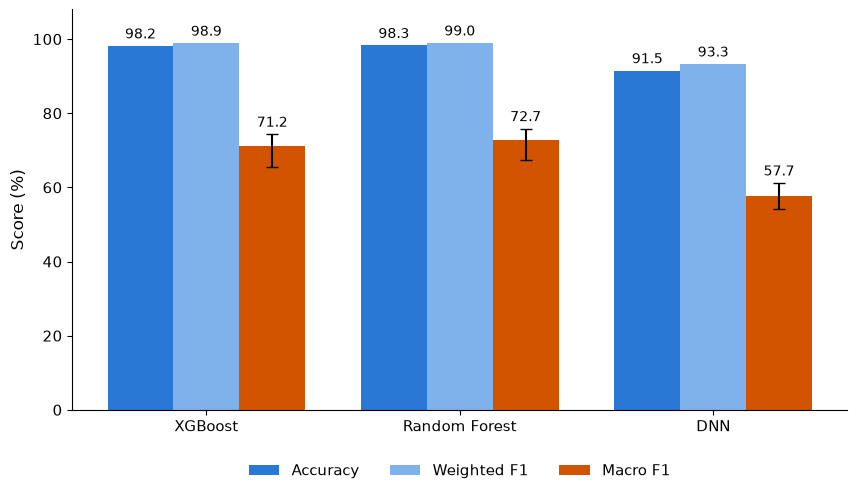

In [10]:
# ============================================================
# CELL 9 — Classifier evaluation: per-class precision / recall / F1 /
#          support with 95% CIs, bootstrap CIs for the summary metrics
# ============================================================
from scipy.stats import norm
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             precision_recall_fscore_support)

def wilson_ci(k, n, conf=0.95):
    """Wilson score interval for a proportion k/n (in %). Returns (lo, hi)."""
    if n == 0:
        return (np.nan, np.nan)
    z = norm.ppf(1 - (1 - conf) / 2); p = k / n
    den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return (100 * max(0, c - h), 100 * min(1, c + h))

def per_class_table(y_true, y_pred, names):
    labels = list(range(len(names)))
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    rows = []
    for i, n in enumerate(names):
        tp, pred_pos = cm[i, i], cm[:, i].sum()
        rlo, rhi = wilson_ci(tp, s[i]); plo, phi = wilson_ci(tp, pred_pos)
        rows.append({'class': n, 'support': int(s[i]), 'predicted': int(pred_pos),
                     'precision': round(100 * p[i], 2), 'precision_95ci': f'[{plo:.1f}, {phi:.1f}]',
                     'recall': round(100 * r[i], 2), 'recall_95ci': f'[{rlo:.1f}, {rhi:.1f}]',
                     'f1': round(100 * f[i], 2),
                     'note': 'support < 30: unstable estimate' if s[i] < 30 else ''})
    return pd.DataFrame(rows)

def bootstrap_ci(y_true, y_pred, fn, n_boot=200, seed=42):
    rng = np.random.default_rng(seed); n = len(y_true); vals = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n); vals.append(fn(y_true[i], y_pred[i]))
    return np.percentile(vals, [2.5, 97.5]) * 100

summary = []
for name, yp in [('XGBoost', y_pred_xgb), ('Random Forest', y_pred_rf), ('DNN', y_pred_dnn)]:
    per_class_table(y_test, yp, le.classes_).to_csv(
        PATHS['results_tables'] / f'per_class_{name.lower().replace(" ", "_")}.csv', index=False)
    mf = lambda a, b: f1_score(a, b, average='macro', zero_division=0)
    wf = lambda a, b: f1_score(a, b, average='weighted', zero_division=0)
    mlo, mhi = bootstrap_ci(y_test, yp, mf)
    summary.append({'model': name,
                    'accuracy': 100 * accuracy_score(y_test, yp),
                    'weighted_precision': 100 * precision_score(y_test, yp, average='weighted', zero_division=0),
                    'weighted_recall': 100 * recall_score(y_test, yp, average='weighted', zero_division=0),
                    'weighted_f1': 100 * wf(y_test, yp),
                    'macro_precision': 100 * precision_score(y_test, yp, average='macro', zero_division=0),
                    'macro_recall': 100 * recall_score(y_test, yp, average='macro', zero_division=0),
                    'macro_f1': 100 * mf(y_test, yp), 'macro_f1_95ci_lo': mlo, 'macro_f1_95ci_hi': mhi,
                    'benign_flagged_as_attack': int(((y_test == le.transform(['BENIGN'])[0]) &
                                                     (yp != le.transform(['BENIGN'])[0])).sum())})
model_cmp = pd.DataFrame(summary).set_index('model').round(2)
model_cmp.to_csv(PATHS['results_tables'] / f'model_comparison_{CFG["split"]["mode"]}.csv')
print(model_cmp.to_string())
print('\nPer-class XGBoost (precision / recall with 95% Wilson CIs):')
print(pd.read_csv(PATHS['results_tables'] / 'per_class_xgboost.csv').fillna('').to_string(index=False))

# Chart: full 0-100 axis, values printed, macro-F1 bootstrap CI as error bar
fig, ax = plt.subplots(figsize=(10, 5.2))
mets = ['accuracy', 'weighted_f1', 'macro_f1']; labs = ['Accuracy', 'Weighted F1', 'Macro F1']
cols = ['#2a78d6', '#7fb2ea', '#d35400']; w = 0.26; xs = np.arange(len(model_cmp))
for j, (m, lab, c) in enumerate(zip(mets, labs, cols)):
    v = model_cmp[m].values
    err = None
    if m == 'macro_f1':
        err = np.vstack([v - model_cmp['macro_f1_95ci_lo'].values, model_cmp['macro_f1_95ci_hi'].values - v])
    b = ax.bar(xs + (j - 1) * w, v, w, label=lab, color=c, yerr=err, capsize=4)
    ax.bar_label(b, fmt='%.1f', padding=3, fontsize=FS - 2)
ax.set_xticks(xs, model_cmp.index); ax.set_ylim(0, 108); ax.set_ylabel('Score (%)')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
savefig(fig, 'model_comparison')


SHAP values: (5000, 32, 15) (samples, features, classes)


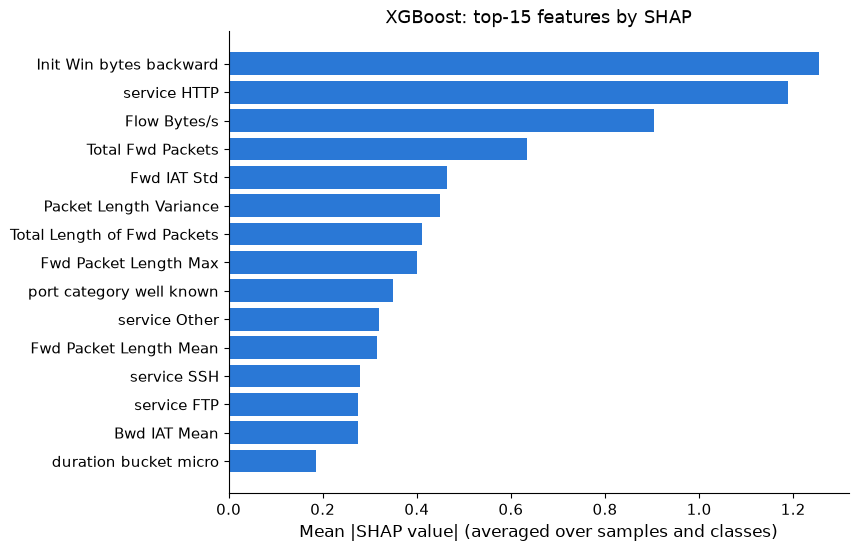

/var/tmp/pbs.12881.jiit-master/ipykernel_1210235/103584391.py:42: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv3[:, :, c], X_shap, max_display=12, show=False, plot_size=(9, 6))


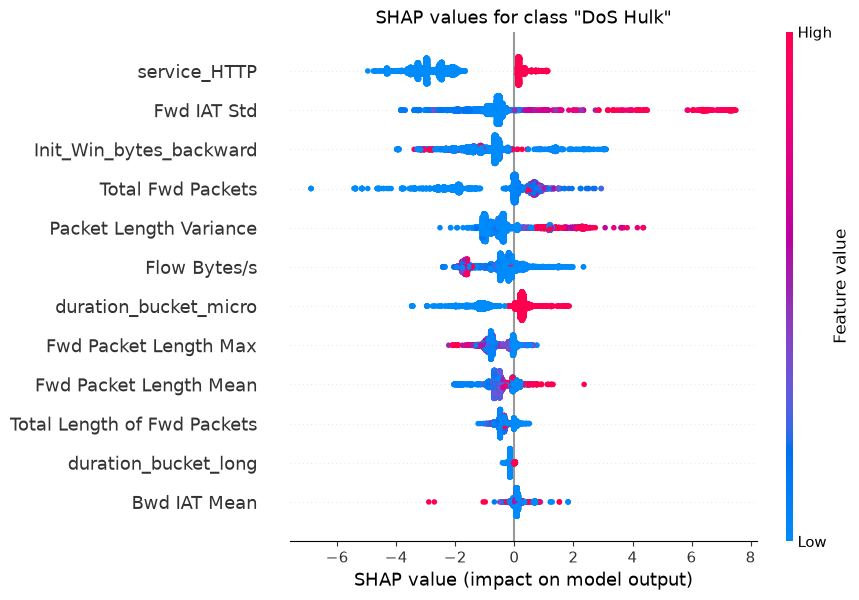

✅ SHAP done — explainer ready for alert generation


In [11]:
# ============================================================
# CELL 10 — SHAP explainability (XGBoost). The explainer built here is
#           REQUIRED by the alert generator: alerts carry real SHAP evidence.
# ============================================================
import shap

def shap_3d(sv, n_classes):
    """Normalise any SHAP return shape to (n_samples, n_features, n_classes)."""
    if isinstance(sv, list):
        return np.stack(sv, axis=-1)
    sv = np.asarray(sv)
    if sv.ndim == 2:
        return sv[:, :, None]
    if sv.ndim == 3 and sv.shape[1] == n_classes and sv.shape[2] != n_classes:
        return np.transpose(sv, (0, 2, 1))
    return sv

explainer = shap.TreeExplainer(xgb_model)
n_s = min(CFG['shap']['sample_size'], len(X_test))
X_shap = X_test.sample(n=n_s, random_state=CFG['random_seed'])
sv3 = shap_3d(explainer.shap_values(X_shap, check_additivity=False), len(le.classes_))
print(f'SHAP values: {sv3.shape} (samples, features, classes)')

# Global importance: mean |SHAP| over samples and classes
imp = pd.Series(np.abs(sv3).mean(axis=(0, 2)), index=X_shap.columns).sort_values(ascending=False)
imp.to_csv(PATHS['results_tables'] / 'shap_global_importance.csv', header=['mean_abs_shap'])
top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([t.replace('_', ' ') for t in top.index], top.values, color='#2a78d6')
ax.set_xlabel('Mean |SHAP value| (averaged over samples and classes)')
ax.set_title('XGBoost: top-15 features by SHAP')
for s in ('top', 'right'): ax.spines[s].set_visible(False)
savefig(fig, 'shap_importance')

# Beeswarm for one attack class (the most frequent attack class in the sample)
benign_id = int(le.transform(['BENIGN'])[0])
y_s = y_test[X_test.index.get_indexer(X_shap.index)]
att = pd.Series(y_s[y_s != benign_id]).value_counts()
if len(att):
    c = int(att.index[0])
    plt.figure()
    shap.summary_plot(sv3[:, :, c], X_shap, max_display=12, show=False, plot_size=(9, 6))
    plt.title(f'SHAP values for class "{le.classes_[c]}"')
    savefig(plt.gcf(), 'shap_beeswarm')
print('✅ SHAP done — explainer ready for alert generation')


In [12]:
# ============================================================
# CELL 11 — Generalisation beyond near-duplicate flows
#   (a) TEMPORAL split: within each (day-file, class) the latest 20% of flows
#       are the test set, with a 2% purge gap. Same pipeline, fitted on train.
#   (b) LEAVE-ONE-DAY-OUT: binary benign-vs-attack detector trained on the
#       other capture days and tested on a held-out day, whose attack types
#       are therefore unseen during training.
# ============================================================
from sklearn.metrics import roc_auc_score

RUN_TEMPORAL = True
RUN_LODO     = True
LODO_BENIGN_CAP = 1_000_000      # benign rows kept per training fold (attacks all kept)
GEN_DIR = PATHS['data_splits'] / 'generalisation'; GEN_DIR.mkdir(parents=True, exist_ok=True)

# ---- (a) temporal split ----
if RUN_TEMPORAL and CFG['split']['mode'] != 'temporal':
    out_t = PATHS['results_tables'] / 'model_comparison_temporal_xgb.csv'
    if out_t.exists():
        print(pd.read_csv(out_t).to_string(index=False))
    else:
        DT = build_dataset(df_cleaned, CFG, 'temporal', 'temporal')
        m_t = _build_xgb(CFG).fit(DT['X_train'], DT['y_train'], verbose=False)
        yp_t = m_t.predict(DT['X_test'])
        rows = []
        for split_name, yt, yp in [('random (main)', y_test, y_pred_xgb), ('temporal', DT['y_test'], yp_t)]:
            rows.append({'split': split_name, 'test_rows': len(yt),
                         'accuracy': 100 * accuracy_score(yt, yp),
                         'weighted_f1': 100 * f1_score(yt, yp, average='weighted', zero_division=0),
                         'macro_f1': 100 * f1_score(yt, yp, average='macro', zero_division=0)})
        pd.DataFrame(rows).round(2).to_csv(out_t, index=False)
        per_class_table(DT['y_test'], yp_t, DT['le'].classes_).to_csv(
            PATHS['results_tables'] / 'per_class_xgboost_temporal.csv', index=False)
        plot_confusion(DT['y_test'], yp_t, DT['le'].classes_, 'XGBoost, temporal split', 'confusion_xgboost_temporal')
        print(pd.DataFrame(rows).round(2).to_string(index=False))
        del DT

# ---- (b) leave-one-day-out, binary detection ----
if RUN_LODO:
    out_l = PATHS['results_tables'] / 'leave_one_day_out_binary.csv'
    if out_l.exists():
        print(pd.read_csv(out_l).to_string(index=False))
    else:
        is_att = (df_cleaned['Label'] != 'BENIGN').to_numpy()
        attack_days = [d for d in df_cleaned['__day__'].unique()
                       if is_att[(df_cleaned['__day__'] == d).to_numpy()].any()]
        feat_cols = [c for c in df_cleaned.columns if c not in META_COLS + ['Label']]
        rows, per_cls = [], []
        for d in attack_days:
            t0 = time.time()
            tr_m = (df_cleaned['__day__'] != d).to_numpy(); te_m = ~tr_m
            tr = df_cleaned[tr_m]
            ben = tr.index[tr['Label'] == 'BENIGN']
            if len(ben) > LODO_BENIGN_CAP:
                keep = np.random.default_rng(CFG['random_seed']).choice(ben, LODO_BENIGN_CAP, replace=False)
                tr = tr.loc[np.sort(np.concatenate([keep, tr.index[tr['Label'] != 'BENIGN']]))]
            le_f = LabelEncoder().fit(tr['Label'])
            cfg_f = json.loads(json.dumps(CFG)); cfg_f['features']['mi_sample'] = 100_000
            cfg_f['features']['port_service_map'] = CFG['features']['port_service_map']
            fp_f = FeaturePipeline(cfg_f).fit(tr[feat_cols], le_f.transform(tr['Label']), verbose=False)
            ytr = (tr['Label'] != 'BENIGN').astype(int).to_numpy()
            te = df_cleaned[te_m]; yte = (te['Label'] != 'BENIGN').astype(int).to_numpy()
            kw = dict(n_estimators=300, max_depth=8, learning_rate=0.05, subsample=0.8,
                      colsample_bytree=0.8, eval_metric='logloss', tree_method='hist',
                      random_state=CFG['random_seed'], n_jobs=-1,
                      scale_pos_weight=float((ytr == 0).sum() / max(1, ytr.sum())))
            if GPU_AVAILABLE: kw['device'] = 'cuda'
            mb = xgb.XGBClassifier(**kw).fit(fp_f.transform(tr[feat_cols]), ytr, verbose=False)
            p = mb.predict_proba(fp_f.transform(te[feat_cols]))[:, 1]; yp = (p >= 0.5).astype(int)
            tp = int(((yp == 1) & (yte == 1)).sum()); fn = int(((yp == 0) & (yte == 1)).sum())
            fpos = int(((yp == 1) & (yte == 0)).sum()); tn = int(((yp == 0) & (yte == 0)).sum())
            rows.append({'held_out_day': d,
                         'unseen_attack_classes': ', '.join(sorted(set(te['Label']) - {'BENIGN'})),
                         'test_attacks': tp + fn, 'test_benign': fpos + tn,
                         'attack_recall': round(100 * tp / max(1, tp + fn), 2),
                         'benign_fpr': round(100 * fpos / max(1, fpos + tn), 2),
                         'precision': round(100 * tp / max(1, tp + fpos), 2),
                         'auc': round(roc_auc_score(yte, p), 4) if len(set(yte)) > 1 else np.nan})
            for c in sorted(set(te['Label']) - {'BENIGN'}):
                mc = (te['Label'] == c).to_numpy()
                per_cls.append({'held_out_day': d, 'class': c, 'n': int(mc.sum()),
                                'recall': round(100 * yp[mc].mean(), 2)})
            print(f'  held out {d}: recall {rows[-1]["attack_recall"]}%, FPR {rows[-1]["benign_fpr"]}% '
                  f'({_elapsed(t0)})')
        pd.DataFrame(rows).to_csv(out_l, index=False)
        pd.DataFrame(per_cls).to_csv(PATHS['results_tables'] / 'leave_one_day_out_per_class.csv', index=False)
        print(pd.DataFrame(rows).to_string(index=False))
        print(pd.DataFrame(per_cls).to_string(index=False))


        split  test_rows  accuracy  weighted_f1  macro_f1
random (main)     499596     98.16        98.88     71.17
     temporal     499596     97.87        98.50     73.87
held_out_day                                                                unseen_attack_classes  test_attacks  test_benign  attack_recall  benign_fpr  precision    auc
      Friday                                                                  Bot, DDoS, PortScan        220656       394764           0.38        0.25      45.95 0.7335
    Thursday Infiltration, Web Attack - Brute Force, Web Attack - Sql Injection, Web Attack - XSS          2179       394718           4.18        0.35       6.18 0.9273
     Tuesday                                                             FTP-Patator, SSH-Patator          9150       397317           0.01        0.89       0.03 0.8909
   Wednesday                 DoS GoldenEye, DoS Hulk, DoS Slowhttptest, DoS slowloris, Heartbleed        193741       392850           2.95       

In [13]:
# ============================================================
# CELL 12 — Phase 4: MITRE ATT&CK knowledge base (pinned version),
#           retrieval, and the reference (gold) technique mapping
# ============================================================
import requests, faiss
from sentence_transformers import SentenceTransformer

ver = CFG['rag']['attck_version']
kb = PATHS['knowledge_base'] / f'attck_v{ver}'; kb.mkdir(parents=True, exist_ok=True)
stix_path, index_path, tech_path = kb / 'enterprise-attack.json', kb / 'faiss_index.bin', kb / 'techniques.json'
KB_DIR = kb                                     # read by the GPU worker processes

if not stix_path.exists():
    url = CFG['rag']['attck_url'].format(ver=ver)
    log.info(f'Downloading ATT&CK v{ver} from {url}')
    r = requests.get(url, timeout=300); r.raise_for_status(); stix_path.write_bytes(r.content)

def parse_techniques(stix):
    out = []
    for o in stix.get('objects', []):
        if o.get('type') != 'attack-pattern' or o.get('revoked') or o.get('x_mitre_deprecated'):
            continue
        tid = next((x.get('external_id') for x in o.get('external_references', [])
                    if x.get('source_name') == 'mitre-attack'), None)
        if tid:
            out.append({'id': tid, 'name': o.get('name', ''), 'description': o.get('description', ''),
                        'tactics': [p.get('phase_name', '') for p in o.get('kill_chain_phases', [])]})
    return out

techniques = parse_techniques(json.loads(stix_path.read_text()))
TECH_BY_ID = {t['id']: t for t in techniques}
log.info(f'ATT&CK v{ver}: {len(techniques)} active techniques/sub-techniques')

embedder = SentenceTransformer(CFG['rag']['embedding_model'])
if index_path.exists() and tech_path.exists():
    faiss_index = faiss.read_index(str(index_path))
    techniques = json.loads(tech_path.read_text()); TECH_BY_ID = {t['id']: t for t in techniques}
else:
    # Document = "ID: name. Tactics: ... . description"
    docs = [f"{t['id']}: {t['name']}. Tactics: {', '.join(t['tactics'])}. {t['description']}" for t in techniques]
    emb = embedder.encode(docs, batch_size=64, convert_to_numpy=True, show_progress_bar=True).astype('float32')
    faiss.normalize_L2(emb)
    faiss_index = faiss.IndexFlatIP(emb.shape[1])   # inner product on unit vectors = cosine similarity
    faiss_index.add(emb)
    faiss.write_index(faiss_index, str(index_path)); tech_path.write_text(json.dumps(techniques))

def query_rag(query_text, top_k=None):
    top_k = top_k or CFG['rag']['top_k_retrieval']
    q = embedder.encode([query_text], convert_to_numpy=True).astype('float32'); faiss.normalize_L2(q)
    sims, idxs = faiss_index.search(q, top_k)
    return [{'id': techniques[i]['id'], 'name': techniques[i]['name'],
             'tactics': ', '.join(techniques[i]['tactics']),
             'description_snippet': techniques[i]['description'][:400], 'score': round(float(s), 4)}
            for s, i in zip(sims[0], idxs[0]) if 0 <= i < len(techniques)]

def build_rag_query(alert):
    """Retrieval query = predicted class + service + flag text (documented in the paper)."""
    svc = alert.get('service') or alert.get('context', {}).get('service', '')
    q = f"{alert.get('predicted_label', '')} attack on {svc} service"
    if alert.get('flag_anomaly') not in (None, '', 'None'):
        q += f", TCP flags: {alert['flag_anomaly']}"
    return q

# ── Reference technique mapping per CIC-IDS2017 class ──────────────────────
# DRAFT prepared from the CIC-IDS2017 attack descriptions (Sharafaldin et al.,
# ICISSP 2018). 'primary' = the single best technique; 'acceptable' = other
# techniques an analyst would accept. It MUST be reviewed by independent
# security experts: edit results/expert_eval/gold_techniques_template.csv and
# save it as results/expert_eval/gold_techniques_expert.csv — it is then used
# automatically instead of this draft.
GOLD_TECHNIQUES_DRAFT = {
    'DDoS':                       ('T1498', ['T1498', 'T1498.001', 'T1499', 'T1499.002']),
    'DoS Hulk':                   ('T1499', ['T1499', 'T1499.002', 'T1499.003', 'T1498', 'T1498.001']),
    'DoS GoldenEye':              ('T1499', ['T1499', 'T1499.002', 'T1499.003']),
    'DoS slowloris':              ('T1499', ['T1499', 'T1499.002', 'T1499.003']),
    'DoS Slowhttptest':           ('T1499', ['T1499', 'T1499.002', 'T1499.003']),
    'Heartbleed':                 ('T1190', ['T1190', 'T1212', 'T1040']),
    'Infiltration':               ('T1204', ['T1204', 'T1204.002', 'T1105', 'T1046', 'T1071', 'T1189', 'T1566']),
    'Bot':                        ('T1071', ['T1071', 'T1071.001', 'T1583.005', 'T1584.005', 'T1105', 'T1041']),
    'PortScan':                   ('T1046', ['T1046', 'T1595', 'T1595.001', 'T1595.002']),
    'FTP-Patator':                ('T1110', ['T1110', 'T1110.001']),
    'SSH-Patator':                ('T1110', ['T1110', 'T1110.001', 'T1021.004']),
    'Web Attack - Brute Force':   ('T1110', ['T1110', 'T1110.001', 'T1110.003']),
    'Web Attack - XSS':           ('T1059.007', ['T1059.007', 'T1059', 'T1189', 'T1185', 'T1190']),
    'Web Attack - Sql Injection': ('T1190', ['T1190']),
}
gold_tpl = PATHS['results_expert'] / 'gold_techniques_template.csv'
gold_exp = PATHS['results_expert'] / 'gold_techniques_expert.csv'
pd.DataFrame([{'class': c, 'primary': p, 'acceptable': ';'.join(a),
               'acceptable_names': '; '.join(TECH_BY_ID.get(t, {}).get('name', '?') for t in a),
               'reviewer_notes': ''} for c, (p, a) in GOLD_TECHNIQUES_DRAFT.items()]).to_csv(gold_tpl, index=False)
if gold_exp.exists():
    g = pd.read_csv(gold_exp)
    GOLD_TECHNIQUES = {r['class']: (r['primary'], str(r['acceptable']).split(';')) for _, r in g.iterrows()}
    GOLD_SOURCE = 'expert-reviewed'
else:
    GOLD_TECHNIQUES = GOLD_TECHNIQUES_DRAFT; GOLD_SOURCE = 'draft (not yet expert-reviewed)'
bad = [t for _, a in GOLD_TECHNIQUES.values() for t in a if t not in TECH_BY_ID]
print(f'Gold technique mapping: {GOLD_SOURCE}; IDs missing from ATT&CK v{ver}: {bad or "none"}')
update_manifest(attck={'version': ver, 'n_techniques': len(techniques), 'gold_source': GOLD_SOURCE,
                       'embedding_model': CFG['rag']['embedding_model'], 'index': 'FAISS IndexFlatIP (cosine)'})

for h in query_rag('DDoS attack on HTTP service')[:3]:
    print(f"  {h['id']} {h['name']} ({h['score']})")


02:03:18 INFO ATT&CK v17.1: 679 active techniques/sub-techniques


02:03:18 INFO Use pytorch device_name: cuda:0


02:03:18 INFO Load pretrained SentenceTransformer: sentence-transformers/all-MiniLM-L6-v2


Gold technique mapping: draft (not yet expert-reviewed); IDs missing from ATT&CK v17.1: none


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00,  1.89it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00,  1.89it/s]

  T1499.002 Service Exhaustion Flood (0.5861)
  T1498 Network Denial of Service (0.5725)
  T1499 Endpoint Denial of Service (0.5145)


In [14]:
# ============================================================
# CELL 13 — Alert generator (real SHAP evidence) + evaluation cohort
# ============================================================
BENIGN_ID = int(le.transform(['BENIGN'])[0])
p_attack_all = 1.0 - proba_xgb[:, BENIGN_ID]
pred_all = proba_xgb.argmax(1)                 # detector's predicted class for every test flow

def _py(v):
    """numpy scalar -> plain Python number (json.dumps cannot write float32)."""
    return v.item() if isinstance(v, np.generic) else v

def _onehot_value(row, prefix):
    cols = [c for c in row.index if c.startswith(prefix)]
    if not cols or row[cols].max() <= 0:
        return 'Unknown'
    return row[cols].idxmax()[len(prefix):]

def make_alerts(positions, alert_ids):
    """Alert packets for test-set rows. Evidence = the five features with the
    largest |SHAP| for the PREDICTED class, with unscaled values and signed SHAP."""
    pos = np.asarray(positions)
    Xs = X_test.iloc[pos]
    sv = shap_3d(explainer.shap_values(Xs, check_additivity=False), len(le.classes_))
    alerts = []
    for k, i in enumerate(pos):
        pred = int(proba_xgb[i].argmax())
        s = sv[k, :, pred]
        top = np.argsort(-np.abs(s))[:5]
        un = X_test_unscaled.iloc[i]; rc = X_test_rawcols.iloc[i]
        flags = []
        if {'SYN Flag Count', 'ACK Flag Count'} <= set(rc.index) and rc['SYN Flag Count'] >= 1 and rc['ACK Flag Count'] == 0:
            flags.append('SYN without ACK')
        if 'RST Flag Count' in rc.index and rc['RST Flag Count'] >= 1:
            flags.append('RST set')
        if 'PSH Flag Count' in rc.index and rc['PSH Flag Count'] >= 3:
            flags.append('PSH >= 3')
        ctx = {'service': _onehot_value(un, 'service_'), 'port_category': _onehot_value(un, 'port_category_'),
               'duration_bucket': _onehot_value(un, 'duration_bucket_')}
        for col, key, f in [('Destination Port', 'destination_port', int),
                            ('Flow Duration', 'flow_duration_s', lambda v: round(float(v) / 1e6, 3)),
                            ('Total Fwd Packets', 'fwd_packets', int),
                            ('Total Backward Packets', 'bwd_packets', int),
                            ('Flow Bytes/s', 'flow_bytes_per_s', lambda v: round(float(v), 1))]:
            if col in rc.index:
                ctx[key] = _py(f(float(rc[col])))
        alerts.append({
            'alert_id': alert_ids[k],
            'predicted_label': str(le.classes_[pred]),
            'confidence': round(float(proba_xgb[i, pred]), 4),
            'p_attack': round(float(p_attack_all[i]), 4),
            'evidence': [{'feature': Xs.columns[j], 'value': round(float(un[Xs.columns[j]]), 4),
                          'shap': f'{float(s[j]):+.4f}'} for j in top],
            'evidence_source': 'SHAP (XGBoost, predicted class)',
            'context': ctx,
            'flag_anomaly': ', '.join(flags) if flags else 'None',
        })
    return alerts

# ── Cohort: mixed benign + attack, drawn from the TEST set ─────────────────
cohort_path = PATHS['results_logs'] / 'cohort.csv'
cohort = pd.read_csv(cohort_path) if cohort_path.exists() else None
if cohort is not None:
    # The cached / imported cohort must point at the same test rows as this split
    _ok = (cohort['test_pos'].max() < len(y_test) and
           (le.classes_[y_test[cohort['test_pos'].to_numpy()]] == cohort['ground_truth'].to_numpy()).all())
    if _ok:
        print(f'✅ Cohort cached: {len(cohort)} alerts (verified against this test split)')
    else:
        print('⚠️  The cached cohort does not match this test split (different data or cleaning) — '
              'building a new cohort. Agent runs made on the old cohort cannot be compared with new ones.')
        for _f in [cohort_path, PATHS['results_logs'] / 'alerts.json', PATHS['results_logs'] / 'alerts_v3.json']:
            if _f.exists():
                _f.rename(_f.with_suffix(_f.suffix + '.mismatched'))
        cohort = None
if cohort is None:
    cc = CFG['cohort']; rng = np.random.default_rng(CFG['random_seed'])
    pred_all = proba_xgb.argmax(1)
    flagged = pred_all != BENIGN_ID; is_ben = y_test == BENIGN_ID
    strata = {
        'S1_attack_flagged':  np.where(~is_ben & flagged)[0],
        'S2_ml_false_positive': np.where(is_ben & flagged)[0],
        'S3_hard_benign':     np.where(is_ben & ~flagged & (p_attack_all >= cc['hard_benign_min_attack_prob']))[0],
        'S4_ml_miss':         np.where(~is_ben & ~flagged)[0],
    }
    pick = []
    for c in sorted(set(y_test[strata['S1_attack_flagged']])):
        pool = strata['S1_attack_flagged'][y_test[strata['S1_attack_flagged']] == c]
        pick += [(i, 'S1_attack_flagged') for i in rng.choice(pool, min(cc['attack_per_class'], len(pool)), replace=False)]
    for s, n in [('S2_ml_false_positive', cc['ml_false_positives']), ('S3_hard_benign', cc['hard_benign']),
                 ('S4_ml_miss', cc['ml_misses'])]:
        pool = strata[s]
        pick += [(i, s) for i in rng.choice(pool, min(n, len(pool)), replace=False)] if len(pool) else []
    rng.shuffle(pick)                       # mixes strata inside every LLM batch
    cohort = pd.DataFrame(pick, columns=['test_pos', 'stratum'])
    cohort['alert_id'] = [f'A{k:04d}' for k in range(len(cohort))]
    cohort['ground_truth'] = le.classes_[y_test[cohort['test_pos']]]
    cohort['ml_pred'] = le.classes_[pred_all[cohort['test_pos']]]
    cohort['ml_conf'] = proba_xgb[cohort['test_pos'], pred_all[cohort['test_pos']]].round(4)
    cohort['p_attack'] = p_attack_all[cohort['test_pos']].round(4)
    cohort['is_attack'] = (cohort['ground_truth'] != 'BENIGN').astype(int)
    # Population size of each (stratum, class) cell in the TEST set -> prevalence weights
    pop = {(s, c): int((y_test[idx] == c).sum()) for s, idx in strata.items() for c in set(y_test[idx])}
    cohort['pop_weight'] = [pop[(s, int(le.transform([g])[0]))] for s, g in zip(cohort['stratum'], cohort['ground_truth'])]
    cohort['pop_weight'] = cohort['pop_weight'] / cohort.groupby(['stratum', 'ground_truth'])['alert_id'].transform('count')
    cohort.to_csv(cohort_path, index=False)
    pd.Series({s: len(v) for s, v in strata.items()}, name='test_set_population').to_csv(
        PATHS['results_tables'] / 'cohort_strata_population.csv')

# ── v3: extend the cohort with NEW alerts (same strata definitions, disjoint
#    rows, IDs continue). Runs already made on the first alerts stay valid and
#    are resumed on the new ones only.
def _strata_pools():
    flagged = pred_all != BENIGN_ID; is_ben = y_test == BENIGN_ID
    cc = CFG['cohort']
    return {'S1_attack_flagged':  np.where(~is_ben & flagged)[0],
            'S2_ml_false_positive': np.where(is_ben & flagged)[0],
            'S3_hard_benign':     np.where(is_ben & ~flagged & (p_attack_all >= cc['hard_benign_min_attack_prob']))[0],
            'S4_ml_miss':         np.where(~is_ben & ~flagged)[0]}

def _add_cohort_columns(df):
    df['ground_truth'] = le.classes_[y_test[df['test_pos']]]
    df['ml_pred'] = le.classes_[pred_all[df['test_pos']]]
    df['ml_conf'] = proba_xgb[df['test_pos'], pred_all[df['test_pos']]].round(4)
    df['p_attack'] = p_attack_all[df['test_pos']].round(4)
    df['is_attack'] = (df['ground_truth'] != 'BENIGN').astype(int)
    return df

if CFG['v3']['enabled']:
    pools = _strata_pools()
    used = set(cohort['test_pos'].tolist())
    rng3 = np.random.default_rng(CFG['random_seed'] + 3)
    add = []
    for s, tot in CFG['v3']['cohort_extension'].items():
        pool = np.array([i for i in pools[s] if i not in used])
        have = int((cohort['stratum'] == s).sum())
        n = len(pool) if tot == 'all' else max(0, min(int(tot) - have, len(pool)))
        if n:
            add += [(int(i), s) for i in rng3.choice(pool, n, replace=False)]
    if add:
        rng3.shuffle(add)
        k0 = int(cohort['alert_id'].str[1:].astype(int).max()) + 1
        ext = pd.DataFrame(add, columns=['test_pos', 'stratum'])
        ext['alert_id'] = [f'A{k0 + k:04d}' for k in range(len(ext))]
        ext = _add_cohort_columns(ext)
        if 'batch' not in cohort.columns:
            cohort['batch'] = 'v2'
        ext['batch'] = 'v3_extension'
        cohort = pd.concat([cohort, ext], ignore_index=True)
        print(f'➕ Cohort extended by {len(ext)} alerts (v3): '
              + ', '.join(f'{s} +{n}' for s, n in ext['stratum'].value_counts().items()))
    if 'batch' not in cohort.columns:
        cohort['batch'] = 'v2'
    # Design weights: each alert stands for (#test flows in its stratum x class) / (#such alerts)
    pop = {(s, c): int((y_test[idx] == c).sum()) for s, idx in pools.items() for c in set(y_test[idx])}
    cohort['pop_weight'] = [pop[(s, int(le.transform([g])[0]))] for s, g in zip(cohort['stratum'], cohort['ground_truth'])]
    cohort['pop_weight'] = cohort['pop_weight'] / cohort.groupby(['stratum', 'ground_truth'])['alert_id'].transform('count')
    # Episode proxy for the cluster bootstrap: same capture day + class + nearby capture order
    if 'test_meta' in globals():
        tm = test_meta.iloc[cohort['test_pos'].to_numpy()].reset_index(drop=True)
        cohort['day'] = tm['__day__'].astype(str).values
        cohort['episode'] = (cohort['day'] + '|' + cohort['ground_truth'] + '|' +
                             (tm['__order__'].to_numpy() // CFG['v3']['episode_block']).astype(str))
    cohort.to_csv(cohort_path, index=False)
    pd.Series({s: len(v) for s, v in pools.items()}, name='test_set_population').to_csv(
        PATHS['results_tables'] / 'cohort_strata_population.csv')

print(cohort.groupby('stratum').agg(n=('alert_id', 'count'), attacks=('is_attack', 'sum')).to_string())
# Alert packets are saved once and reused, so a later session (or a retrained
# model) never changes the inputs of agent runs that are already finished.
ALERTS_PATH = PATHS['results_logs'] / 'alerts.json'
_saved = json.loads(ALERTS_PATH.read_text()) if ALERTS_PATH.exists() else None
_have = (_saved or {}).get('alerts', {})
_need = [k for k, a in enumerate(cohort['alert_id']) if a not in _have]
if _need:
    _new = make_alerts(cohort['test_pos'].to_numpy()[_need], cohort['alert_id'].to_numpy()[_need].tolist())
    _have.update({a['alert_id']: a for a in _new})
print(f'✅ Alert packets: {len(cohort) - len(_need)} reused, {len(_need)} new')
alerts_all = [_have[a] for a in cohort['alert_id']]
ALERTS = {a['alert_id']: a for a in alerts_all}
GT = dict(zip(cohort['alert_id'], cohort['ground_truth']))
ALERTS_PATH.write_text(json.dumps({'ids': cohort['alert_id'].tolist(), 'alerts': ALERTS, 'gt': GT}, default=str))
print('\nExample alert packet:'); print(json.dumps(alerts_all[0], indent=2, default=_py))


# ── v3 packets: separate blocks so every condition shows the SAME measurements ─
MEAS_FEATURES = list(fpipe.consensus)          # the raw (non-engineered) model features
ALERTS_V3_PATH = PATHS['results_logs'] / 'alerts_v3.json'

def make_v3_packets(df, legacy, seed=CFG['random_seed']):
    rng = np.random.default_rng(seed + 33)
    pos = df['test_pos'].to_numpy(); ids_ = df['alert_id'].tolist()
    Xs = X_test.iloc[pos]
    sv = shap_3d(explainer.shap_values(Xs, check_additivity=False), len(le.classes_))
    feats = list(X_test.columns)
    tops = []
    for k, i in enumerate(pos):
        pred = int(proba_xgb[i].argmax()); s_ = sv[k, :, pred]
        top = np.argsort(-np.abs(s_))[:5]
        tops.append([{'feature': feats[j], 'shap': f'{float(s_[j]):+.4f}'} for j in top])
    out = {}
    for k, (a, i) in enumerate(zip(ids_, pos)):
        L = legacy[a]; un = X_test_unscaled.iloc[i]
        pred = int(proba_xgb[i].argmax())
        p_att = float(p_attack_all[i])
        if pred == BENIGN_ID:
            att = [c for c in range(len(le.classes_)) if c != BENIGN_ID]
            flip_lab = str(le.classes_[att[int(np.argmax(proba_xgb[i, att]))]])
        else:
            flip_lab = 'BENIGN'
        other = int(rng.choice([j for j in range(len(ids_)) if j != k])) if len(ids_) > 1 else k
        rnd_feats = rng.choice(len(feats), 5, replace=False)
        out[a] = {
            'measurements': {f: _py(round(float(un[f]), 4)) for f in MEAS_FEATURES if f in un.index},
            'context': L['context'] | {'flag_anomaly': L['flag_anomaly']},
            'detector': {'predicted_label': L['predicted_label'], 'confidence': L['confidence'],
                         'p_attack': L['p_attack']},
            'flipped': {'predicted_label': flip_lab, 'confidence': L['confidence'],
                        'p_attack': round(1.0 - p_att, 4)},
            'shap': tops[k],
            'shap_shuffled': [{'feature': feats[j], 'shap': tops[other][m]['shap']}
                              for m, j in enumerate(rnd_feats)],
        }
    return out

if CFG['v3']['enabled']:
    _v3 = json.loads(ALERTS_V3_PATH.read_text()) if ALERTS_V3_PATH.exists() else {'alerts': {}}
    _need3 = cohort[~cohort['alert_id'].isin(list(_v3['alerts']))]
    if len(_need3):
        _v3['alerts'].update(make_v3_packets(_need3, ALERTS))
    ALERTS_V3 = {a: _v3['alerts'][a] for a in cohort['alert_id']}
    ALERTS_V3_PATH.write_text(json.dumps({'ids': cohort['alert_id'].tolist(), 'alerts': ALERTS_V3, 'gt': GT},
                                         default=str))
    print(f'✅ v3 packets: {len(cohort) - len(_need3)} reused, {len(_need3)} new  '
          f'(measurement features: {len(MEAS_FEATURES)})')
    print(json.dumps(sal.v3_view(ALERTS_V3[cohort["alert_id"].iloc[0]], 'pred_shap'), indent=1, default=_py)[:1500])


✅ Cohort cached: 508 alerts (verified against this test split)
                        n  attacks
stratum                           
S1_attack_flagged     176      176
S2_ml_false_positive  200        0
S3_hard_benign        100        0
S4_ml_miss             32       32
✅ Alert packets: 508 reused, 0 new

Example alert packet:
{
  "alert_id": "A0000",
  "predicted_label": "Bot",
  "confidence": 0.9912,
  "p_attack": 0.9912,
  "evidence": [
    {
      "feature": "port_category_well_known",
      "value": 0.0,
      "shap": "+2.8991"
    },
    {
      "feature": "Init_Win_bytes_backward",
      "value": 256.0,
      "shap": "+1.0304"
    },
    {
      "feature": "Flow Bytes/s",
      "value": 1500000.0,
      "shap": "+0.9092"
    },
    {
      "feature": "port_category_ephemeral",
      "value": 1.0,
      "shap": "+0.8095"
    },
    {
      "feature": "service_HTTP-Alt",
      "value": 0.0,
      "shap": "-0.3568"
    }
  ],
  "evidence_source": "SHAP (XGBoost, predicted class)"

In [15]:
# ============================================================
# CELL 14 — Agent prompts and output schemas (defined in the agent library)
# ============================================================
# The exact prompts are exported to results/logs/prompts.json (paper appendix).
# Every agent output is parsed, schema-validated and normalised; an invalid
# output is re-requested up to CFG['agents']['max_retries'] times with a repair
# instruction, and if still invalid a conservative fallback (escalate to a human)
# is used. Validity, retries and fallbacks are logged and reported in Cell 16.
importlib.reload(sal)
PROMPTS, VARIANTS = sal.PROMPTS, sal.VARIANTS
(PATHS['results_logs'] / 'prompts.json').write_text(
    json.dumps({'system_prompts': PROMPTS, 'repair_prompt': sal.REPAIR}, indent=2))
for k, v in PROMPTS.items():
    print(f'── {k} ({len(v)} chars) ──\n{v[:300]}...\n')
print(f'✅ Prompts saved; variants: {list(VARIANTS)}')


# ── v3: condition-specific triage prompts + exact serialized messages ───────
if CFG['v3']['enabled']:
    v3p = {f'{cond}|{ps}': sal.triage_prompt_v3(cond, ps) for cond in CFG['v3']['conditions'] for ps in ('P1', 'P2')}
    (PATHS['results_logs'] / 'prompts_v3.json').write_text(json.dumps(v3p, indent=2))
    # Exact messages for one detector false positive and one detector miss (paper appendix).
    # They show that no alert identifier, stratum or ground-truth label reaches the model.
    ex_ids = [cohort.loc[cohort['stratum'] == s_, 'alert_id'].iloc[0]
              for s_ in ['S2_ml_false_positive', 'S4_ml_miss'] if (cohort['stratum'] == s_).any()]
    md = ['# Serialized Triage prompts (v3)',
          'Generated by the notebook from the packets used in the runs. Stratum and ground truth are',
          'evaluation metadata only and never appear in a prompt.', '']
    for a in ex_ids:
        md.append(f'## Example alert ({cohort.set_index("alert_id").loc[a, "stratum"]}; not shown to the model)')
        for cond in CFG['v3']['conditions']:
            for m in sal.serialize_messages(cond, 'P1', ALERTS_V3[a]):
                md += [f'### {cond} — {m["role"]}', '```', m['content'], '```']
    (PATHS['results_logs'] / 'serialized_prompts_v3.md').write_text('\n'.join(md))
    leak = [w for w in ['S1_', 'S2_', 'S3_', 'S4_', 'stratum', 'ground_truth', 'is_attack', 'alert_id']
            if any(w in json.dumps(sal.v3_view(ALERTS_V3[a], cond)) for a in ALERTS_V3 for cond in CFG['v3']['conditions'])]
    print(f'✅ v3 prompts saved ({len(v3p)}); serialized examples -> serialized_prompts_v3.md; '
          f'leakage check: {"OK, none" if not leak else leak}')


── triage (862 chars) ──
You are a Tier-1 SOC Triage Analyst. Given a structured alert packet produced by a
machine-learning network intrusion detector, assign a severity tier and decide escalation.

Consider: the detector's confidence and attack probability; whether the evidence features
(with their SHAP attributions) are ...

── investigation (739 chars) ──
You are a SOC Investigation Analyst. Given an alert, the triage result and MITRE ATT&CK
context, identify the ATT&CK techniques the activity corresponds to.

Rules: list at most 3 techniques, most relevant first; prefer techniques that appear in the
provided ATT&CK context; use exact ATT&CK IDs (e.g...

── response (716 chars) ──
You are a SOC Response Analyst. Based on the alert, triage and investigation, recommend
containment and mitigation. All actions are ADVISORY: a human analyst must approve them.
Recommend blocking the source only when the evidence supports a real attack.
"escalate": true means forward the alert to a ...

─

✅ v3 prompts saved (12); serialized examples -> serialized_prompts_v3.md; leakage check: OK, none


In [16]:
# ============================================================
# CELL 15 — Phase 5: run the agent experiments (one worker process per GPU)
#   The worker loads the LLM; runs go to results/agent_runs/<model>/
#   Runs: full system x 3 seeds, LLM ablations (no_rag, no_shap,
#   no_investigation), and a latency probe (batch size 1).
#   'triage_only' and 'no_coordinator' are scored from the full-system runs.
#   Every run is resumable: re-running this cell skips finished alerts.
# ============================================================
import subprocess, gc

ids = cohort['alert_id'].tolist()
W = PATHS['workers']
RUN_DIR = PATHS['results_runs'] / MODEL_SLUG; RUN_DIR.mkdir(parents=True, exist_ok=True)
seeds = CFG['experiments']['run_seeds']
RUNS_PLAN = []
if CFG['v3']['run_v2_runs'] or not CFG['v3']['enabled']:
    RUNS_PLAN += ([{'name': f'full_s{sd}', 'variant': 'full', 'seed': sd, 'n': None,
                   'out': str(RUN_DIR / f'full_seed{sd}.json')} for sd in seeds] +
                 [{'name': ab, 'variant': ab, 'seed': 42, 'n': None,
                   'out': str(RUN_DIR / f'{ab}_seed42.json')} for ab in CFG['experiments']['llm_ablations']] +
                 [{'name': 'latency_probe', 'variant': 'full', 'seed': 42, 'n': CFG['experiments']['latency_probe_n'],
                   'out': str(RUN_DIR / 'latency_probe_batch1.json'), 'batch_size': 1}])

# ── v3 runs: controlled conditions on the SAME measurements (Triage decides the
#    escalation, so the control grid runs the Triage agent only; the two main
#    conditions also run the full four-agent pipeline).
V3_RUNS = {}
if CFG['v3']['enabled']:
    V3_DIR = RUN_DIR / 'v3'; V3_DIR.mkdir(exist_ok=True)
    def _v3run(cond, ps, sd, stages):
        name = f'v3_{cond}_{ps}_{stages}_s{sd}'
        return {'name': name, 'kind': 'condition', 'condition': cond, 'prompt_set': ps, 'stages': stages,
                'seed': sd, 'n': None, 'alerts': str(ALERTS_V3_PATH), 'out': str(V3_DIR / f'{name}.json')}
    for cond in CFG['v3']['conditions']:
        for sd in CFG['v3']['control_seeds']:
            RUNS_PLAN.append(_v3run(cond, 'P1', sd, 'triage'))
    for cond in CFG['v3']['p2_conditions']:
        for sd in CFG['v3']['control_seeds']:
            RUNS_PLAN.append(_v3run(cond, 'P2', sd, 'triage'))
    for cond in CFG['v3']['full_pipeline_conditions']:
        RUNS_PLAN.append(_v3run(cond, 'P1', 42, 'full'))
    V3_RUNS = {r['name']: r for r in RUNS_PLAN if r.get('kind') == 'condition'}
RUN_FILES = {r['name']: Path(r['out']) for r in RUNS_PLAN if r.get('kind') != 'condition'}
if not RUN_FILES:   # v3-only model: still evaluate any earlier v2 runs that exist
    for p in RUN_DIR.glob('*_seed*.json'):
        base, sd = p.stem.rsplit('_seed', 1)
        RUN_FILES['full_s' + sd if base == 'full' else base] = p
V3_FILES = {k: Path(r['out']) for k, r in V3_RUNS.items()}

def _n_done(path, n_target):
    try:
        return min(len(json.loads(Path(path).read_text())), n_target)
    except Exception:
        return 0

def _n_target(r):
    return r.get('n_total', len(ids)) if r['n'] is None else r['n']

def _cost(r):   # relative LLM work: stages x alerts still to do
    n = _n_target(r)
    n_left = n - _n_done(r['out'], n)
    if r.get('kind') == 'condition':
        return n_left * (1 if r['stages'] == 'triage' else 4)
    return n_left * (3 if r['variant'] == 'no_investigation' else 4)

def _alive(pid):
    try:
        os.kill(pid, 0)
    except OSError:
        return False
    try:   # a finished child that was never reaped is a zombie, not alive
        return open(f'/proc/{pid}/stat').read().split()[2] != 'Z'
    except Exception:
        return True

def launch_and_wait(PLAN):
    """Start one worker per GPU for the unfinished runs in PLAN and wait for them."""
    todo = [r for r in PLAN if _cost(r) > 0]
    n_workers = CFG['agents']['n_gpu_workers'] if CFG['agents']['backend'] == 'huggingface' else 1
    n_workers = max(1, min(n_workers, len(todo))) if todo else 0

    # Free memory held by this notebook before the workers load the LLM
    for _name in ['X_train', 'y_train']:
        globals().pop(_name, None)
    if 'D' in globals():
        D.pop('X_train', None); D.pop('y_train', None)
    if 'dnn_model' in globals():
        try: dnn_model.to('cpu')
        except Exception: pass
    gc.collect()
    if GPU_AVAILABLE: torch.cuda.empty_cache()

    pid_file = W / 'pids.json'
    pids = [p for p in (json.loads(pid_file.read_text()) if pid_file.exists() else []) if _alive(p)]
    if pids:
        print(f'Workers from an earlier launch are still running (pids {pids}) — monitoring them.')
    elif todo:
        # Balance the remaining work across workers (largest jobs first)
        assign = [[] for _ in range(n_workers)]; load = [0] * n_workers
        for r in sorted(todo, key=_cost, reverse=True):
            k = int(np.argmin(load)); assign[k].append(r); load[k] += _cost(r)
        cfg_path = W / 'cfg.json'; cfg_path.write_text(json.dumps(CFG, default=str))
        for k in range(n_workers):
            jf = W / f'job_{k}.json'
            (W / f'worker_{k}.done').unlink(missing_ok=True)
            jf.write_text(json.dumps({
                'worker': k, 'lib_dir': str(W), 'cfg': str(cfg_path), 'alerts': str(ALERTS_PATH),
                'kb_dir': str(KB_DIR), 'hf_cache': str(PATHS['hf_cache']), 'runs': assign[k],
                'log': str(W / f'worker_{k}.log'), 'info': str(W / f'worker_{k}_info.json'),
                'done': str(W / f'worker_{k}.done')}))
            env = dict(os.environ)
            if GPU_AVAILABLE:
                # map worker k onto the GPUs this process can see (PBS/cluster safe)
                _vis = [g for g in os.environ.get('CUDA_VISIBLE_DEVICES', '').split(',') if g] or [str(i) for i in range(max(N_GPUS, 1))]
                env['CUDA_VISIBLE_DEVICES'] = _vis[k % len(_vis)]
            env['TOKENIZERS_PARALLELISM'] = 'false'
            p = subprocess.Popen([sys.executable, str(W / 'agent_worker.py'), str(jf)], env=env,
                                 stdout=open(W / f'worker_{k}.stdout', 'a'), stderr=subprocess.STDOUT)
            pids.append(p.pid)
            print(f'▶ worker {k} on GPU {env.get("CUDA_VISIBLE_DEVICES", "cpu")}: {[r["name"] for r in assign[k]]}')
        pid_file.write_text(json.dumps(pids))

    # Progress monitor (prints every 2 minutes). Interrupting this cell does NOT stop
    # the workers; re-run the cell to resume monitoring (no duplicate workers start).
    t0, last = time.time(), 0
    try:
        while any(_alive(p) for p in pids):
            time.sleep(5)
            if time.time() - last >= 120 or last == 0:
                last = time.time()
                prog = ', '.join(f'{r["name"]} {_n_done(r["out"], _n_target(r))}/{_n_target(r)}'
                                 for r in PLAN if _n_done(r['out'], _n_target(r)) < _n_target(r))[:600]
                print(f'[{(time.time() - t0) / 60:6.1f} min] {prog}')
                for lg in sorted(W.glob('worker_*.log')):
                    lines = lg.read_text().strip().splitlines()
                    print(f'      {lg.stem}: {(lines[-1] if lines else "(starting)")[:150]}')
    except KeyboardInterrupt:
        print('Monitoring stopped — workers keep running in the background. Re-run this cell to check.')

    for dn in sorted(W.glob('worker_*.done')):
        if dn.read_text().strip() != 'ok':
            k = dn.stem.split('_')[1]
            print(f'❌ worker {k} failed — last log lines:')
            print('\n'.join((W / f'worker_{k}.log').read_text().splitlines()[-25:]))
            so = W / f'worker_{k}.stdout'
            if so.exists(): print(so.read_text()[-3000:])

launch_and_wait(RUNS_PLAN)

missing = [r['name'] for r in RUNS_PLAN if _cost(r) > 0]
info = {}
for f in sorted(W.glob('worker_*_info.json')):
    try: info[f.stem] = json.loads(f.read_text())
    except Exception: pass
update_manifest(runs={k: str(v) for k, v in {**RUN_FILES, **V3_FILES}.items()}, cohort_size=len(ids), llm_workers=info,
                llm={'backend': CFG['agents']['backend'], 'model_id': CFG['agents']['hf_model'],
                     'revision': next((v.get('revision') for v in info.values()), None)})
print('\n✅ All agent runs complete' if not missing else f'\n⚠️  Unfinished runs: {missing} — re-run this cell')


▶ worker 0 on GPU 4: ['v3_raw_P1_triage_s42', 'v3_raw_P1_triage_s43', 'v3_raw_P1_triage_s44', 'v3_pred_P1_triage_s42', 'v3_pred_P1_triage_s43', 'v3_pred_P1_triage_s44', 'v3_pred_shap_P1_triage_s42', 'v3_pred_shap_P1_triage_s43', 'v3_pred_shap_P1_triage_s44', 'v3_pred_shuffled_P1_triage_s42', 'v3_pred_shuffled_P1_triage_s43', 'v3_pred_shuffled_P1_triage_s44', 'v3_pred_shap_explicit_P1_triage_s42', 'v3_pred_shap_explicit_P1_triage_s43', 'v3_pred_shap_explicit_P1_triage_s44', 'v3_flipped_P1_triage_s42', 'v3_flipped_P1_triage_s43', 'v3_flipped_P1_triage_s44', 'v3_raw_P2_triage_s42', 'v3_raw_P2_triage_s43', 'v3_raw_P2_triage_s44', 'v3_pred_P2_triage_s42', 'v3_pred_P2_triage_s43', 'v3_pred_P2_triage_s44', 'v3_pred_shap_P2_triage_s42', 'v3_pred_shap_P2_triage_s43', 'v3_pred_shap_P2_triage_s44']


[   0.1 min] v3_raw_P1_triage_s42 0/508, v3_raw_P1_triage_s43 0/508, v3_raw_P1_triage_s44 0/508, v3_pred_P1_triage_s42 0/508, v3_pred_P1_triage_s43 0/508, v3_pred_P1_triage_s44 0/508, v3_pred_shap_P1_triage_s42 0/508, v3_pred_shap_P1_triage_s43 0/508, v3_pred_shap_P1_triage_s44 0/508, v3_pred_shuffled_P1_triage_s42 0/508, v3_pred_shuffled_P1_triage_s43 0/508, v3_pred_shuffled_P1_triage_s44 0/508, v3_pred_shap_explicit_P1_triage_s42 0/508, v3_pred_shap_explicit_P1_triage_s43 0/508, v3_pred_shap_explicit_P1_triage_s44 0/508, v3_flipped_P1_triage_s42 0/508, v3_flipped_P1_triage_s43 0/508, v3_flipped_P1_triage
      worker_0: 02:03:23 worker 0 start; CUDA_VISIBLE_DEVICES=4


[   2.1 min] v3_raw_P1_triage_s42 0/508, v3_raw_P1_triage_s43 0/508, v3_raw_P1_triage_s44 0/508, v3_pred_P1_triage_s42 0/508, v3_pred_P1_triage_s43 0/508, v3_pred_P1_triage_s44 0/508, v3_pred_shap_P1_triage_s42 0/508, v3_pred_shap_P1_triage_s43 0/508, v3_pred_shap_P1_triage_s44 0/508, v3_pred_shuffled_P1_triage_s42 0/508, v3_pred_shuffled_P1_triage_s43 0/508, v3_pred_shuffled_P1_triage_s44 0/508, v3_pred_shap_explicit_P1_triage_s42 0/508, v3_pred_shap_explicit_P1_triage_s43 0/508, v3_pred_shap_explicit_P1_triage_s44 0/508, v3_flipped_P1_triage_s42 0/508, v3_flipped_P1_triage_s43 0/508, v3_flipped_P1_triage
      worker_0: 02:03:23 worker 0 start; CUDA_VISIBLE_DEVICES=4


[   4.1 min] v3_raw_P1_triage_s42 0/508, v3_raw_P1_triage_s43 0/508, v3_raw_P1_triage_s44 0/508, v3_pred_P1_triage_s42 0/508, v3_pred_P1_triage_s43 0/508, v3_pred_P1_triage_s44 0/508, v3_pred_shap_P1_triage_s42 0/508, v3_pred_shap_P1_triage_s43 0/508, v3_pred_shap_P1_triage_s44 0/508, v3_pred_shuffled_P1_triage_s42 0/508, v3_pred_shuffled_P1_triage_s43 0/508, v3_pred_shuffled_P1_triage_s44 0/508, v3_pred_shap_explicit_P1_triage_s42 0/508, v3_pred_shap_explicit_P1_triage_s43 0/508, v3_pred_shap_explicit_P1_triage_s44 0/508, v3_flipped_P1_triage_s42 0/508, v3_flipped_P1_triage_s43 0/508, v3_flipped_P1_triage
      worker_0: 02:03:23 worker 0 start; CUDA_VISIBLE_DEVICES=4


[   6.1 min] v3_raw_P1_triage_s42 0/508, v3_raw_P1_triage_s43 0/508, v3_raw_P1_triage_s44 0/508, v3_pred_P1_triage_s42 0/508, v3_pred_P1_triage_s43 0/508, v3_pred_P1_triage_s44 0/508, v3_pred_shap_P1_triage_s42 0/508, v3_pred_shap_P1_triage_s43 0/508, v3_pred_shap_P1_triage_s44 0/508, v3_pred_shuffled_P1_triage_s42 0/508, v3_pred_shuffled_P1_triage_s43 0/508, v3_pred_shuffled_P1_triage_s44 0/508, v3_pred_shap_explicit_P1_triage_s42 0/508, v3_pred_shap_explicit_P1_triage_s43 0/508, v3_pred_shap_explicit_P1_triage_s44 0/508, v3_flipped_P1_triage_s42 0/508, v3_flipped_P1_triage_s43 0/508, v3_flipped_P1_triage
      worker_0: 02:03:23 worker 0 start; CUDA_VISIBLE_DEVICES=4


[   8.1 min] v3_raw_P1_triage_s42 16/508, v3_raw_P1_triage_s43 0/508, v3_raw_P1_triage_s44 0/508, v3_pred_P1_triage_s42 0/508, v3_pred_P1_triage_s43 0/508, v3_pred_P1_triage_s44 0/508, v3_pred_shap_P1_triage_s42 0/508, v3_pred_shap_P1_triage_s43 0/508, v3_pred_shap_P1_triage_s44 0/508, v3_pred_shuffled_P1_triage_s42 0/508, v3_pred_shuffled_P1_triage_s43 0/508, v3_pred_shuffled_P1_triage_s44 0/508, v3_pred_shap_explicit_P1_triage_s42 0/508, v3_pred_shap_explicit_P1_triage_s43 0/508, v3_pred_shap_explicit_P1_triage_s44 0/508, v3_flipped_P1_triage_s42 0/508, v3_flipped_P1_triage_s43 0/508, v3_flipped_P1_triag
      worker_0: 02:11:25 raw/P1/triage seed=42: 16/508 alerts (0.1 min, ETA 4.4 min)


... (70 outputs left out)

[ 150.2 min] v3_pred_shap_P2_triage_s44 16/508
      worker_0: 04:33:35 pred_shap/P2/triage seed=44: 16/508 alerts (0.2 min, ETA 5.5 min)


[ 152.2 min] v3_pred_shap_P2_triage_s44 192/508
      worker_0: 04:35:31 pred_shap/P2/triage seed=44: 192/508 alerts (2.1 min, ETA 3.5 min)


[ 154.2 min] v3_pred_shap_P2_triage_s44 368/508
      worker_0: 04:37:27 pred_shap/P2/triage seed=44: 368/508 alerts (4.1 min, ETA 1.5 min)



✅ All agent runs complete


In [17]:
# ============================================================
# CELL 16 — Evaluation. Every system is scored with the SAME rules on the
#           SAME mixed cohort:
#   escalate_i = 1 if system i forwards alert i to an analyst, else 0
#   attack_i   = 1 if the ground-truth class of alert i is not BENIGN
#   Detection rate (recall) = TP/(TP+FN)      FPR = FP/(FP+TN)
#   Precision = TP/(TP+FP)                    F1  = 2PR/(P+R)
#   FPRR (vs Threshold-IDS) = (FP_thr - FP_sys) / FP_thr
# Escalation rule per system:
#   Threshold-IDS / ML-Only : ML predicts an attack class with confidence > tau
#   Triage-only             : triage.escalate
#   No-Coordinator          : response.escalate
#   SOC-Agent and ablations : coordinator.escalate
# 95% CIs: percentile bootstrap over alerts; paired tests: exact McNemar.
# ============================================================
from scipy.stats import binom
from sklearn.metrics import cohen_kappa_score

EVAL_DIR = PATHS['results_tables'] / 'agent_eval' / MODEL_SLUG; EVAL_DIR.mkdir(parents=True, exist_ok=True)
print(f'Evaluating agent runs of {MODEL_SLUG}')
NB = CFG['evaluation']['bootstrap']; TAU = CFG['experiments']['threshold_ids_conf']

# ── Severity reference rubric (DRAFT — to be reviewed by security experts) ──
# Tier = max over three criteria: (i) impact on confidentiality / integrity /
# availability, (ii) kill-chain stage reached (reconnaissance < credential
# access < exploitation / impact), (iii) scope (single service vs. host / network).
SEVERITY_RUBRIC_DRAFT = {
    'BENIGN':                     ('Informational', 'no malicious activity'),
    'PortScan':                   ('Low',      'reconnaissance only; no access or impact'),
    'FTP-Patator':                ('Medium',   'credential-access attempt against one service; no confirmed access'),
    'SSH-Patator':                ('Medium',   'credential-access attempt against one service; no confirmed access'),
    'Web Attack - Brute Force':   ('Medium',   'credential-access attempt against a web login'),
    'Web Attack - XSS':           ('Medium',   'client-side code injection; limited server impact'),
    'Web Attack - Sql Injection': ('High',     'exploitation of a public application; data confidentiality/integrity at risk'),
    'DoS Hulk':                   ('High',     'availability impact on one service'),
    'DoS GoldenEye':              ('High',     'availability impact on one service'),
    'DoS slowloris':              ('High',     'availability impact on one service'),
    'DoS Slowhttptest':           ('High',     'availability impact on one service'),
    'Bot':                        ('High',     'compromised host under remote command and control'),
    'DDoS':                       ('Critical', 'distributed availability impact; network-wide scope'),
    'Heartbleed':                 ('Critical', 'remote memory disclosure (keys, credentials) from a server'),
    'Infiltration':               ('Critical', 'internal host compromised; attacker inside the network'),
}
sev_tpl = PATHS['results_expert'] / 'severity_rubric_template.csv'
sev_exp = PATHS['results_expert'] / 'severity_rubric_expert.csv'
pd.DataFrame([{'class': c, 'tier': t, 'justification': j, 'reviewer_tier': '', 'reviewer_notes': ''}
              for c, (t, j) in SEVERITY_RUBRIC_DRAFT.items()]).to_csv(sev_tpl, index=False)
if sev_exp.exists():
    _s = pd.read_csv(sev_exp)
    SEV_GT = {r['class']: (r['reviewer_tier'] if isinstance(r['reviewer_tier'], str) and r['reviewer_tier'] else r['tier'])
              for _, r in _s.iterrows()}
    SEV_SOURCE = 'expert-reviewed'
else:
    SEV_GT = {c: t for c, (t, _) in SEVERITY_RUBRIC_DRAFT.items()}; SEV_SOURCE = 'draft rubric'
rank = {s: i for i, s in enumerate(SEV_LEVELS)}

# ML-Only baseline: fixed class -> technique lookup (as in the original paper)
STATIC_ATTCK = {'DDoS': 'T1498', 'DoS Hulk': 'T1499', 'DoS GoldenEye': 'T1499', 'DoS slowloris': 'T1499',
                'DoS Slowhttptest': 'T1499', 'Bot': 'T1583', 'PortScan': 'T1046', 'SSH-Patator': 'T1110',
                'FTP-Patator': 'T1110', 'Infiltration': 'T1190', 'Heartbleed': 'T1190',
                'Web Attack - Brute Force': 'T1110', 'Web Attack - Sql Injection': 'T1190',
                'Web Attack - XSS': 'T1059'}

def load_run(path):
    return {r['alert_id']: r for r in json.loads(Path(path).read_text())}

RUNS = {k: load_run(p) for k, p in RUN_FILES.items() if Path(p).exists()}
FULL_KEYS = [k for k in RUNS if k.startswith('full_s')]
V2_EVAL = len(FULL_KEYS) > 0
if not V2_EVAL:
    print(f'ℹ️  No v2 full-system runs for {MODEL_SLUG} — v2 evaluation skipped (v3 evaluation follows in Cell 16c).')
else:
    # evaluate on the alerts present in EVERY v2 run (the cohort may have been extended)
    _common = set.intersection(*[set(r) for k, r in RUNS.items() if k != 'latency_probe'])
    _n_all = len(cohort)
    cohort_v2 = cohort[cohort['alert_id'].isin(_common)].reset_index(drop=True)
    print(f'v2 evaluation on {len(cohort_v2)} of {_n_all} alerts (present in every v2 run)')
    MAIN = FULL_KEYS[0]
    coh = cohort_v2.set_index('alert_id')
    ids = cohort_v2['alert_id'].tolist()
    y_att = coh.loc[ids, 'is_attack'].to_numpy()
    wts = coh.loc[ids, 'pop_weight'].to_numpy()

    def inv_ids(st):
        return [t['id'] for t in (st.get('investigation') or {}).get('techniques', [])]

    def decide(system, a):
        """Return dict(escalate, severity, techniques, block) for alert a under `system`."""
        c = coh.loc[a]
        if system in ('Threshold-IDS', 'ML-Only'):
            esc = c['ml_pred'] != 'BENIGN' and c['ml_conf'] > TAU
            tech = [STATIC_ATTCK[c['ml_pred']]] if (system == 'ML-Only' and esc and c['ml_pred'] in STATIC_ATTCK) else []
            return dict(escalate=bool(esc), severity=None, techniques=tech, block=None)
        if system == 'Triage-only':
            st = RUNS[MAIN][a]
            return dict(escalate=st['triage']['escalate'], severity=st['triage']['severity'], techniques=[], block=None)
        if system == 'No-Coordinator':
            st = RUNS[MAIN][a]
            return dict(escalate=st['response']['escalate'], severity=st['triage']['severity'],
                        techniques=inv_ids(st), block=st['response']['block_source'])
        key = {'SOC-Agent': MAIN, 'No-RAG': 'no_rag', 'No-SHAP': 'no_shap',
               'No-Investigation': 'no_investigation'}.get(system, system)
        st = RUNS[key][a]
        co = st['coordinator']
        return dict(escalate=co['escalate'], severity=co['final_severity'],
                    techniques=co['attck_techniques'] or inv_ids(st), block=st['response']['block_source'])

    SYSTEMS = ['Threshold-IDS', 'ML-Only', 'Triage-only', 'No-Coordinator'] + \
              [s for s, k in [('No-Investigation', 'no_investigation'), ('No-RAG', 'no_rag'),
                              ('No-SHAP', 'no_shap')] if k in RUNS] + ['SOC-Agent']
    DEC = {s: {a: decide(s, a) for a in ids} for s in SYSTEMS}
    for k in FULL_KEYS[1:]:                         # extra seeds, for variability only
        DEC[f'SOC-Agent ({k})'] = {a: decide(k, a) for a in ids}

    # ── 1. Alert-level detection metrics ─────────────────────────────────────────
    def det_metrics(esc, att, w=None):
        w = np.ones_like(att, dtype=float) if w is None else w
        tp = ((esc == 1) & (att == 1)); fp = ((esc == 1) & (att == 0))
        fn = ((esc == 0) & (att == 1)); tn = ((esc == 0) & (att == 0))
        TP, FP, FN, TN = tp.sum(), fp.sum(), fn.sum(), tn.sum()
        wTP, wFP = (w * tp).sum(), (w * fp).sum()
        rec = TP / max(TP + FN, 1); fpr = FP / max(FP + TN, 1); prec = TP / max(TP + FP, 1)
        return dict(TP=int(TP), FP=int(FP), FN=int(FN), TN=int(TN), recall=100 * rec, fpr=100 * fpr,
                    precision=100 * prec, f1=100 * (2 * prec * rec / max(prec + rec, 1e-12)),
                    accuracy=100 * (TP + TN) / len(att),
                    precision_at_test_prevalence=100 * wTP / max(wTP + wFP, 1e-12))

    def boot(esc, att, keys=('recall', 'fpr', 'precision', 'f1'), seed=0):
        rng = np.random.default_rng(seed); n = len(att); out = {k: [] for k in keys}
        for _ in range(NB):
            i = rng.integers(0, n, n); m = det_metrics(esc[i], att[i])
            for k in keys: out[k].append(m[k])
        return {k: np.percentile(v, [2.5, 97.5]) for k, v in out.items()}

    ESC = {s: np.array([int(DEC[s][a]['escalate']) for a in ids]) for s in DEC}
    FP_thr = det_metrics(ESC['Threshold-IDS'], y_att)['FP']
    rows = []
    for s in DEC:
        m = det_metrics(ESC[s], y_att, wts); ci = boot(ESC[s], y_att)
        m.update({f'{k}_95ci': f'[{v[0]:.1f}, {v[1]:.1f}]' for k, v in ci.items()})
        m['fprr_vs_threshold_ids'] = 100 * (FP_thr - m['FP']) / FP_thr if FP_thr else np.nan
        rows.append({'system': s, **m})
    alert_level = pd.DataFrame(rows).set_index('system').round(2)
    alert_level.to_csv(EVAL_DIR / 'alert_level_metrics.csv')
    by_stratum = pd.DataFrame({s: cohort_v2.assign(e=ESC[s]).groupby('stratum')['e'].mean() * 100
                               for s in DEC if not s.startswith('SOC-Agent (')}).round(1)
    by_stratum.to_csv(EVAL_DIR / 'escalation_rate_by_stratum.csv')

    # Paired exact McNemar test on per-alert correctness (SOC-Agent vs each system)
    corr = {s: (ESC[s] == y_att) for s in DEC}
    mc = []
    for s in SYSTEMS:
        if s == 'SOC-Agent': continue
        b = int((corr['SOC-Agent'] & ~corr[s]).sum()); c = int((~corr['SOC-Agent'] & corr[s]).sum())
        p = min(1.0, 2 * binom.cdf(min(b, c), b + c, 0.5)) if b + c else 1.0
        mc.append({'comparison': f'SOC-Agent vs {s}', 'only_SOC-Agent_correct': b, 'only_other_correct': c,
                   'p_value_exact_mcnemar': round(p, 4)})
    pd.DataFrame(mc).to_csv(EVAL_DIR / 'mcnemar_tests.csv', index=False)

    # ── 2. Run-to-run variability of the full system ────────────────────────────
    var_rows = []
    for k in FULL_KEYS:
        s = 'SOC-Agent' if k == MAIN else f'SOC-Agent ({k})'
        var_rows.append({'run': k, **{m: alert_level.loc[s, m] for m in ['recall', 'fpr', 'precision', 'f1']}})
    var_df = pd.DataFrame(var_rows)
    if len(FULL_KEYS) > 1:
        E = np.vstack([ESC['SOC-Agent' if k == MAIN else f'SOC-Agent ({k})'] for k in FULL_KEYS])
        S = np.vstack([[rank.get(DEC['SOC-Agent' if k == MAIN else f'SOC-Agent ({k})'][a]['severity'], -1)
                        for a in ids] for k in FULL_KEYS])
        var_df.loc[len(var_df)] = {'run': 'mean', **var_df[['recall', 'fpr', 'precision', 'f1']].mean().to_dict()}
        var_df.loc[len(var_df)] = {'run': 'std', **var_df.iloc[:-1][['recall', 'fpr', 'precision', 'f1']].std().to_dict()}
        agree = {'alerts_with_identical_escalation_in_all_runs_%': 100 * (E == E[0]).all(0).mean(),
                 'alerts_with_identical_severity_in_all_runs_%': 100 * (S == S[0]).all(0).mean()}
    else:
        agree = {}
    var_df.round(2).to_csv(EVAL_DIR / 'run_variability.csv', index=False)

    # ── 3. Severity against the rubric ──────────────────────────────────────────
    gt_sev = np.array([rank[SEV_GT[GT[a]]] for a in ids])
    sev_rows, sev_cm = [], None
    for s in [x for x in SYSTEMS if DEC[x][ids[0]]['severity'] is not None or x == 'SOC-Agent']:
        pr = np.array([rank.get(DEC[s][a]['severity'], -1) for a in ids]); ok = pr >= 0
        g, p_ = gt_sev[ok], pr[ok]
        sev_rows.append({'system': s, 'n': int(ok.sum()), 'exact_%': 100 * (g == p_).mean(),
                         'within_1_tier_%': 100 * (np.abs(g - p_) <= 1).mean(), 'MAE_tiers': np.abs(g - p_).mean(),
                         'quadratic_kappa': cohen_kappa_score(g, p_, weights='quadratic', labels=list(range(5))),
                         'under_triage_%': 100 * (p_ < g).mean(), 'over_triage_%': 100 * (p_ > g).mean(),
                         'attacks_rated_Low_or_Info_%': 100 * ((p_ <= 1) & (g >= 2)).sum() / max((g >= 2).sum(), 1)})
        if s == 'SOC-Agent':
            sev_cm = confusion_matrix(g, p_, labels=list(range(5)))
            prc, rc, f1s, sup = precision_recall_fscore_support(g, p_, labels=list(range(5)), zero_division=0)
            pd.DataFrame({'tier': SEV_LEVELS, 'support': sup, 'precision_%': 100 * prc, 'recall_%': 100 * rc,
                          'f1_%': 100 * f1s}).round(2).to_csv(EVAL_DIR / 'severity_per_tier_soc_agent.csv', index=False)
            pd.DataFrame(sev_cm, index=[f'GT {x}' for x in SEV_LEVELS],
                         columns=[f'Pred {x}' for x in SEV_LEVELS]).to_csv(EVAL_DIR / 'severity_confusion_soc_agent.csv')
    sev_df = pd.DataFrame(sev_rows).set_index('system').round(3); sev_df.to_csv(EVAL_DIR / 'severity_metrics.csv')
    issa = 100 * np.mean([RUNS[MAIN][a]['triage']['severity'] == RUNS[MAIN][a]['coordinator']['final_severity'] for a in ids])

    # ── 4. ATT&CK mapping correctness (attack alerts) + retrieval quality ───────
    parent = lambda t: t.split('.')[0]
    def tech_scores(tlist, cls):
        prim, acc = GOLD_TECHNIQUES[cls]; accP = {parent(x) for x in acc}
        t3 = tlist[:3]
        hits = [parent(t) in accP for t in t3]
        return dict(has=len(tlist) > 0, top1=bool(t3) and hits[0], hit3=any(hits),
                    prec=(sum(hits) / len(t3)) if t3 else np.nan,
                    primary=any(parent(t) == parent(prim) for t in t3),
                    strict_top1=bool(t3) and t3[0] in acc,
                    invalid=sum(t not in TECH_BY_ID for t in tlist), n=len(tlist))
    RR_KEY = f'retrieval_recall_at_{CFG["rag"]["top_k_retrieval"]}_%'
    att_ids = [a for a in ids if GT[a] != 'BENIGN']; ben_ids = [a for a in ids if GT[a] == 'BENIGN']
    tr = []
    for s in [x for x in SYSTEMS if x not in ('Threshold-IDS', 'Triage-only')]:
        sc = [tech_scores(DEC[s][a]['techniques'], GT[a]) for a in att_ids]
        allt = sum(x['n'] for x in sc)
        row = {'system': s, 'technique_output_rate_%': 100 * np.mean([x['has'] for x in sc]),
               'top1_accuracy_%': 100 * np.mean([x['top1'] for x in sc]),
               'top1_strict_%': 100 * np.mean([x['strict_top1'] for x in sc]),
               'hit_at_3_%': 100 * np.mean([x['hit3'] for x in sc]),
               'precision_%': 100 * np.nanmean([x['prec'] for x in sc]) if allt else np.nan,
               'primary_technique_recall_%': 100 * np.mean([x['primary'] for x in sc]),
               'techniques_per_alert': allt / len(sc),
               'invalid_id_rate_%': 100 * sum(x['invalid'] for x in sc) / max(allt, 1),
               'benign_alerts_given_techniques_%': 100 * np.mean([len(DEC[s][a]['techniques']) > 0 for a in ben_ids]) if ben_ids else np.nan}
        key = {'SOC-Agent': MAIN, 'No-RAG': 'no_rag', 'No-SHAP': 'no_shap', 'No-Investigation': 'no_investigation',
               'No-Coordinator': MAIN}.get(s)
        if key and key != 'no_rag' and key in RUNS:
            grounded, n_t, rr = 0, 0, []
            for a in att_ids:
                hits = [h['id'] for h in RUNS[key][a].get('rag_hits', [])]
                if not hits: continue
                accP = {parent(x) for x in GOLD_TECHNIQUES[GT[a]][1]}
                rr.append(any(parent(h) in accP for h in hits))
                for t in DEC[s][a]['techniques']:
                    n_t += 1; grounded += t in hits or parent(t) in {parent(h) for h in hits}
            row['grounded_in_retrieved_context_%'] = 100 * grounded / n_t if n_t else np.nan
            row[RR_KEY] = 100 * np.mean(rr) if rr else np.nan
        tr.append(row)
    attck_df = pd.DataFrame(tr).set_index('system').round(2); attck_df.to_csv(EVAL_DIR / 'attck_metrics.csv')
    per_cls_tech = pd.DataFrame([{'class': GT[a], **tech_scores(DEC['SOC-Agent'][a]['techniques'], GT[a])} for a in att_ids]) \
        .groupby('class')[['top1', 'hit3', 'primary']].mean().mul(100).round(1)
    per_cls_tech.to_csv(EVAL_DIR / 'attck_per_class_soc_agent.csv')

    # ── 5. Safety of recommendations + output validity ──────────────────────────
    saf = []
    for s in [x for x in SYSTEMS if DEC[x][ids[0]]['block'] is not None]:
        blk = np.array([bool(DEC[s][a]['block']) for a in ids])
        saf.append({'system': s, 'block_recommended_on_benign_%': 100 * blk[y_att == 0].mean() if (y_att == 0).any() else np.nan,
                    'block_recommended_on_attacks_%': 100 * blk[y_att == 1].mean(),
                    'benign_escalated_%': 100 * ESC[s][y_att == 0].mean() if (y_att == 0).any() else np.nan})
    pd.DataFrame(saf).set_index('system').round(2).to_csv(EVAL_DIR / 'safety_metrics.csv')
    val = []
    for k, run in RUNS.items():
        for stg in ['triage', 'investigation', 'response', 'coordinator']:
            ms = [r[f'{stg}_meta'] for r in run.values() if r.get(f'{stg}_meta')]
            if ms:
                val.append({'run': k, 'stage': stg, 'n': len(ms),
                            'valid_first_try_%': 100 * np.mean([m['valid_first_try'] for m in ms]),
                            'needed_retry_%': 100 * np.mean([m['retries'] > 0 for m in ms]),
                            'fallback_used_%': 100 * np.mean([m['fallback'] for m in ms]),
                            'mean_output_tokens': np.mean([m['out_tokens'] for m in ms])})
    pd.DataFrame(val).round(2).to_csv(EVAL_DIR / 'output_validity.csv', index=False)
    n_err = {k: sum(1 for r in run.values() if r.get('error')) for k, run in RUNS.items()}

    # ── 6. Latency: sequential (batch 1) and amortised batched throughput ───────
    lat = []
    for name, key in [('sequential (batch=1)', 'latency_probe'), (f'batched (batch={CFG["agents"]["batch_size"]})', MAIN)]:
        if key in RUNS:
            rr = list(RUNS[key].values())
            lat.append({'mode': name, 'n': len(rr), **{f'{s}_s': np.mean([r.get(f'{s}_time', 0) for r in rr])
                        for s in ['triage', 'investigation', 'response', 'coordinator', 'total']},
                        'total_sd_s': np.std([r['total_time'] for r in rr])})
    lat_df = pd.DataFrame(lat).round(2); lat_df.to_csv(EVAL_DIR / 'latency.csv', index=False)

    # ── 7. Summary table with renamed, honestly-scoped metrics ──────────────────
    A = alert_level.loc['SOC-Agent']; Sv = sev_df.loc['SOC-Agent']; T = attck_df.loc['SOC-Agent']
    summary_v2 = pd.DataFrame([
        ('Escalation recall (attacks forwarded)', f"{A['recall']:.1f}% {A['recall_95ci']}"),
        ('Benign false-positive rate', f"{A['fpr']:.1f}% {A['fpr_95ci']}"),
        ('Escalation precision (cohort / test prevalence)', f"{A['precision']:.1f}% / {A['precision_at_test_prevalence']:.1f}%"),
        ('Escalation F1', f"{A['f1']:.1f}% {A['f1_95ci']}"),
        ('FP reduction vs Threshold-IDS (FPRR)', f"{A['fprr_vs_threshold_ids']:.1f}%"),
        ('Severity: exact / within 1 tier', f"{Sv['exact_%']:.1f}% / {Sv['within_1_tier_%']:.1f}%"),
        ('Severity: MAE (tiers) / quadratic kappa', f"{Sv['MAE_tiers']:.2f} / {Sv['quadratic_kappa']:.3f}"),
        ('Severity: under-triage rate', f"{Sv['under_triage_%']:.1f}%"),
        ('Technique output rate (was: ATT&CK coverage)', f"{T['technique_output_rate_%']:.1f}%"),
        ('Technique top-1 / hit@3 / precision', f"{T['top1_accuracy_%']:.1f}% / {T['hit_at_3_%']:.1f}% / {T['precision_%']:.1f}%"),
        ('Retrieval recall@k (gold technique retrieved)', f"{T.get(RR_KEY, np.nan):.1f}%"),
        ('Techniques per alert (was: kill-chain depth)', f"{T['techniques_per_alert']:.2f}"),
        ('Inter-stage severity agreement (was: ACR; not correctness)', f'{issa:.1f}%'),
        ('Automated pipeline latency, sequential (was: MTTI)',
         f"{lat_df.iloc[0]['total_s']:.1f} s/alert" if len(lat_df) else 'n/a'),
        ('Severity reference / technique reference', f'{SEV_SOURCE} / {GOLD_SOURCE}'),
    ], columns=['metric', 'value'])
    summary_v2.to_csv(EVAL_DIR / 'socbench_v2_summary.csv', index=False)

    dec_rows = []
    for a in ids:
        r = {'alert_id': a, 'stratum': coh.loc[a, 'stratum'], 'ground_truth': GT[a], 'gt_severity': SEV_GT[GT[a]]}
        for s in SYSTEMS:
            r[f'{s}|escalate'] = int(DEC[s][a]['escalate']); r[f'{s}|severity'] = DEC[s][a]['severity']
            r[f'{s}|techniques'] = ';'.join(DEC[s][a]['techniques'])
        dec_rows.append(r)
    pd.DataFrame(dec_rows).to_csv(EVAL_DIR / 'alert_decisions.csv', index=False)

    # ── 8. Figures ───────────────────────────────────────────────────────────────
    main_sys = [s for s in SYSTEMS]
    fig, axes = plt.subplots(1, 3, figsize=(16, 0.55 * len(main_sys) + 1.8), sharey=True)
    for ax, (m, lab) in zip(axes, [('recall', 'Detection rate (%)'), ('fpr', 'Benign FPR (%)'), ('f1', 'F1 (%)')]):
        v = alert_level.loc[main_sys, m].values
        lo = [float(x.strip('[]').split(',')[0]) for x in alert_level.loc[main_sys, f'{m}_95ci']]
        hi = [float(x.strip('[]').split(',')[1]) for x in alert_level.loc[main_sys, f'{m}_95ci']]
        yy = np.arange(len(main_sys))[::-1]
        ax.errorbar(v, yy, xerr=[v - lo, np.array(hi) - v], fmt='o', color='#2a78d6', ecolor='#7fb2ea',
                    capsize=3, ms=7)
        for x_, y_ in zip(v, yy): ax.annotate(f'{x_:.1f}', (x_, y_), xytext=(0, 7), textcoords='offset points',
                                              ha='center', fontsize=FS - 2)
        ax.set_xlim(-2, 102); ax.set_xlabel(lab); ax.grid(axis='x', alpha=0.3)
        for s_ in ('top', 'right'): ax.spines[s_].set_visible(False)
    axes[0].set_yticks(np.arange(len(main_sys))[::-1], main_sys)
    fig.suptitle(f'Alert-level decisions on the mixed cohort (n = {len(ids)}; {int(y_att.sum())} attacks, '
                 f'{int((1 - y_att).sum())} benign), 95% bootstrap CIs', fontsize=FS)
    fig.tight_layout(); savefig(fig, f'agent_alert_level_{MODEL_SLUG}')

    if sev_cm is not None:
        fig, ax = plt.subplots(figsize=(7.5, 6))
        rn = sev_cm / np.maximum(sev_cm.sum(1, keepdims=True), 1)
        sns.heatmap(rn, annot=sev_cm, fmt='d', cmap='Blues', vmin=0, vmax=1, ax=ax, xticklabels=SEV_LEVELS,
                    yticklabels=SEV_LEVELS, cbar_kws={'label': 'Row-normalised'}, annot_kws={'fontsize': FS})
        ax.set_xlabel('SOC-Agent final severity'); ax.set_ylabel(f'Reference severity ({SEV_SOURCE})')
        plt.xticks(rotation=30, ha='right'); savefig(fig, f'agent_severity_confusion_{MODEL_SLUG}')

    cols_t = ['technique_output_rate_%', 'top1_accuracy_%', 'hit_at_3_%', 'precision_%']
    show_t = [s for s in ['ML-Only', 'No-RAG', 'No-SHAP', 'SOC-Agent'] if s in attck_df.index]
    fig, ax = plt.subplots(figsize=(11, 5)); w = 0.8 / len(show_t); xs = np.arange(len(cols_t))
    pal = ['#9e9e9e', '#d35400', '#7fb2ea', '#2a78d6']
    for j, s in enumerate(show_t):
        b = ax.bar(xs + (j - (len(show_t) - 1) / 2) * w, attck_df.loc[s, cols_t].values, w, label=s, color=pal[j % 4])
        ax.bar_label(b, fmt='%.0f', padding=2, fontsize=FS - 3)
    ax.set_xticks(xs, ['Output rate\n(any technique)', 'Top-1\naccuracy', 'Hit@3', 'Precision'])
    ax.set_ylim(0, 112); ax.set_ylabel('% of attack alerts'); ax.legend(ncol=len(show_t), loc='upper center',
                                                                        bbox_to_anchor=(0.5, -0.18), frameon=False)
    for s_ in ('top', 'right'): ax.spines[s_].set_visible(False)
    ax.set_title(f'ATT&CK mapping: any technique vs. the right technique\n(reference mapping: {GOLD_SOURCE})')
    savefig(fig, f'agent_attck_correctness_{MODEL_SLUG}')

    if len(lat_df):
        fig, ax = plt.subplots(figsize=(8, 4.5)); st_ = ['triage', 'investigation', 'response', 'coordinator']
        for j, (_, r) in enumerate(lat_df.iterrows()):
            b = ax.bar(np.arange(4) + (j - 0.5) * 0.38, [r[f'{s}_s'] for s in st_], 0.38, label=r['mode'],
                       color=['#2a78d6', '#7fb2ea'][j % 2]); ax.bar_label(b, fmt='%.1f', fontsize=FS - 2, padding=2)
        ax.set_xticks(range(4), [s.capitalize() for s in st_]); ax.set_ylabel('Seconds per alert')
        ax.legend(frameon=False); [ax.spines[s].set_visible(False) for s in ('top', 'right')]
        savefig(fig, f'agent_latency_{MODEL_SLUG}')

    print('=' * 70); print('ALERT-LEVEL (same rules for every system)'); print('=' * 70)
    print(alert_level[['TP', 'FP', 'FN', 'TN', 'recall', 'recall_95ci', 'fpr', 'fpr_95ci', 'precision',
                       'f1', 'fprr_vs_threshold_ids']].to_string())
    print('\nEscalation rate (%) by stratum:\n' + by_stratum.to_string())
    print('\nMcNemar:\n' + pd.DataFrame(mc).to_string(index=False))
    print('\nSeverity:\n' + sev_df.to_string())
    print('\nATT&CK:\n' + attck_df.to_string())
    print('\nRun variability:\n' + var_df.round(2).to_string(index=False), agree)
    print('\nLatency:\n' + lat_df.to_string(index=False))
    print('\nRun errors:', n_err)
    print('\nSOC-Bench v2 summary:\n' + summary_v2.to_string(index=False))


Evaluating agent runs of phi-4
ℹ️  No v2 full-system runs for phi-4 — v2 evaluation skipped (v3 evaluation follows in Cell 16c).


In [18]:
# ============================================================
# CELL 16b — Compare all LLMs evaluated on the SAME alerts
# ============================================================
# Every folder in results/agent_runs/ is one model (e.g. the imported Kaggle
# Qwen2.5-7B run and this machine's Qwen2.5-14B run). Same cohort, same rules,
# same metrics as Cell 16, so the rows are directly comparable.
if globals().get('V2_EVAL', False):
    cmp_rows = []
    for mdir in sorted(d for d in PATHS['results_runs'].iterdir() if d.is_dir()):
        seeds_found = sorted(mdir.glob('full_seed*.json'))
        if not seeds_found:
            continue
        per_seed = []
        for fpath in seeds_found:
            run = load_run(fpath)
            if not set(ids) <= set(run):
                print(f'  skipping {mdir.name}/{fpath.name}: not run on this cohort'); continue
            esc = np.array([int(run[a]['coordinator']['escalate']) for a in ids])
            m = det_metrics(esc, y_att, wts)
            sev = np.array([rank.get(run[a]['coordinator']['final_severity'], -1) for a in ids])
            ok = sev >= 0
            tsc = [tech_scores(run[a]['coordinator']['attck_techniques'] or inv_ids(run[a]), GT[a]) for a in att_ids]
            per_seed.append({'recall': m['recall'], 'fpr': m['fpr'], 'precision': m['precision'], 'f1': m['f1'],
                             'fprr_vs_threshold_ids': 100 * (FP_thr - m['FP']) / FP_thr if FP_thr else np.nan,
                             'severity_exact': 100 * (sev[ok] == gt_sev[ok]).mean(),
                             'severity_within1': 100 * (np.abs(sev[ok] - gt_sev[ok]) <= 1).mean(),
                             'technique_top1': 100 * np.mean([x['top1'] for x in tsc]),
                             'technique_hit3': 100 * np.mean([x['hit3'] for x in tsc]),
                             'same_decision_as_threshold_ids_%': 100 * (esc == ESC['Threshold-IDS']).mean()})
        if per_seed:
            dfm = pd.DataFrame(per_seed)
            row = {'model': mdir.name, 'seeds': len(dfm)}
            for c in dfm.columns:
                row[c] = f'{dfm[c].mean():.1f}' + (f' ± {dfm[c].std():.1f}' if len(dfm) > 1 else '')
            cmp_rows.append(row)
    if cmp_rows:
        model_cmp_agents = pd.DataFrame(cmp_rows).set_index('model')
        model_cmp_agents.to_csv(PATHS['results_tables'] / 'agent_eval' / 'model_comparison_same_alerts.csv')
        print('Full SOC-Agent per LLM on the same alerts (mean ± sd over seeds):')
        print(model_cmp_agents.to_string())

else:
    print('v2 model comparison skipped (no v2 runs for this model).')


v2 model comparison skipped (no v2 runs for this model).


v3 evaluation of phi-4: 27 runs, 508 alerts common to all runs

Alert-level metrics per condition (majority vote over seeds):
                                 TP     FP     FN     TN  recall    fpr    f1  fprr_vs_detector_%  same_decision_as_detector_%  seed_agreement_%
system                                                                                                                                          
Threshold-IDS                 175.0  199.0   33.0  101.0    84.1   66.3  60.1                 0.0                        100.0               NaN
raw|P1|triage                 117.0  119.0   91.0  181.0    56.2   39.7  52.7                40.2                         66.5              98.4
pred|P1|triage                169.0  150.0   39.0  150.0    81.2   50.0  64.1                24.6                         85.6              99.0
pred_shap|P1|triage           189.0  182.0   19.0  118.0    90.9   60.7  65.3                 8.5                         76.6              97.6
pred


Planned comparisons (P1, Triage; Holm over the whole family):
                         comparison  only_first_correct  only_second_correct    p_mcnemar  p_holm    dF1       dF1_95ci dF1_95ci_episode   dFPR      dFPR_95ci
                        pred vs raw                  60                   39 4.387529e-02 0.30713  11.43    [7.4, 15.9]      [6.8, 16.5]  10.33    [6.7, 14.0]
                  pred_shap vs pred                  20                   32 1.263471e-01 0.53493   1.15    [-0.6, 2.7]      [-0.5, 2.8]  10.67    [7.7, 14.0]
              pred_shuffled vs pred                  22                   10 5.010246e-02 0.30713   2.02     [0.1, 3.9]       [0.0, 3.8]  -2.67    [-5.3, 0.0]
         pred_shap vs pred_shuffled                  17                   41 2.232552e-03 0.02009  -0.87    [-3.2, 1.3]      [-3.0, 1.4]  13.33    [9.7, 17.3]
    pred_shap_explicit vs pred_shap                  31                   19 1.189205e-01 0.53493  -1.01    [-2.6, 0.8]      [-2.6, 0.5] -10.3

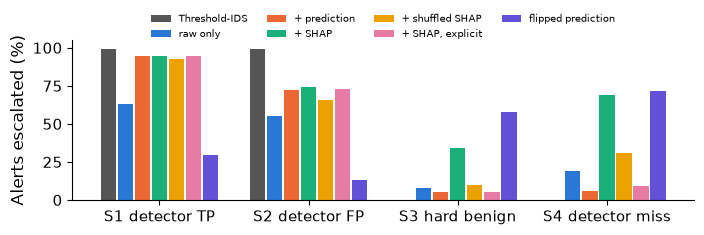

In [19]:
# ============================================================
# CELL 16c — v3: controlled explanation experiments (evaluation)
# ============================================================
# Every condition shows the SAME raw measurements; conditions differ only in the
# detector information added (see Cell 2, CFG['v3']).
# Statistics:
#   * one decision per alert = majority vote over the decoding seeds (also per seed)
#   * exact McNemar on paired decisions, Holm correction over the planned family
#   * paired bootstrap CIs for differences in F1 / recall / FPR, stratified by stratum
#   * cluster (episode) bootstrap: flows of the same day + class + capture block
#     are resampled together
#   * population estimates with design weights (stratum x class), which undo the
#     over-sampling of detector errors and the per-class balancing inside S1
from scipy.stats import binomtest

V3_TAB = PATHS['results_tables'] / 'v3' / MODEL_SLUG; V3_TAB.mkdir(parents=True, exist_ok=True)
V3_FIG = PATHS['results_figures'] / 'v3'; V3_FIG.mkdir(parents=True, exist_ok=True)
NB3 = max(1000, CFG['evaluation']['bootstrap'])
TAU = CFG['experiments']['threshold_ids_conf']
COH = cohort.set_index('alert_id')

def load_recs(path):
    return {r['alert_id']: r for r in json.loads(Path(path).read_text())} if Path(path).exists() else {}

def esc_from(rec):
    st = rec.get('coordinator') if rec.get('coordinator') else rec.get('triage')
    return int(bool((st or {}).get('escalate', True)))

def counts(e, y, w=None):
    w = np.ones(len(y)) if w is None else w
    tp = float((w * ((e == 1) & (y == 1))).sum()); fp = float((w * ((e == 1) & (y == 0))).sum())
    fn = float((w * ((e == 0) & (y == 1))).sum()); tn = float((w * ((e == 0) & (y == 0))).sum())
    return tp, fp, fn, tn

def metr(e, y, w=None):
    tp, fp, fn, tn = counts(e, y, w)
    rec = tp / (tp + fn) if tp + fn else np.nan; fpr = fp / (fp + tn) if fp + tn else np.nan
    pre = tp / (tp + fp) if tp + fp else np.nan
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else np.nan
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, recall=100 * rec, fpr=100 * fpr, precision=100 * pre, f1=100 * f1)

def mcnemar(e1, e2, y):
    c1, c2 = (e1 == y), (e2 == y)
    b, c = int((c1 & ~c2).sum()), int((~c1 & c2).sum())
    return b, c, (binomtest(b, b + c).pvalue if b + c else 1.0)

def holm(pvals):
    p = np.asarray(pvals, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(o):
        run = max(run, min(1.0, (m - r) * p[i])); adj[i] = run
    return adj

def paired_boot(e1, e2, y, strata, groups=None, B=NB3, seed=0):
    """CI of metric(e1) - metric(e2). Resamples alerts within strata, or whole
    groups (episodes) within strata when `groups` is given."""
    rng = np.random.default_rng(seed)
    units = groups if groups is not None else np.arange(len(y)).astype(str)
    by_s = {}
    for s_ in np.unique(strata):
        u = np.unique(units[strata == s_]); by_s[s_] = [np.where((units == g) & (strata == s_))[0] for g in u]
    out = {'f1': [], 'recall': [], 'fpr': []}
    for _ in range(B):
        ii = np.concatenate([np.concatenate([grp[j] for j in rng.integers(0, len(grp), len(grp))])
                             for grp in by_s.values()])
        m1, m2 = metr(e1[ii], y[ii]), metr(e2[ii], y[ii])
        for k in out:
            out[k].append(m1[k] - m2[k])
    return {k: (float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))) for k, v in out.items()}

if CFG['v3']['enabled'] and V3_FILES:
    R3 = {k: load_recs(p) for k, p in V3_FILES.items()}
    R3 = {k: v for k, v in R3.items() if v}
    ids3 = [a for a in cohort['alert_id'] if all(a in r for r in R3.values())]
    print(f'v3 evaluation of {MODEL_SLUG}: {len(R3)} runs, {len(ids3)} alerts common to all runs')
    y3 = COH.loc[ids3, 'is_attack'].to_numpy()
    st3 = COH.loc[ids3, 'stratum'].to_numpy()
    w3 = COH.loc[ids3, 'pop_weight'].to_numpy()
    ep3 = COH.loc[ids3, 'episode'].to_numpy() if 'episode' in COH.columns else None
    det3 = (((COH.loc[ids3, 'ml_pred'] != 'BENIGN') & (COH.loc[ids3, 'ml_conf'] > TAU)).astype(int)).to_numpy()
    E3 = {k: np.array([esc_from(r[a]) for a in ids3]) for k, r in R3.items()}

    # ---- majority vote over seeds per (condition, prompt set, stages) -----
    groups = {}
    for k, r in V3_RUNS.items():
        if k in E3:
            groups.setdefault((r['condition'], r['prompt_set'], r['stages']), []).append(k)
    VOTE = {g: (np.mean([E3[k] for k in ks], axis=0) >= 0.5).astype(int) for g, ks in groups.items()}
    SYS3 = {'Threshold-IDS': det3, **{f'{c}|{p}|{s}': v for (c, p, s), v in VOTE.items()}}

    # ---- table 1: every condition (vote) + per-seed spread ----------------
    rows = []
    for name, e in SYS3.items():
        m = metr(e, y3); mw = metr(e, y3, w3)
        row = {'system': name, **{k: round(v, 1) for k, v in m.items()},
               'fprr_vs_detector_%': round(100 * (metr(det3, y3)['FP'] - m['FP']) / max(metr(det3, y3)['FP'], 1), 1),
               'same_decision_as_detector_%': round(100 * (e == det3).mean(), 1),
               'pop_recall_%': round(mw['recall'], 2), 'pop_precision_%': round(mw['precision'], 2),
               'pop_escalations': round(mw['TP'] + mw['FP'])}
        if name != 'Threshold-IDS':
            c, p, s = name.split('|')
            f1s = [metr(E3[k], y3)['f1'] for k in groups[(c, p, s)]]
            row['f1_seed_sd'] = round(float(np.std(f1s)), 2) if len(f1s) > 1 else np.nan
            row['seed_agreement_%'] = round(100 * float(np.mean(np.all(
                np.array([E3[k] for k in groups[(c, p, s)]]) == E3[groups[(c, p, s)][0]], axis=0))), 1)
        rows.append(row)
    V3_TABLE = pd.DataFrame(rows).set_index('system')
    V3_TABLE.to_csv(V3_TAB / 'conditions_alert_level.csv')
    print('\nAlert-level metrics per condition (majority vote over seeds):')
    print(V3_TABLE[['TP', 'FP', 'FN', 'TN', 'recall', 'fpr', 'f1', 'fprr_vs_detector_%',
                    'same_decision_as_detector_%', 'seed_agreement_%']].to_string())

    # ---- table 2: escalation rate per stratum -------------------------------
    strat = pd.DataFrame({n: pd.Series(e).groupby(st3).mean().mul(100).round(1) for n, e in SYS3.items()})
    strat.to_csv(V3_TAB / 'conditions_by_stratum.csv')
    print('\nEscalation rate (%) by stratum:'); print(strat.T.to_string())

    # ---- table 3: planned comparisons (P1, Triage) with Holm ---------------
    def V(c, p='P1', s='triage'):
        return VOTE.get((c, p, s))
    family = [('pred', 'raw', 'detector output added to raw measurements'),
              ('pred_shap', 'pred', 'genuine SHAP added'),
              ('pred_shuffled', 'pred', 'uninformative (shuffled) attributions added'),
              ('pred_shap', 'pred_shuffled', 'genuine vs shuffled attributions'),
              ('pred_shap_explicit', 'pred_shap', 'explicit SHAP wording'),
              ('flipped', 'pred', 'detector decision inverted')]
    family += [(c, 'DETECTOR', 'vs. Threshold-IDS') for c in CFG['v3']['conditions']]
    comp = []
    for a, b, what in family:
        ea = V(a); eb = det3 if b == 'DETECTOR' else V(b)
        if ea is None or eb is None:
            continue
        n1, n2, p = mcnemar(ea, eb, y3)
        ci = paired_boot(ea, eb, y3, st3, seed=1)
        cie = paired_boot(ea, eb, y3, st3, groups=ep3, seed=2) if ep3 is not None else {'f1': (np.nan, np.nan)}
        ma, mb = metr(ea, y3), metr(eb, y3)
        comp.append({'comparison': f'{a} vs {"Threshold-IDS" if b == "DETECTOR" else b}', 'what': what,
                     'only_first_correct': n1, 'only_second_correct': n2, 'p_mcnemar': p,
                     'dF1': round(ma['f1'] - mb['f1'], 2), 'dF1_95ci': f'[{ci["f1"][0]:.1f}, {ci["f1"][1]:.1f}]',
                     'dF1_95ci_episode': f'[{cie["f1"][0]:.1f}, {cie["f1"][1]:.1f}]',
                     'dRecall': round(ma['recall'] - mb['recall'], 2), 'dRecall_95ci': f'[{ci["recall"][0]:.1f}, {ci["recall"][1]:.1f}]',
                     'dFPR': round(ma['fpr'] - mb['fpr'], 2), 'dFPR_95ci': f'[{ci["fpr"][0]:.1f}, {ci["fpr"][1]:.1f}]'})
    COMP3 = pd.DataFrame(comp)
    if len(COMP3):
        COMP3['p_holm'] = holm(COMP3['p_mcnemar']).round(5)
        COMP3['significant_holm_0.05'] = COMP3['p_holm'] < 0.05
        COMP3.to_csv(V3_TAB / 'planned_comparisons.csv', index=False)
        print('\nPlanned comparisons (P1, Triage; Holm over the whole family):')
        print(COMP3[['comparison', 'only_first_correct', 'only_second_correct', 'p_mcnemar', 'p_holm',
                     'dF1', 'dF1_95ci', 'dF1_95ci_episode', 'dFPR', 'dFPR_95ci']].to_string(index=False))

    # ---- table 4: prompt robustness (P2 vs P1) ---------------------------------
    pr = []
    for c in CFG['v3']['p2_conditions']:
        e1, e2 = V(c, 'P1'), V(c, 'P2')
        if e1 is None or e2 is None:
            continue
        m1, m2 = metr(e1, y3), metr(e2, y3)
        pr.append({'condition': c, 'agreement_P1_P2_%': round(100 * (e1 == e2).mean(), 1),
                   'F1_P1': round(m1['f1'], 1), 'F1_P2': round(m2['f1'], 1),
                   'FPR_P1': round(m1['fpr'], 1), 'FPR_P2': round(m2['fpr'], 1)})
    if pr:
        PR3 = pd.DataFrame(pr); PR3.to_csv(V3_TAB / 'prompt_robustness.csv', index=False)
        if V('pred_shap', 'P2') is not None and V('pred', 'P2') is not None:
            d1 = metr(V('pred_shap'), y3)['f1'] - metr(V('pred'), y3)['f1']
            d2 = metr(V('pred_shap', 'P2'), y3)['f1'] - metr(V('pred', 'P2'), y3)['f1']
            print(f'\nSHAP effect on F1 (pred_shap - pred): P1 {d1:+.1f}, P2 {d2:+.1f} '
                  f'({"same direction" if np.sign(d1) == np.sign(d2) else "DIRECTION CHANGES"})')
        print('Prompt robustness:'); print(PR3.to_string(index=False))

    # ---- table 5: label following (flipped vs genuine detector output) ------
    if V('flipped') is not None and V('pred') is not None:
        lab_att = (COH.loc[ids3, 'ml_pred'] != 'BENIGN').astype(int).to_numpy()
        follow_gen = (V('pred') == lab_att).mean(); follow_flip = (V('flipped') == (1 - lab_att)).mean()
        LF = pd.DataFrame([{'follows_genuine_label_%': round(100 * follow_gen, 1),
                            'follows_flipped_label_%': round(100 * follow_flip, 1),
                            'decision_changed_by_flip_%': round(100 * (V('flipped') != V('pred')).mean(), 1),
                            'raw_only_agrees_with_detector_%': round(100 * (V('raw') == lab_att).mean(), 1)
                            if V('raw') is not None else np.nan}])
        LF.to_csv(V3_TAB / 'label_following.csv', index=False)
        print('\nLabel following:'); print(LF.to_string(index=False))

    # ---- table 6: validity + SHAP mentions in rationales ------------------------
    val = []
    for k, r in R3.items():
        recs = [r[a] for a in ids3]
        val.append({'run': k, 'valid_first_try_%': round(100 * np.mean([x['triage_meta']['valid_first_try'] for x in recs]), 2),
                    'fallback_%': round(100 * np.mean([x['triage_meta']['fallback'] for x in recs]), 2),
                    'mentions_shap_or_attribution_%': round(100 * np.mean([bool(re.search(r'shap|attribution', str(x['triage'].get('reasoning', '')), re.I)) for x in recs]), 1),
                    'mentions_detector_or_confidence_%': round(100 * np.mean([bool(re.search(r'detector|confidence|predicted', str(x['triage'].get('reasoning', '')), re.I)) for x in recs]), 1)})
    pd.DataFrame(val).to_csv(V3_TAB / 'validity_and_mentions.csv', index=False)

    # ---- full pipeline (v3): does the Coordinator ever change Triage? --------
    for k, r in R3.items():
        if V3_RUNS[k]['stages'] == 'full':
            tri = np.array([int(bool(r[a]['triage']['escalate'])) for a in ids3])
            print(f'{k}: coordinator escalation == triage escalation on {100 * (tri == E3[k]).mean():.1f}% of alerts')

    # ---- figure: escalation per stratum by condition --------------------------
    show = [s_ for s_ in ['raw|P1|triage', 'pred|P1|triage', 'pred_shap|P1|triage', 'pred_shuffled|P1|triage',
                          'pred_shap_explicit|P1|triage', 'flipped|P1|triage'] if s_ in SYS3]
    lab = {'raw|P1|triage': 'raw only', 'pred|P1|triage': '+ prediction', 'pred_shap|P1|triage': '+ SHAP',
           'pred_shuffled|P1|triage': '+ shuffled SHAP', 'pred_shap_explicit|P1|triage': '+ SHAP, explicit',
           'flipped|P1|triage': 'flipped prediction'}
    cols = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6']
    order_s = ['S1_attack_flagged', 'S2_ml_false_positive', 'S3_hard_benign', 'S4_ml_miss']
    fig, ax = plt.subplots(figsize=(7.2, 2.6))
    xs = np.arange(4); wbar = 0.8 / (len(show) + 1)
    ax.bar(xs - 0.4 + wbar / 2, [strat.loc[s_, 'Threshold-IDS'] if s_ in strat.index else 0 for s_ in order_s],
           wbar * 0.9, color='#555555', label='Threshold-IDS')
    for k, (name, col) in enumerate(zip(show, cols)):
        ax.bar(xs - 0.4 + wbar * (k + 1.5), [strat.loc[s_, name] if s_ in strat.index else 0 for s_ in order_s],
               wbar * 0.9, color=col, label=lab[name])
    ax.set_xticks(xs); ax.set_xticklabels(['S1 detector TP', 'S2 detector FP', 'S3 hard benign', 'S4 detector miss'])
    ax.set_ylabel('Alerts escalated (%)'); ax.set_ylim(0, 105)
    ax.legend(ncol=4, fontsize=7, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 1.22))
    for s_ in ('top', 'right'): ax.spines[s_].set_visible(False)
    fig.tight_layout(); fig.savefig(V3_FIG / f'conditions_by_stratum_{MODEL_SLUG}.pdf', bbox_inches='tight')
    fig.savefig(V3_FIG / f'conditions_by_stratum_{MODEL_SLUG}.png', dpi=200, bbox_inches='tight'); plt.show()
else:
    print('v3 disabled or no v3 runs yet.')


Agent vs. detector thresholds selected on the dev pool (cohort metrics; pop = design-weighted):
                       agent                               policy    tau    TP    FP  recall  fpr   f1  pop_recall_%  pop_FP  p_mcnemar_vs_agent  dF1_vs_agent_95ci
               raw|P1|triage                         agent itself    NaN 117.0 119.0    56.2 39.7 52.7         76.39    4990                 NaN                   
               raw|P1|triage            threshold, matched recall 1.0000 118.0   0.0    56.7  0.0 72.4         81.12       0        1.214542e-17 +19.7 [12.8, 26.2]
               raw|P1|triage          threshold, matched workload 0.9999 118.0   0.0    56.7  0.0 72.4         81.12       0        1.214542e-17 +19.7 [12.8, 26.2]
               raw|P1|triage per-class thresholds, matched recall    NaN 126.0   2.0    60.6  0.7 75.0         88.54      87        7.507969e-20 +22.3 [15.5, 28.6]
               raw|P1|triage threshold (matched recall) AND agent 1.0000  74.0   0.0

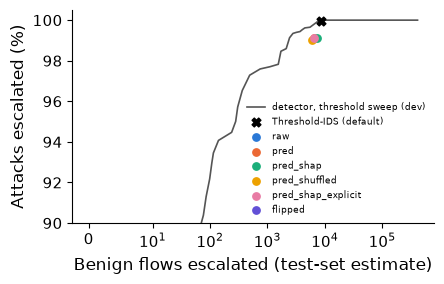

In [20]:
# ============================================================
# CELL 16d — Is the agent better than a TUNED detector threshold?
# ============================================================
# Thresholds are selected on a development pool = all test rows NOT in the
# cohort (disjoint from the evaluated alerts), then applied to the cohort.
#   matched recall   : highest P(attack) threshold whose dev recall >= the agent's
#                      estimated population recall
#   matched workload : threshold whose dev escalation count = the agent's estimated
#                      population escalations
#   per-class        : one threshold per predicted class (Lagrangian sweep on dev),
#                      the strongest simple detector-side baseline
# Population estimates use the design weights (Cell 16c); flows outside the
# cohort strata (benign, not flagged, P(attack) < grey-zone bound) are closed
# by every system.
if CFG['v3']['enabled'] and 'SYS3' in globals():
    dev = np.ones(len(y_test), bool); dev[cohort['test_pos'].to_numpy()] = False
    y_dev = (y_test[dev] != BENIGN_ID).astype(int); p_dev = p_attack_all[dev]
    pc_dev = pred_all[dev]
    scale = (len(y_test) - len(cohort)) / max(dev.sum(), 1)      # ~1: dev ≈ test minus cohort
    P_att_pop = float(COH.loc[ids3].groupby('stratum')['pop_weight'].sum().reindex(
        ['S1_attack_flagged', 'S4_ml_miss']).fillna(0).sum())
    thr_grid = np.unique(np.quantile(p_dev, np.linspace(0, 1, 4001)))
    order = np.argsort(-p_dev); ps_sorted = p_dev[order]; ys_sorted = y_dev[order]
    ctp = np.cumsum(ys_sorted); cfp = np.cumsum(1 - ys_sorted)

    def dev_at(tau):
        k = np.searchsorted(-ps_sorted, -tau, side='right')       # rows with p >= tau
        tp = ctp[k - 1] if k else 0; fp = cfp[k - 1] if k else 0
        return tp / max(y_dev.sum(), 1), fp, tp + fp

    def tau_matched_recall(target):
        best = 0.0
        for t in thr_grid:
            if dev_at(t)[0] >= target:
                best = max(best, t)
        return best

    def tau_matched_workload(target_esc):
        esc = np.array([dev_at(t)[2] for t in thr_grid])
        return float(thr_grid[np.argmin(np.abs(esc - target_esc / scale))])

    def per_class_policy(target_recall):
        classes = np.unique(pc_dev); best = None
        for lam in [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]:
            taus = {}
            for c in classes:
                m = pc_dev == c; pp, yy = p_dev[m], y_dev[m]
                cand = np.unique(np.quantile(pp, np.linspace(0, 1, 201))) if m.sum() else [1.0]
                score = [((pp >= t) & (yy == 1)).sum() - lam * ((pp >= t) & (yy == 0)).sum() for t in cand]
                taus[int(c)] = float(cand[int(np.argmax(score))])
            tau_arr = np.array([taus.get(c, 1.0) for c in range(len(le.classes_))])
            e = p_dev >= tau_arr[pc_dev]
            rec = (e & (y_dev == 1)).sum() / max(y_dev.sum(), 1); fp = (e & (y_dev == 0)).sum()
            if rec >= target_recall and (best is None or fp < best[1]):
                best = (taus, fp, rec, lam)
        return best

    p_coh = COH.loc[ids3, 'p_attack'].to_numpy(); pc_coh = np.array([int(le.transform([c])[0])
                                                                      for c in COH.loc[ids3, 'ml_pred']])
    rows, curves = [], []
    targets = [n for n in SYS3 if n.endswith('|P1|triage') or n.endswith('|P1|full')]
    for name in targets:
        e_ag = SYS3[name]; mw = metr(e_ag, y3, w3)
        rec_pop = mw['TP'] / P_att_pop; esc_pop = mw['TP'] + mw['FP']
        t_r = tau_matched_recall(rec_pop); t_w = tau_matched_workload(esc_pop)
        pcl = per_class_policy(rec_pop)
        pols = {'threshold, matched recall': (p_coh >= t_r).astype(int),
                'threshold, matched workload': (p_coh >= t_w).astype(int)}
        if pcl:
            tau_arr = np.array([pcl[0].get(c, 1.0) for c in range(len(le.classes_))])
            pols['per-class thresholds, matched recall'] = (p_coh >= tau_arr[pc_coh]).astype(int)
        pols['threshold (matched recall) AND agent'] = ((p_coh >= t_r) & (e_ag == 1)).astype(int)
        base = metr(e_ag, y3)
        rows.append({'agent': name, 'policy': 'agent itself', 'tau': np.nan, **{k: round(base[k], 1) for k in
                     ['TP', 'FP', 'recall', 'fpr', 'f1']}, 'pop_recall_%': round(100 * rec_pop, 2),
                     'pop_FP': round(mw['FP']), 'p_mcnemar_vs_agent': np.nan, 'dF1_vs_agent_95ci': ''})
        for pol, e in pols.items():
            m = metr(e, y3); mwp = metr(e, y3, w3)
            n1, n2, p = mcnemar(e, e_ag, y3); ci = paired_boot(e, e_ag, y3, st3, B=max(500, NB3 // 2), seed=3)
            rows.append({'agent': name, 'policy': pol,
                         'tau': round(t_r if 'recall' in pol and 'per-class' not in pol else t_w if 'workload' in pol else np.nan, 4),
                         **{k: round(m[k], 1) for k in ['TP', 'FP', 'recall', 'fpr', 'f1']},
                         'pop_recall_%': round(100 * mwp['TP'] / P_att_pop, 2), 'pop_FP': round(mwp['FP']),
                         'p_mcnemar_vs_agent': p, 'dF1_vs_agent_95ci': f'{m["f1"] - base["f1"]:+.1f} [{ci["f1"][0]:.1f}, {ci["f1"][1]:.1f}]'})
    TUNED = pd.DataFrame(rows)
    TUNED.to_csv(V3_TAB / 'tuned_detector_baselines.csv', index=False)
    print('Agent vs. detector thresholds selected on the dev pool (cohort metrics; pop = design-weighted):')
    print(TUNED.to_string(index=False))

    # ---- figure: detector operating curve on dev vs agent points (population) ----
    fig, ax = plt.subplots(figsize=(4.6, 3.0))
    fr = [(dev_at(t)[1] * scale, 100 * dev_at(t)[0]) for t in thr_grid[::4]]
    ax.plot([f for f, _ in fr], [r for _, r in fr], color='#555555', lw=1.2, label='detector, threshold sweep (dev)')
    mdet = metr(det3, y3, w3)
    ax.scatter([mdet['FP']], [100 * mdet['TP'] / P_att_pop], marker='X', color='black', s=40, zorder=4,
               label='Threshold-IDS (default)')
    pal = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6']
    for k, name in enumerate([n for n in targets if n.endswith('triage')]):
        mw = metr(SYS3[name], y3, w3)
        ax.scatter([mw['FP']], [100 * mw['TP'] / P_att_pop], color=pal[k % 6], s=28, zorder=3,
                   label=name.split('|')[0])
    ax.set_xscale('symlog', linthresh=10); ax.set_xlabel('Benign flows escalated (test-set estimate)')
    ax.set_ylabel('Attacks escalated (%)')
    ax.set_ylim(max(0, 100 * min(0.95, mdet['TP'] / P_att_pop) - 5), 100.5)
    ax.legend(fontsize=6.5, frameon=False, loc='lower right')
    for s_ in ('top', 'right'): ax.spines[s_].set_visible(False)
    fig.tight_layout(); fig.savefig(V3_FIG / f'tuned_threshold_frontier_{MODEL_SLUG}.pdf', bbox_inches='tight')
    fig.savefig(V3_FIG / f'tuned_threshold_frontier_{MODEL_SLUG}.png', dpi=200, bbox_inches='tight'); plt.show()


In [21]:
# ============================================================
# CELL 16e — Deployment routing: how would missed attacks reach the agent?
# ============================================================
# A deployed agent cannot pick the detector's misses by their true label. We
# evaluate explicit routing policies on the WHOLE test set (499,596 flows ≈ the
# volume of one capture day, since the test set is a 20% sample of five days):
#   Q0  flagged only      : the agent reviews what the detector flags
#   Q1  flagged + grey    : also unflagged flows with P(attack) >= grey-zone bound
# Agent decisions come from the cohort; each (stratum, class) cell's escalation
# rate is applied to that cell's population. Misses with P(attack) below the
# bound never reach the agent under either policy.
if CFG['v3']['enabled'] and 'SYS3' in globals():
    g = CFG['v3']['routing_grey_zone']
    flag_all = (pred_all != BENIGN_ID) & (proba_xgb[np.arange(len(pred_all)), pred_all] > TAU)
    is_att_all = y_test != BENIGN_ID
    pred_att_all = pred_all != BENIGN_ID                   # = strata S1/S2 definition
    grey_all = (~pred_att_all) & (p_attack_all >= g)
    n_att = int(is_att_all.sum())
    # latency per alert (batched Triage) from the v3 runs
    tri_t = np.nanmean([np.mean([r[a].get('triage_time', np.nan) for a in ids3]) for k, r in R3.items()
                        if V3_RUNS[k]['stages'] == 'triage']) if R3 else np.nan
    # population of each routing cell, by true class
    cells = {'flagged': pred_att_all, 'grey': grey_all}
    sub = COH.loc[ids3].copy()
    sub['routed_cell'] = np.where(sub['stratum'].isin(['S1_attack_flagged', 'S2_ml_false_positive']), 'flagged',
                          np.where(sub['p_attack'] >= g, 'grey', 'below'))
    rows = []
    def route_eval(name, e):
        sub['esc'] = e
        rate = sub.groupby(['routed_cell', 'ground_truth'])['esc'].mean()
        out = {}
        for q, use in [('Q0 flagged only', ['flagged']), ('Q1 flagged + grey zone', ['flagged', 'grey'])]:
            tp = fp = routed = 0.0
            for cell in use:
                m = cells[cell]; routed += m.sum()
                for ci, cname in enumerate(le.classes_):
                    n = int((m & (y_test == ci)).sum())
                    if n == 0:
                        continue
                    r = rate.get((cell, cname), np.nan)
                    if np.isnan(r):     # no cohort alert in this cell: fall back to the cell's overall rate
                        r = sub.loc[sub['routed_cell'] == cell, 'esc'].mean() if (sub['routed_cell'] == cell).any() else 1.0
                    if cname == 'BENIGN': fp += r * n
                    else: tp += r * n
            out[q] = dict(routed=routed, tp=tp, fp=fp)
            rows.append({'system': name, 'queue': q, 'flows_reviewed_by_agent': int(routed),
                         'agent_gpu_hours': round(routed * tri_t / 3600, 1) if not np.isnan(tri_t) else np.nan,
                         'analyst_escalations': int(round(tp + fp)), 'false_positives': int(round(fp)),
                         'attacks_escalated': int(round(tp)), 'end_to_end_recall_%': round(100 * tp / n_att, 3)})
    # detector-only references
    for nm, e_full in [('Threshold-IDS (default)', flag_all)]:
        rows.append({'system': nm, 'queue': 'none', 'flows_reviewed_by_agent': 0, 'agent_gpu_hours': 0,
                     'analyst_escalations': int(e_full.sum()), 'false_positives': int((e_full & ~is_att_all).sum()),
                     'attacks_escalated': int((e_full & is_att_all).sum()),
                     'end_to_end_recall_%': round(100 * (e_full & is_att_all).sum() / n_att, 3)})
    for name in [n for n in SYS3 if n.endswith('|P1|triage')]:
        route_eval(name, SYS3[name])
    ROUTE = pd.DataFrame(rows)
    ROUTE.to_csv(V3_TAB / 'routing_policies.csv', index=False)
    print(f'Grey zone: {int(grey_all.sum()):,} unflagged flows with P(attack) >= {g} '
          f'({int((grey_all & is_att_all).sum())} attacks, {int((grey_all & ~is_att_all).sum()):,} benign); '
          f'misses below the bound: {int(((~pred_att_all) & (~grey_all) & is_att_all).sum())}')
    print(f'Mean batched Triage time per alert: {tri_t:.2f} s')
    print(ROUTE.to_string(index=False))


Grey zone: 2,337 unflagged flows with P(attack) >= 0.05 (24 attacks, 2,313 benign); misses below the bound: 8
Mean batched Triage time per alert: 0.65 s
                      system                  queue  flows_reviewed_by_agent  agent_gpu_hours  analyst_escalations  false_positives  attacks_escalated  end_to_end_recall_%
     Threshold-IDS (default)                   none                        0              0.0                93760             8648              85112               99.961
               raw|P1|triage        Q0 flagged only                    93771             16.8                69841             4805              65035               76.382
               raw|P1|triage Q1 flagged + grey zone                    96108             17.2                70029             4990              65038               76.386
              pred|P1|triage        Q0 flagged only                    93771             16.8                90656             6277              84379         

2 models compared on 508 common alerts
SHAP effect per model (pred_shap - pred, P1, Holm over models):
               model  params_B   dF1     dF1_95ci  dFPR    dFPR_95ci  only_shap_correct  only_pred_correct    p_mcnemar  p_holm
Qwen2.5-14B-Instruct      14.7 -6.41 [-9.6, -3.6] 17.00 [12.7, 21.3]                 13                 59 3.808598e-08 0.00000
               phi-4      14.7  1.15  [-0.8, 2.8] 10.67  [7.7, 14.2]                 20                 32 1.263471e-01 0.12635
F1 by model and condition (P1):
condition             flipped  pred  pred_shap  pred_shap_explicit  pred_shuffled   raw
model                                                                                  
Qwen2.5-14B-Instruct     13.2  71.2       64.8                65.7           67.4  65.3
phi-4                    40.9  64.1       65.3                64.3           66.2  52.7

Override rate / precision:
               model  params_B condition  override_rate_%  override_precision_%  detector_FPs_closed_

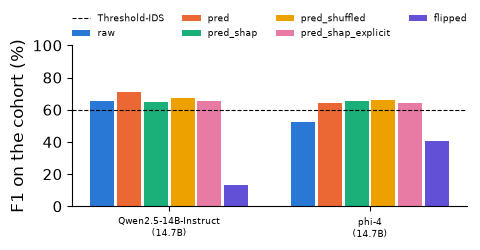

In [22]:
# ============================================================
# CELL 16f — v3: all LLMs on the SAME alerts and the SAME conditions
# ============================================================
# Every folder results/agent_runs/<model>/v3/ is one model. Only alerts present in
# every model's runs are compared, so the rows are paired.
PARAMS_B = {'Qwen2.5-0.5B-Instruct': 0.5, 'Qwen2.5-1.5B-Instruct': 1.5, 'Qwen2.5-3B-Instruct': 3.1,
            'Qwen2.5-7B-Instruct': 7.6, 'Qwen2.5-14B-Instruct': 14.7, 'Qwen2.5-32B-Instruct': 32.5,
            'phi-4': 14.7, 'Phi-4-mini-instruct': 3.8, 'Llama-3.1-8B-Instruct': 8.0,
            'Mistral-Small-24B-Instruct-2501': 23.6, 'gemma-2-9b-it': 9.2}
def _params(slug):
    if slug in PARAMS_B: return PARAMS_B[slug]
    m = re.search(r'(\d+(?:\.\d+)?)B', slug, re.I)
    return float(m.group(1)) if m else np.nan

if CFG['v3']['enabled']:
    MODEL_V3 = {}
    for mdir in sorted(d for d in PATHS['results_runs'].iterdir() if d.is_dir() and (d / 'v3').exists()):
        if mdir.name == 'mock' and CFG['agents']['backend'] != 'mock':
            continue
        runs = {f.stem: load_recs(f) for f in (mdir / 'v3').glob('v3_*_triage_s*.json')}
        if runs:
            MODEL_V3[mdir.name] = runs
    if MODEL_V3:
        common = set(cohort['alert_id'])
        for runs in MODEL_V3.values():
            for r in runs.values():
                common &= set(r)
        idc = [a for a in cohort['alert_id'] if a in common]
        yc = COH.loc[idc, 'is_attack'].to_numpy(); stc = COH.loc[idc, 'stratum'].to_numpy()
        detc = (((COH.loc[idc, 'ml_pred'] != 'BENIGN') & (COH.loc[idc, 'ml_conf'] > TAU)).astype(int)).to_numpy()
        labc = (COH.loc[idc, 'ml_pred'] != 'BENIGN').astype(int).to_numpy()
        print(f'{len(MODEL_V3)} models compared on {len(idc)} common alerts')
        rows, eff_rows = [], []
        for slug, runs in MODEL_V3.items():
            vote = {}
            for name, r in runs.items():
                m = re.match(r'v3_(.+)_(P\d)_triage_s(\d+)', name)
                if m:
                    vote.setdefault((m.group(1), m.group(2)), []).append(np.array([esc_from(r[a]) for a in idc]))
            vote = {k: (np.mean(v, axis=0) >= 0.5).astype(int) for k, v in vote.items()}
            for (cond, ps), e in vote.items():
                mm = metr(e, yc); ov = e != detc
                rows.append({'model': slug, 'params_B': _params(slug), 'condition': cond, 'prompt': ps,
                             'recall': round(mm['recall'], 1), 'fpr': round(mm['fpr'], 1), 'f1': round(mm['f1'], 1),
                             'same_as_detector_%': round(100 * (1 - ov.mean()), 1),
                             'override_rate_%': round(100 * ov.mean(), 1),
                             'override_precision_%': round(100 * (e[ov] == yc[ov]).mean(), 1) if ov.any() else np.nan,
                             'detector_FPs_closed_%': round(100 * ((e == 0) & (stc == 'S2_ml_false_positive')).sum()
                                                            / max((stc == 'S2_ml_false_positive').sum(), 1), 1),
                             'misses_caught_%': round(100 * ((e == 1) & (stc == 'S4_ml_miss')).sum()
                                                      / max((stc == 'S4_ml_miss').sum(), 1), 1)})
            if ('pred_shap', 'P1') in vote and ('pred', 'P1') in vote:
                ci = paired_boot(vote[('pred_shap', 'P1')], vote[('pred', 'P1')], yc, stc, B=max(500, NB3 // 2), seed=5)
                n1, n2, p = mcnemar(vote[('pred_shap', 'P1')], vote[('pred', 'P1')], yc)
                ma, mb = metr(vote[('pred_shap', 'P1')], yc), metr(vote[('pred', 'P1')], yc)
                eff_rows.append({'model': slug, 'params_B': _params(slug), 'dF1': round(ma['f1'] - mb['f1'], 2),
                                 'dF1_95ci': f'[{ci["f1"][0]:.1f}, {ci["f1"][1]:.1f}]',
                                 'dFPR': round(ma['fpr'] - mb['fpr'], 2), 'dFPR_95ci': f'[{ci["fpr"][0]:.1f}, {ci["fpr"][1]:.1f}]',
                                 'only_shap_correct': n1, 'only_pred_correct': n2, 'p_mcnemar': p})
        CROSS = pd.DataFrame(rows)
        EFF = pd.DataFrame(eff_rows)
        if len(EFF):
            EFF['p_holm'] = holm(EFF['p_mcnemar']).round(5)
            EFF.to_csv(PATHS['results_tables'] / 'v3' / 'models_shap_effect.csv', index=False)
            print('SHAP effect per model (pred_shap - pred, P1, Holm over models):'); print(EFF.to_string(index=False))
        CROSS.to_csv(PATHS['results_tables'] / 'v3' / 'models_same_alerts.csv', index=False)
        piv = CROSS[CROSS['prompt'] == 'P1'].pivot_table(index='model', columns='condition', values='f1', aggfunc='first')
        print('F1 by model and condition (P1):'); print(piv.to_string())
        ovp = CROSS[(CROSS['prompt'] == 'P1') & (CROSS['condition'].isin(['raw', 'pred', 'pred_shap']))]
        print('\nOverride rate / precision:'); print(ovp[['model', 'params_B', 'condition', 'override_rate_%',
                                                           'override_precision_%', 'detector_FPs_closed_%', 'misses_caught_%']].to_string(index=False))
        # figure: F1 per condition per model, models ordered by size
        conds = [c for c in ['raw', 'pred', 'pred_shap', 'pred_shuffled', 'pred_shap_explicit', 'flipped'] if c in piv.columns]
        models = sorted(piv.index, key=lambda s_: (_params(s_), s_))
        pal = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6']
        fig, ax = plt.subplots(figsize=(max(5, 1.1 * len(models) + 2), 2.8))
        xs = np.arange(len(models)); wb = 0.8 / max(len(conds), 1)
        for k, c in enumerate(conds):
            ax.bar(xs - 0.4 + wb * (k + 0.5), [piv.loc[m, c] for m in models], wb * 0.9, color=pal[k % 6], label=c)
        ax.axhline(metr(detc, yc)['f1'], color='black', lw=0.8, ls='--', label='Threshold-IDS')
        ax.set_xticks(xs); ax.set_xticklabels([f'{m}\n({_params(m):g}B)' for m in models], fontsize=6.5)
        ax.set_ylabel('F1 on the cohort (%)'); ax.set_ylim(0, 100)
        ax.legend(ncol=4, fontsize=6.5, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 1.25))
        for s_ in ('top', 'right'): ax.spines[s_].set_visible(False)
        fig.tight_layout(); fig.savefig(V3_FIG / 'models_by_condition.pdf', bbox_inches='tight')
        fig.savefig(V3_FIG / 'models_by_condition.png', dpi=200, bbox_inches='tight'); plt.show()
    else:
        print('No v3 runs found yet.')


In [23]:
# ============================================================
# CELL 17 — Blinded expert evaluation of report quality and faithfulness
#   1. EXPORT: a blinded rating sheet (no ground truth, random IDs) + a
#      separate key file. Give the sheet to >= 2 security analysts.
#   2. SCORE: save each completed sheet as expert_ratings_<rater>.csv in
#      results/expert_eval/ and re-run this cell.
# ============================================================
EXP = PATHS['results_expert']
sheet_path, key_path = EXP / 'expert_rating_sheet.csv', EXP / 'expert_key_DO_NOT_SHARE.csv'
RATING_COLS = {
    'q1_disposition_correct':      'Y / N / Unsure — is the report right that this is (or is not) a real attack?',
    'q2_expert_severity':          'Informational / Low / Medium / High / Critical — your own tier',
    'q3_techniques_correct':       'All / Some / None — are the listed ATT&CK techniques correct?',
    'q4_evidence_supports_claims': '1-5 — are the report claims supported by fields of the alert packet?',
    'q5_actionability':            '1-5 — could an analyst act on the recommended actions?',
    'q6_unsupported_claim':        'Y / N — does the report state anything not supported by the alert?',
    'q7_unsafe_action':            'Y / N — would any recommended action cause harm if applied blindly?',
    'comments':                    'free text',
}

if not sheet_path.exists():
    rng = np.random.default_rng(CFG['random_seed'] + 7)
    run = RUNS[MAIN]
    a_pool = [a for a in ids if GT[a] != 'BENIGN']; b_pool = [a for a in ids if GT[a] == 'BENIGN']
    pick = list(rng.choice(a_pool, min(CFG['evaluation']['expert_sheet_attacks'], len(a_pool)), replace=False)) + \
           list(rng.choice(b_pool, min(CFG['evaluation']['expert_sheet_benign'], len(b_pool)), replace=False))
    rng.shuffle(pick)
    rows, keys = [], []
    for k, a in enumerate(pick):
        st = run[a]; co = st['coordinator']; inv = st.get('investigation') or {}
        bid = f'R{k + 1:03d}'
        rows.append({'blind_id': bid,
                     'alert_packet': json.dumps(st['alert'], indent=1),
                     'executive_summary': co['executive_summary'],
                     'final_severity': co['final_severity'], 'disposition': co['disposition'],
                     'escalate': co['escalate'],
                     'attck_techniques': '; '.join(f"{t} {TECH_BY_ID.get(t, {}).get('name', '(unknown ID)')}"
                                                   for t in co['attck_techniques']),
                     'evidence': ' | '.join(inv.get('evidence', [])),
                     'recommended_actions': ' | '.join(co['recommended_actions']),
                     'block_source': st['response']['block_source'],
                     **{c: '' for c in RATING_COLS}})
        keys.append({'blind_id': bid, 'alert_id': a, 'ground_truth': GT[a], 'stratum': coh.loc[a, 'stratum'],
                     'run': MAIN})
    pd.DataFrame(rows).to_csv(sheet_path, index=False)
    pd.DataFrame(keys).to_csv(key_path, index=False)
    (EXP / 'INSTRUCTIONS_for_raters.md').write_text(
        '# SOC-Agent report rating\n\nEach row is one alert packet and the report SOC-Agent wrote for it. '
        'You do not see the true label. Rate every report independently; do not discuss with other raters.\n\n'
        + '\n'.join(f'- **{c}**: {d}' for c, d in RATING_COLS.items())
        + '\n\nATT&CK reference: Enterprise ATT&CK v' + CFG['rag']['attck_version'] + '.\n'
        '\nAlso review `gold_techniques_template.csv` and `severity_rubric_template.csv` and save corrected copies '
        'as `gold_techniques_expert.csv` and `severity_rubric_expert.csv`.\n')
    print(f'✅ Exported {len(rows)} blinded reports -> {sheet_path.name} (+ key, instructions, templates)')

rated = sorted(EXP.glob('expert_ratings_*.csv'))
if not rated:
    print('No completed rating sheets yet (expected results/expert_eval/expert_ratings_<rater>.csv).')
else:
    key = pd.read_csv(key_path)
    R = {p.stem.replace('expert_ratings_', ''): pd.read_csv(p, keep_default_na=False).merge(key, on='blind_id')
         for p in rated}
    out = []
    for name, d in R.items():
        y = lambda c: (d[c].astype(str).str.strip().str.upper().str[0] == 'Y')
        truth_attack = d['ground_truth'] != 'BENIGN'
        out.append({'rater': name, 'n': len(d),
                    'disposition_judged_correct_%': 100 * y('q1_disposition_correct').mean(),
                    'techniques_all_correct_%': 100 * (d['q3_techniques_correct'].astype(str).str.lower().str.startswith('all')).mean(),
                    'evidence_support_mean_1to5': pd.to_numeric(d['q4_evidence_supports_claims'], errors='coerce').mean(),
                    'actionability_mean_1to5': pd.to_numeric(d['q5_actionability'], errors='coerce').mean(),
                    'unsupported_claim_%': 100 * y('q6_unsupported_claim').mean(),
                    'unsafe_action_%': 100 * y('q7_unsafe_action').mean(),
                    'unsafe_action_on_benign_%': 100 * y('q7_unsafe_action')[~truth_attack].mean() if (~truth_attack).any() else np.nan})
    exp_df = pd.DataFrame(out).round(2); exp_df.to_csv(EVAL_DIR / 'expert_ratings_summary.csv', index=False)
    print(exp_df.to_string(index=False))
    if len(R) >= 2:
        (n1, d1), (n2, d2) = list(R.items())[:2]
        m = d1.merge(d2, on='blind_id', suffixes=('_1', '_2'))
        agr = {}
        for c, wt in [('q1_disposition_correct', None), ('q3_techniques_correct', None),
                      ('q4_evidence_supports_claims', 'quadratic'), ('q5_actionability', 'quadratic'),
                      ('q6_unsupported_claim', None), ('q7_unsafe_action', None)]:
            if wt:   # ordinal 1-5 scale
                a1, a2 = pd.to_numeric(m[f'{c}_1'], errors='coerce'), pd.to_numeric(m[f'{c}_2'], errors='coerce')
                ok_ = a1.notna() & a2.notna(); a1, a2 = a1[ok_].astype(int), a2[ok_].astype(int)
            else:
                a1 = m[f'{c}_1'].astype(str).str.strip().str.lower(); a2 = m[f'{c}_2'].astype(str).str.strip().str.lower()
            agr[c] = (round(cohen_kappa_score(a1, a2, weights=wt), 3)
                      if len(a1) > 1 and (a1.nunique() > 1 or a2.nunique() > 1) else np.nan)
        sev_r = [m[f'q2_expert_severity_{i}'].map(lambda s: rank.get(str(s).strip().capitalize(), np.nan)) for i in (1, 2)]
        ok = sev_r[0].notna() & sev_r[1].notna()
        if ok.sum() > 1:
            agr['q2_expert_severity (quadratic)'] = round(cohen_kappa_score(sev_r[0][ok].astype(int), sev_r[1][ok].astype(int),
                                                                            weights='quadratic'), 3)
        pd.Series(agr, name='cohen_kappa').to_csv(EVAL_DIR / 'expert_interrater_agreement.csv')
        print(f'\nInter-rater agreement ({n1} vs {n2}, Cohen kappa):'); print(pd.Series(agr).to_string())


No completed rating sheets yet (expected results/expert_eval/expert_ratings_<rater>.csv).


Sampling cic-ids-2018:   0%|          | 0/10 [00:00<?, ?it/s]

Sampling cic-ids-2018:  10%|█         | 1/10 [00:01<00:16,  1.84s/it]

Sampling cic-ids-2018:  20%|██        | 2/10 [00:03<00:15,  1.92s/it]

Sampling cic-ids-2018:  30%|███       | 3/10 [00:05<00:11,  1.63s/it]

Sampling cic-ids-2018:  40%|████      | 4/10 [00:06<00:09,  1.62s/it]

Sampling cic-ids-2018:  50%|█████     | 5/10 [00:08<00:08,  1.61s/it]

... (3 outputs left out)

Sampling cic-ids-2018:  90%|█████████ | 9/10 [00:15<00:01,  1.78s/it]

Sampling cic-ids-2018: 100%|██████████| 10/10 [00:16<00:00,  1.69s/it]

Sampling cic-ids-2018: 100%|██████████| 10/10 [00:16<00:00,  1.70s/it]

Target rows used: 241,217  |  features missing in cic-ids-2018 (filled with 0): none


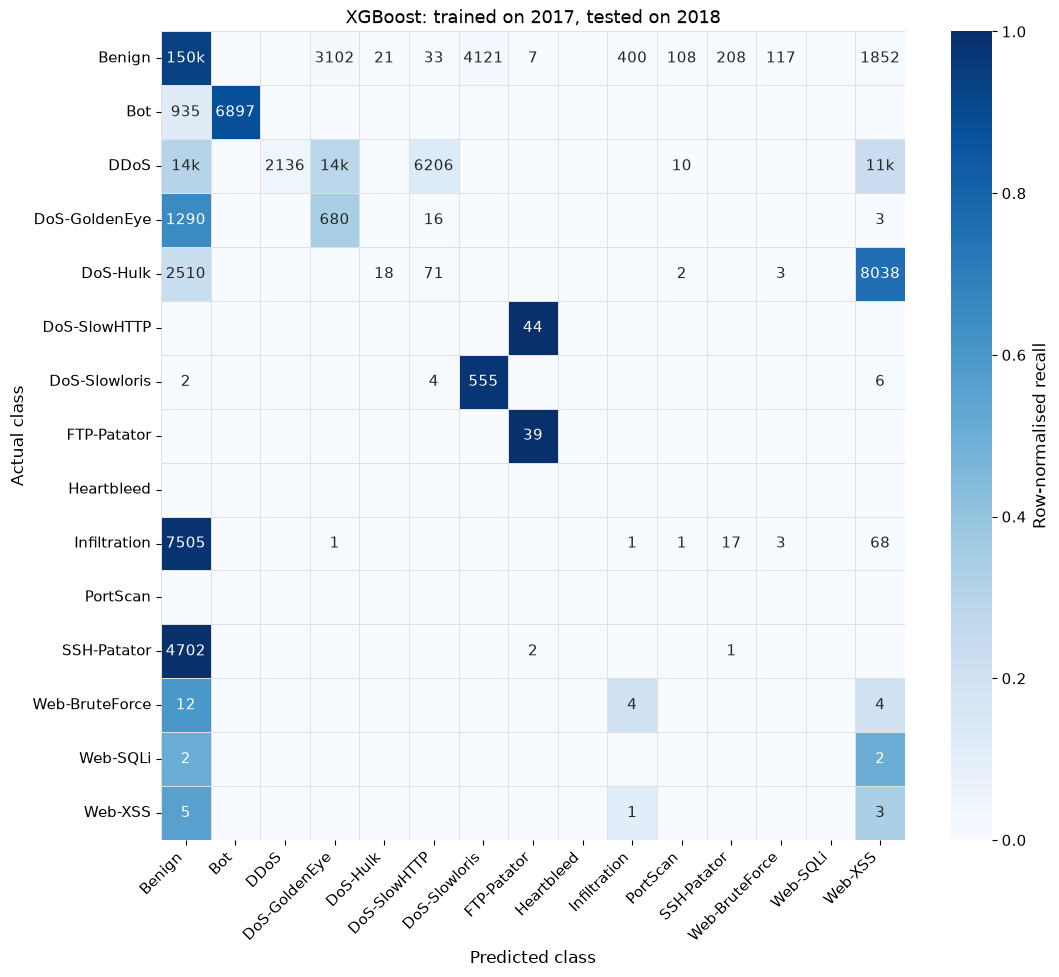

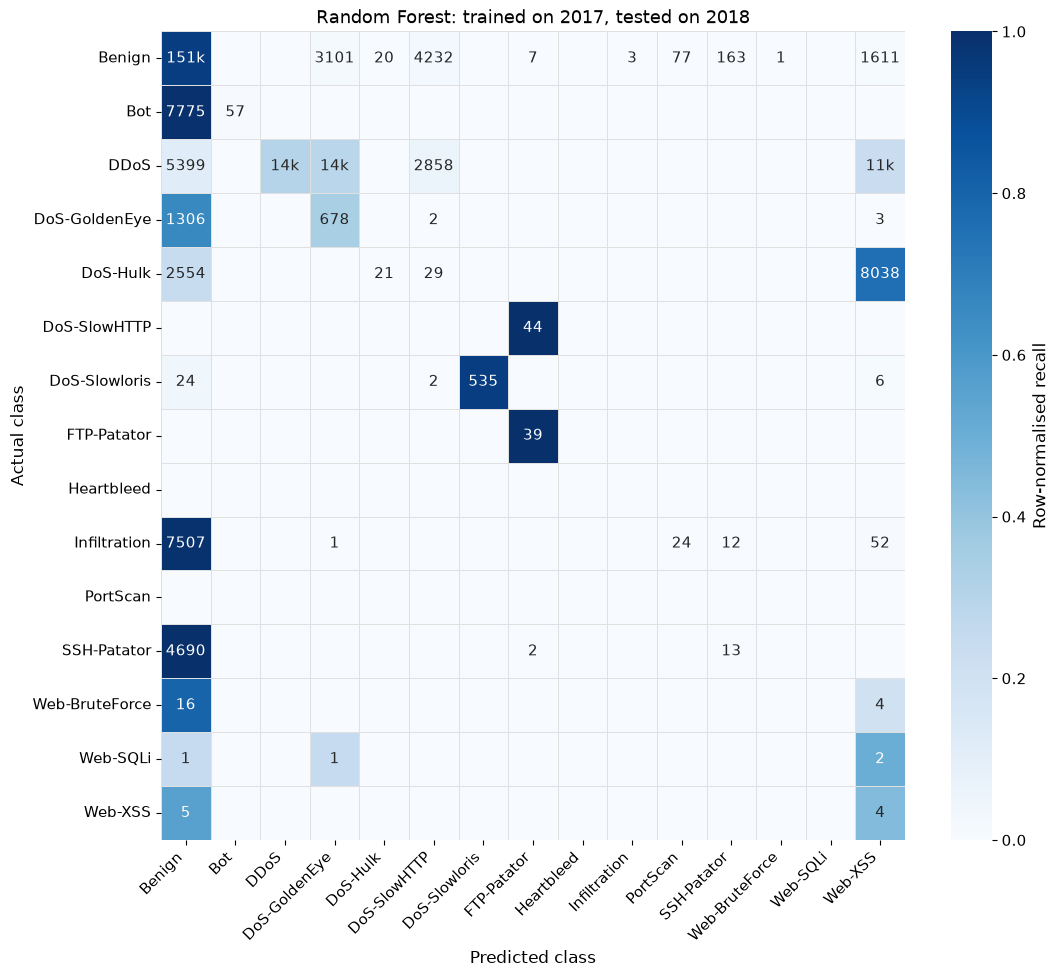

        model                         test   rows  accuracy  weighted_f1  macro_f1_over_present_classes  share_predicted_BENIGN_%
      XGBoost cic-ids-2018 (cross-dataset) 241217     66.54        63.23                          21.40                     75.23
Random Forest cic-ids-2018 (cross-dataset) 241217     69.11        68.44                          23.17                     74.70

Prediction distribution (identical rows explain identical scores):
                          XGBoost  Random Forest
BENIGN                     181475         180197
Bot                          6897             57
DDoS                         2136          14441
DoS GoldenEye               17690          17688
DoS Hulk                       39             41
DoS Slowhttptest             6330           7123
DoS slowloris                4676            535
FTP-Patator                    92             92
Infiltration                  406              3
PortScan                      121            101
SSH

In [24]:
# ============================================================
# CELL 18 — Cross-dataset test: train CIC-IDS2017 -> test CSE-CIC-IDS2018
#   Uses the SAME fitted FeaturePipeline (engineered features are computed
#   from the 2018 columns, not zero-filled) and reports: label mapping,
#   feature compatibility, rows removed by cleaning, per-class precision /
#   recall / support, and each model's prediction distribution.
# ============================================================
TARGET = 'cic-ids-2018' if PRIMARY_DATASET == 'cic-ids-2017' else 'cic-ids-2017'
MAX_TARGET_ROWS, CHUNK = 300_000, 200_000
TARGET_SAMPLE_FRAC = 0.05            # sampled from every chunk so all capture days are represented
XD = PATHS['results_tables'] / 'cross_dataset'; XD.mkdir(exist_ok=True)

files_t = sorted(Path(RAW_DIRS[TARGET]).glob('*.csv')) if RAW_DIRS.get(TARGET) else []
if not files_t:
    print(f'{TARGET} is not attached (Add Input -> solarmainframe/ids-intrusion-csv) — cross-dataset test skipped.')
else:
    quota = MAX_TARGET_ROWS // len(files_t); parts = []
    for f in tqdm(files_t, desc=f'Sampling {TARGET}'):
        got = 0
        try:
            reader = pd.read_csv(f, low_memory=False, chunksize=CHUNK, on_bad_lines='skip')
            for ch in reader:
                ch.columns = ch.columns.str.strip()
                ch = ch.rename(columns={k: v for k, v in COLUMN_RENAME_2018.items() if k in ch.columns})
                s = ch.sample(frac=TARGET_SAMPLE_FRAC, random_state=CFG['random_seed'])
                s['__file__'] = f.name; s['__day__'] = f.name.split('-')[0]; s['__order__'] = s.index
                parts.append(s); got += len(s)
                if got >= quota: break
        except Exception as e:
            print(f'  skipped {f.name}: {e}')
    df_t = pd.concat(parts, ignore_index=True); del parts
    raw_labels = df_t['Label'].astype(str).str.strip().value_counts()
    acct_t = []
    df_t = clean_rows(df_t, CFG, TARGET, acct_t)
    known = set(le.classes_)
    mapping = pd.DataFrame({'raw_label': raw_labels.index, 'rows_sampled': raw_labels.values})
    mapping['mapped_to'] = mapping['raw_label'].map(lambda x: normalize_label(x, TARGET))
    mapping['used'] = mapping['mapped_to'].isin(known)
    mapping.to_csv(XD / 'label_mapping.csv', index=False)
    df_t = df_t[df_t['Label'].isin(known)].reset_index(drop=True)
    acct_t.append({'step': 'after keeping classes known to the model', 'rows': len(df_t),
                   **df_t['Label'].value_counts().to_dict()})
    pd.DataFrame(acct_t).fillna(0).set_index('step').T.to_csv(XD / 'accounting.csv')

    feat_cols_t = [c for c in df_t.columns if c not in META_COLS + ['Label']]
    Xt = fpipe.transform(df_t[feat_cols_t], report_missing=True)
    missing = fpipe.last_missing
    pd.DataFrame({'feature': fpipe.features,
                  'available_in_target': [f not in missing for f in fpipe.features]}).to_csv(
        XD / 'feature_compatibility.csv', index=False)
    print(f'Target rows used: {len(df_t):,}  |  features missing in {TARGET} (filled with 0): {missing or "none"}')
    yt = le.transform(df_t['Label'])

    rows, dist = [], {}
    for name, model in [('XGBoost', xgb_model), ('Random Forest', rf_model)]:
        yp = model.predict(Xt)
        dist[name] = pd.Series(le.classes_[yp]).value_counts()
        rows.append({'model': name, 'test': f'{TARGET} (cross-dataset)', 'rows': len(yt),
                     'accuracy': 100 * accuracy_score(yt, yp),
                     'weighted_f1': 100 * f1_score(yt, yp, average='weighted', zero_division=0),
                     'macro_f1_over_present_classes': 100 * f1_score(yt, yp, average='macro',
                                                                     labels=sorted(set(yt)), zero_division=0),
                     'share_predicted_BENIGN_%': 100 * (yp == BENIGN_ID).mean()})
        pc = per_class_table(yt, yp, le.classes_); pc = pc[pc['support'] > 0]
        pc.to_csv(XD / f'per_class_{name.lower().replace(" ", "_")}.csv', index=False)
        plot_confusion(yt, yp, le.classes_, f'{name}: trained on 2017, tested on 2018',
                       f'confusion_cross_{name.lower().replace(" ", "_")}')
    xres = pd.DataFrame(rows).round(2); xres.to_csv(XD / 'summary.csv', index=False)
    pd.DataFrame(dist).fillna(0).astype(int).to_csv(XD / 'prediction_distribution.csv')
    print(xres.to_string(index=False))
    print('\nPrediction distribution (identical rows explain identical scores):')
    print(pd.DataFrame(dist).fillna(0).astype(int).to_string())
    print('\nTrue class distribution:'); print(df_t['Label'].value_counts().to_string())


In [25]:
# ============================================================
# CELL 18b — v3: the FROZEN agent configurations on a SHIFTED detector
# ============================================================
# The CIC-IDS2017 detector is applied to CSE-CIC-IDS2018 (Cell 18). Its errors
# there are systematic (most attacks predicted BENIGN). We draw a cohort from the
# 2018 flows with the same four strata and run the same conditions, prompts and
# scoring as on CIC-IDS2017, without changing anything in the agents.
SH = CFG['v3']['shift']
if CFG['v3']['enabled'] and SH['enabled'] and 'Xt' in globals():
    SH_TAB = PATHS['results_tables'] / 'v3' / MODEL_SLUG / 'shift_cic2018'; SH_TAB.mkdir(parents=True, exist_ok=True)
    SH_COHORT = PATHS['results_logs'] / 'cohort_shift_cic2018.csv'
    SH_ALERTS = PATHS['results_logs'] / 'alerts_shift_cic2018_v3.json'
    proba_t = xgb_model.predict_proba(Xt); pred_t = proba_t.argmax(1); p_att_t = 1.0 - proba_t[:, BENIGN_ID]
    Xt_un = fpipe.transform(df_t[feat_cols_t], scaled=False)
    ben_t = yt == BENIGN_ID; flag_t = pred_t != BENIGN_ID
    pools_t = {'S1_attack_flagged': np.where(~ben_t & flag_t)[0], 'S2_ml_false_positive': np.where(ben_t & flag_t)[0],
               'S3_hard_benign': np.where(ben_t & ~flag_t & (p_att_t >= CFG['cohort']['hard_benign_min_attack_prob']))[0],
               'S4_ml_miss': np.where(~ben_t & ~flag_t)[0]}
    if SH_COHORT.exists():
        coh_t = pd.read_csv(SH_COHORT)
        if coh_t['row'].max() >= len(yt) or (le.classes_[yt[coh_t['row']]] != coh_t['ground_truth']).any():
            print('⚠️  Cached shift cohort does not match the 2018 sample — rebuilding.'); coh_t = None
            SH_ALERTS.unlink(missing_ok=True)
    else:
        coh_t = None
    if coh_t is None:
        rng_t = np.random.default_rng(CFG['random_seed'] + 18); pick = []
        for c in sorted(set(yt[pools_t['S1_attack_flagged']])):
            pool = pools_t['S1_attack_flagged'][yt[pools_t['S1_attack_flagged']] == c]
            pick += [(int(i), 'S1_attack_flagged') for i in rng_t.choice(pool, min(SH['attack_per_class'], len(pool)), replace=False)]
        for s_ in ['S2_ml_false_positive', 'S3_hard_benign']:
            pool = pools_t[s_]
            pick += [(int(i), s_) for i in rng_t.choice(pool, min(SH[s_], len(pool)), replace=False)] if len(pool) else []
        # misses: up to 20 per class first (classes differ greatly in size), then top up at random
        pool = pools_t['S4_ml_miss']; chosen = []
        for c in sorted(set(yt[pool])):
            pc_ = pool[yt[pool] == c]; chosen += list(rng_t.choice(pc_, min(20, len(pc_)), replace=False))
        rest = np.setdiff1d(pool, chosen)
        if len(chosen) < SH['S4_ml_miss'] and len(rest):
            chosen += list(rng_t.choice(rest, min(SH['S4_ml_miss'] - len(chosen), len(rest)), replace=False))
        pick += [(int(i), 'S4_ml_miss') for i in chosen[:max(SH['S4_ml_miss'], 0)]]
        rng_t.shuffle(pick)
        coh_t = pd.DataFrame(pick, columns=['row', 'stratum'])
        coh_t['alert_id'] = [f'X{k:04d}' for k in range(len(coh_t))]
        coh_t['ground_truth'] = le.classes_[yt[coh_t['row']]]
        coh_t['ml_pred'] = le.classes_[pred_t[coh_t['row']]]
        coh_t['ml_conf'] = proba_t[coh_t['row'], pred_t[coh_t['row']]].round(4)
        coh_t['p_attack'] = p_att_t[coh_t['row']].round(4)
        coh_t['is_attack'] = (coh_t['ground_truth'] != 'BENIGN').astype(int)
        popt = {(s_, c): int((yt[idx] == c).sum()) for s_, idx in pools_t.items() for c in set(yt[idx])}
        coh_t['pop_weight'] = [popt[(s_, int(le.transform([g_])[0]))] for s_, g_ in zip(coh_t['stratum'], coh_t['ground_truth'])]
        coh_t['pop_weight'] = coh_t['pop_weight'] / coh_t.groupby(['stratum', 'ground_truth'])['alert_id'].transform('count')
        coh_t['day'] = df_t.loc[coh_t['row'], '__day__'].astype(str).values
        coh_t['episode'] = (coh_t['day'] + '|' + coh_t['ground_truth'] + '|' +
                            (df_t.loc[coh_t['row'], '__order__'].to_numpy() // CFG['v3']['episode_block']).astype(str))
        coh_t.to_csv(SH_COHORT, index=False)
    print('Shift cohort (CSE-CIC-IDS2018):'); print(coh_t.groupby('stratum').agg(n=('alert_id', 'count'), attacks=('is_attack', 'sum')).to_string())

    # ---- v3 packets for the 2018 alerts (same builder logic as Cell 13) -------
    if not SH_ALERTS.exists():
        rows_ = coh_t['row'].to_numpy()
        sv_t = shap_3d(explainer.shap_values(Xt.iloc[rows_], check_additivity=False), len(le.classes_))
        feats = list(Xt.columns); rng_p = np.random.default_rng(CFG['random_seed'] + 34); pk = {}
        tops = []
        for k, i in enumerate(rows_):
            s_ = sv_t[k, :, int(pred_t[i])]; top = np.argsort(-np.abs(s_))[:5]
            tops.append([{'feature': feats[j], 'shap': f'{float(s_[j]):+.4f}'} for j in top])
        for k, (a, i) in enumerate(zip(coh_t['alert_id'], rows_)):
            un = Xt_un.iloc[i]; rc = df_t.iloc[i]; pred = int(pred_t[i])
            flags = []
            if {'SYN Flag Count', 'ACK Flag Count'} <= set(rc.index) and rc['SYN Flag Count'] >= 1 and rc['ACK Flag Count'] == 0:
                flags.append('SYN without ACK')
            if 'RST Flag Count' in rc.index and rc['RST Flag Count'] >= 1: flags.append('RST set')
            if 'PSH Flag Count' in rc.index and rc['PSH Flag Count'] >= 3: flags.append('PSH >= 3')
            ctx = {'service': _onehot_value(un, 'service_'), 'port_category': _onehot_value(un, 'port_category_'),
                   'duration_bucket': _onehot_value(un, 'duration_bucket_')}
            for col, key, f in [('Destination Port', 'destination_port', int),
                                ('Flow Duration', 'flow_duration_s', lambda v: round(float(v) / 1e6, 3)),
                                ('Total Fwd Packets', 'fwd_packets', int), ('Total Backward Packets', 'bwd_packets', int),
                                ('Flow Bytes/s', 'flow_bytes_per_s', lambda v: round(float(v), 1))]:
                if col in rc.index:
                    try: ctx[key] = _py(f(float(rc[col])))
                    except Exception: pass
            ctx['flag_anomaly'] = ', '.join(flags) if flags else 'None'
            if pred == BENIGN_ID:
                att = [c for c in range(len(le.classes_)) if c != BENIGN_ID]
                flip_lab = str(le.classes_[att[int(np.argmax(proba_t[i, att]))]])
            else:
                flip_lab = 'BENIGN'
            other = int(rng_p.choice([j for j in range(len(rows_)) if j != k])) if len(rows_) > 1 else k
            rnd = rng_p.choice(len(feats), 5, replace=False)
            pk[a] = {'measurements': {f_: _py(round(float(un[f_]), 4)) for f_ in MEAS_FEATURES if f_ in un.index},
                     'context': ctx,
                     'detector': {'predicted_label': str(le.classes_[pred]), 'confidence': round(float(proba_t[i, pred]), 4),
                                  'p_attack': round(float(p_att_t[i]), 4)},
                     'flipped': {'predicted_label': flip_lab, 'confidence': round(float(proba_t[i, pred]), 4),
                                 'p_attack': round(1.0 - float(p_att_t[i]), 4)},
                     'shap': tops[k],
                     'shap_shuffled': [{'feature': feats[j], 'shap': tops[other][m]['shap']} for m, j in enumerate(rnd)]}
        SH_ALERTS.write_text(json.dumps({'ids': coh_t['alert_id'].tolist(), 'alerts': pk,
                                         'gt': dict(zip(coh_t['alert_id'], coh_t['ground_truth']))}, default=str))
    # ---- runs (resumable) ----------------------------------------------------
    SH_DIR = RUN_DIR / 'v3_shift_cic2018'; SH_DIR.mkdir(parents=True, exist_ok=True)
    SH_PLAN = [{'name': f'shift_{c}_P1_triage_s{sd}', 'kind': 'condition', 'condition': c, 'prompt_set': 'P1',
                'stages': 'triage', 'seed': sd, 'n': None, 'n_total': len(coh_t), 'alerts': str(SH_ALERTS),
                'out': str(SH_DIR / f'shift_{c}_P1_triage_s{sd}.json')} for c in SH['conditions'] for sd in SH['seeds']]
    launch_and_wait(SH_PLAN)

    # ---- evaluation: same rules as on CIC-IDS2017 --------------------------------
    CT = coh_t.set_index('alert_id')
    RS = {r['condition']: load_recs(r['out']) for r in SH_PLAN if r['seed'] == SH['seeds'][0]}
    RS = {k: v for k, v in RS.items() if v}
    ids_t = [a for a in coh_t['alert_id'] if all(a in r for r in RS.values())]
    if RS and ids_t:
        yT = CT.loc[ids_t, 'is_attack'].to_numpy(); sT = CT.loc[ids_t, 'stratum'].to_numpy(); wT = CT.loc[ids_t, 'pop_weight'].to_numpy()
        dT = (((CT.loc[ids_t, 'ml_pred'] != 'BENIGN') & (CT.loc[ids_t, 'ml_conf'] > TAU)).astype(int)).to_numpy()
        ET = {'Threshold-IDS': dT, **{c: np.array([esc_from(r[a]) for a in ids_t]) for c, r in RS.items()}}
        rows = []
        for n_, e in ET.items():
            m = metr(e, yT); mw = metr(e, yT, wT)
            rows.append({'system': n_, **{k: round(v, 1) for k, v in m.items()},
                         'same_as_detector_%': round(100 * (e == dT).mean(), 1),
                         'pop_recall_%': round(mw['recall'], 2), 'pop_precision_%': round(mw['precision'], 2)})
        SHT = pd.DataFrame(rows).set_index('system'); SHT.to_csv(SH_TAB / 'conditions_alert_level.csv')
        print('\nShifted detector (2017 model on 2018 flows) — alert-level:'); print(SHT.to_string())
        print('\nEscalation rate (%) by stratum:')
        print(pd.DataFrame({n_: pd.Series(e).groupby(sT).mean().mul(100).round(1) for n_, e in ET.items()}).T.to_string())
        comp = []
        for a, b in [('pred', 'raw'), ('pred_shap', 'pred'), ('pred_shap_explicit', 'pred_shap'),
                     ('raw', 'Threshold-IDS'), ('pred', 'Threshold-IDS'), ('pred_shap', 'Threshold-IDS')]:
            if a in ET and b in ET:
                n1, n2, p = mcnemar(ET[a], ET[b], yT); ci = paired_boot(ET[a], ET[b], yT, sT, B=max(500, NB3 // 2), seed=7)
                comp.append({'comparison': f'{a} vs {b}', 'only_first_correct': n1, 'only_second_correct': n2, 'p_mcnemar': p,
                             'dF1': round(metr(ET[a], yT)['f1'] - metr(ET[b], yT)['f1'], 2),
                             'dF1_95ci': f'[{ci["f1"][0]:.1f}, {ci["f1"][1]:.1f}]',
                             'dRecall': round(metr(ET[a], yT)['recall'] - metr(ET[b], yT)['recall'], 2)})
        if comp:
            CS = pd.DataFrame(comp); CS['p_holm'] = holm(CS['p_mcnemar']).round(5)
            CS.to_csv(SH_TAB / 'planned_comparisons.csv', index=False); print(CS.to_string(index=False))
else:
    print('Shift experiment skipped (v3 shift disabled or CSE-CIC-IDS2018 not available).')


Shift cohort (CSE-CIC-IDS2018):
                        n  attacks
stratum                           
S1_attack_flagged      97       97
S2_ml_false_positive  100        0
S3_hard_benign         50        0
S4_ml_miss            100      100


▶ worker 0 on GPU 4: ['shift_raw_P1_triage_s42', 'shift_pred_P1_triage_s42', 'shift_pred_shap_P1_triage_s42', 'shift_pred_shap_explicit_P1_triage_s42']


[   0.1 min] shift_raw_P1_triage_s42 0/347, shift_pred_P1_triage_s42 0/347, shift_pred_shap_P1_triage_s42 0/347, shift_pred_shap_explicit_P1_triage_s42 0/347
      worker_0: 04:40:07 worker 0 start; CUDA_VISIBLE_DEVICES=4


[   2.1 min] shift_raw_P1_triage_s42 144/347, shift_pred_P1_triage_s42 0/347, shift_pred_shap_P1_triage_s42 0/347, shift_pred_shap_explicit_P1_triage_s42 0/347
      worker_0: 04:42:11 raw/P1/triage seed=42: 144/347 alerts (1.3 min, ETA 1.9 min)


[   4.1 min] shift_pred_P1_triage_s42 16/347, shift_pred_shap_P1_triage_s42 0/347, shift_pred_shap_explicit_P1_triage_s42 0/347
      worker_0: 04:44:09 pred/P1/triage seed=42: 16/347 alerts (0.2 min, ETA 3.3 min)


[   6.1 min] shift_pred_P1_triage_s42 224/347, shift_pred_shap_P1_triage_s42 0/347, shift_pred_shap_explicit_P1_triage_s42 0/347
      worker_0: 04:46:09 pred/P1/triage seed=42: 224/347 alerts (2.2 min, ETA 1.2 min)


... (2 outputs left out)

[  12.1 min] shift_pred_shap_explicit_P1_triage_s42 32/347
      worker_0: 04:52:02 pred_shap_explicit/P1/triage seed=42: 32/347 alerts (0.4 min, ETA 4.0 min)


[  14.1 min] shift_pred_shap_explicit_P1_triage_s42 192/347
      worker_0: 04:54:08 pred_shap_explicit/P1/triage seed=42: 192/347 alerts (2.5 min, ETA 2.0 min)


[  16.1 min] 
      worker_0: 04:56:11 ALL RUNS DONE

Shifted detector (2017 model on 2018 flows) — alert-level:
                       TP     FP     FN    TN  recall   fpr  precision    f1  same_as_detector_%  pop_recall_%  pop_precision_%
system                                                                                                                         
Threshold-IDS        97.0   99.0  100.0  51.0    49.2  66.0       49.5  49.4               100.0         65.18            83.45
raw                  62.0  100.0  135.0  50.0    31.5  66.7       38.3  34.5                42.4         42.85            83.37
pred                 92.0   92.0  105.0  58.0    46.7  61.3       50.0  48.3                56.8         42.98            83.46
pred_shap           127.0  104.0   70.0  46.0    64.5  69.3       55.0  59.3                43.2         47.52            84.48
pred_shap_explicit   88.0   94.0  109.0  56.0    44.7  62.7       48.4  46.4                57.3         41.26         

                     comparison  only_first_correct  only_second_correct    p_mcnemar    dF1      dF1_95ci  dRecall  p_holm
                    pred vs raw                  45                    7 6.973810e-08  13.75   [9.3, 18.3]    15.23 0.00000
              pred_shap vs pred                  35                   12 1.088538e-03  11.05   [7.4, 14.4]    17.77 0.00435
pred_shap_explicit vs pred_shap                  10                   39 3.845912e-05 -12.91 [-16.4, -9.0]   -19.80 0.00019
           raw vs Threshold-IDS                  82                  118 1.313036e-02 -14.82 [-20.3, -8.9]   -17.77 0.03939
          pred vs Threshold-IDS                  76                   74 9.349615e-01  -1.07   [-6.2, 4.0]    -2.54 0.93496
     pred_shap vs Threshold-IDS                 111                   86 8.702127e-02   9.98   [5.1, 14.2]    15.23 0.17404


In [26]:
# ============================================================
# CELL 19 — Export everything (tables, figures, run logs, prompts,
#           manifest, cohort, expert sheets) as one zip
# ============================================================
import zipfile
update_manifest(finished_at=time.strftime('%Y-%m-%d %H:%M:%S'))
zip_path = BASE / f'SOC_Agent_results_local_{time.strftime("%Y%m%d_%H%M")}.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for key, sub in [('results_tables', 'tables'), ('results_figures', 'figures'), ('results_logs', 'logs'),
                     ('results_runs', 'agent_runs'), ('results_expert', 'expert_eval'),
                     ('workers', 'worker_logs')]:
        for f in PATHS[key].rglob('*'):
            if f.is_file() and f.suffix in ('.csv', '.png', '.pdf', '.json', '.md', '.log', '.txt', '.stdout'):
                zf.write(f, f'{sub}/{f.relative_to(PATHS[key])}')
print(f'✅ Results zipped: {zip_path} ({zip_path.stat().st_size / 1e6:.1f} MB)')


✅ Results zipped: /home/jiit_255030001/SOC_Agent/SOC_Agent_results_local_20261027_0456.zip (10.7 MB)


## Where each paper number comes from (all under ~/SOC_Agent/results/)

| Paper item | File (in the exported zip) |
|---|---|
| Dataset section: rows per cleaning step, per class | `tables/dataset_accounting.csv` |
| Split sizes (train / test / after resampling) | `tables/split_accounting_random.csv` |
| Exact feature list with definitions | `tables/final_features.csv` |
| Classifier table + per-class P/R/F1/support with CIs | `tables/model_comparison_random.csv`, `tables/per_class_*.csv` |
| Temporal split / leave-one-day-out | `tables/model_comparison_temporal_xgb.csv`, `tables/leave_one_day_out_*.csv` |
| Alert-level comparison and ablations (main agent table) | `tables/agent_eval/<model>/alert_level_metrics.csv`, `mcnemar_tests.csv`, `escalation_rate_by_stratum.csv` |
| Severity | `tables/agent_eval/<model>/severity_metrics.csv`, `severity_confusion_soc_agent.csv`, `severity_per_tier_soc_agent.csv` |
| ATT&CK correctness and retrieval | `tables/agent_eval/<model>/attck_metrics.csv`, `attck_per_class_soc_agent.csv` |
| Run-to-run variability | `tables/agent_eval/<model>/run_variability.csv` |
| Output validity (parse / retry / fallback) | `tables/agent_eval/<model>/output_validity.csv` |
| Safety of recommendations | `tables/agent_eval/<model>/safety_metrics.csv` |
| Latency (sequential and batched) | `tables/agent_eval/<model>/latency.csv` |
| Models compared on the same alerts | `tables/agent_eval/model_comparison_same_alerts.csv` |
| Renamed SOC-Bench summary | `tables/agent_eval/<model>/socbench_v2_summary.csv` |
| Cross-dataset | `tables/cross_dataset/*.csv` |
| Prompts, model revision, versions, seeds | `logs/prompts.json`, `logs/run_manifest.json` |
| Expert evaluation | `expert_eval/` (sheets, key, templates) and `tables/agent_eval/<model>/expert_*.csv` |

## Troubleshooting (local)
| Problem | Fix |
|---|---|
| Cell 0 says torch cannot see the GPU | Run `nvidia-smi`. If it fails, install the NVIDIA driver (`sudo ubuntu-drivers install`), reboot, and run `setup_env.sh` again |
| `CUDA out of memory` in the worker | Lower `LLM_BATCH` in Cell 2 (16 → 8 → 4) |
| Another program is using the GPU | Check `nvidia-smi`; the worker needs ~12–25 GB free for the 14B model |
| A worker failed | Cell 15 prints its last log lines; full logs: `~/SOC_Agent/workers/worker_0.log` |
| kagglehub asks for credentials | Save your Kaggle API token as `~/.kaggle/kaggle.json` (`chmod 600`), or download the datasets manually into `~/SOC_Agent/input/` |
| Many fallbacks in `output_validity.csv` | Raise `max_new_tokens` for that stage in Cell 2 |
| Changed split / features / cohort settings | Delete `~/SOC_Agent/cache/data/splits`, `results/logs/cohort.csv` and `results/logs/alerts.json` |
| Llama models fail to download | They are gated: accept the licence on huggingface.co and `export HF_TOKEN=...` before starting |


## v3 outputs (review experiments)

| Paper item | File |
|---|---|
| Controlled conditions, alert level (vote over seeds) | `tables/v3/<model>/conditions_alert_level.csv` |
| Escalation per stratum per condition | `tables/v3/<model>/conditions_by_stratum.csv`, `figures/v3/conditions_by_stratum_<model>.pdf` |
| Planned comparisons (McNemar, Holm, bootstrap ΔF1/Δrecall/ΔFPR, episode bootstrap) | `tables/v3/<model>/planned_comparisons.csv` |
| Prompt robustness (P1 vs P2) | `tables/v3/<model>/prompt_robustness.csv` |
| Label following (flipped detector output) | `tables/v3/<model>/label_following.csv` |
| Validity, SHAP mentions | `tables/v3/<model>/validity_and_mentions.csv` |
| Agent vs. tuned detector thresholds (dev-selected) | `tables/v3/<model>/tuned_detector_baselines.csv`, `figures/v3/tuned_threshold_frontier_<model>.pdf` |
| Routing / workload / end-to-end recall | `tables/v3/<model>/routing_policies.csv` |
| All models, same alerts | `tables/v3/models_same_alerts.csv`, `tables/v3/models_shap_effect.csv`, `figures/v3/models_by_condition.pdf` |
| Shifted detector (CSE-CIC-IDS2018) | `tables/v3/<model>/shift_cic2018/*.csv`, `logs/cohort_shift_cic2018.csv` |
| Exact prompts sent to the model | `logs/serialized_prompts_v3.md`, `logs/prompts_v3.json` |
